# NYC Yellow Taxi · Spark y Databricks
## Pipeline distribuido, calidad de datos y análisis geoespacial en Databricks Serverless

Este notebook integra en **Databricks Serverless** el pipeline de referencia desarrollado en entorno local y la capa de calidad de datos y depuración validada posteriormente sobre los viajes de taxi amarillo de Nueva York de enero de 2015.

### Objetivos

- reproducir en Databricks el pipeline distribuido validado previamente en local;
- aplicar criterios explícitos de calidad de datos y depuración de valores extremos;
- analizar patrones estadísticos y temporales sobre el dataset analítico depurado;
- realizar procesamiento geoespacial mediante funciones `ST_*` nativas de Databricks;
- persistir y reutilizar resultados mediante Parquet y Unity Catalog Volumes;
- generar visualizaciones interpretables a partir de resultados agregados;
- analizar el comportamiento de Spark y su plan físico de ejecución en un entorno Serverless.

Los criterios de depuración se evalúan sobre el dataset de referencia antes de aplicarse al dataset analítico. La combinación seleccionada elimina únicamente el **0,0063 %** de los registros, manteniendo prácticamente invariantes las medianas y los percentiles representativos.

Las operaciones de `cache()`, `persist()` y `unpersist()` se mantienen documentadas pero desactivadas debido a las restricciones del compute Serverless utilizado.

## 1. Configuración inicial y entorno

### 1.1. Librerías y estructura del proyecto

El pipeline se ejecuta en **Databricks Free Edition** mediante compute Serverless.

Los datos fuente se almacenan en un **Unity Catalog Volume**, mientras que los resultados de esta implementación se escriben en un volumen asociado al proyecto.

Las funciones auxiliares se mantienen en `src/`, conservando la misma separación entre código reutilizable, datos y resultados utilizada en la implementación local.

In [ ]:
# ============================================================
# LIBRERÍAS
# ============================================================
from pathlib import Path

import io
import sys

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from pyspark.sql import functions as F

from pyspark.sql.types import (
    StructType,
    StructField,
    IntegerType,
    DoubleType,
    StringType,
    TimestampType,
)

from contextlib import redirect_stdout


# ============================================================
# DIRECTORIOS BASE
# ============================================================
data_dir = Path('/Volumes/workspace/default/datos')

src_dir = Path.cwd() / 'src'

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

outputs_dir = Path('/Volumes/workspace/default/nyc_taxi_portfolio')

taxi_csv_path = data_dir / 'yellow_tripdata_2015-01.csv'

geojson_path = data_dir / 'NYC_Community_Districts.geojson'

print(f'Datos: {data_dir}')
print(f'Salidas: {outputs_dir}')


# ============================================================
# DIRECTORIOS DE SALIDA
# ============================================================
databricks_output_dir = outputs_dir / 'databricks'
images_dir = databricks_output_dir / 'images'
tables_dir = databricks_output_dir / 'tables'

parquet_dir = databricks_output_dir / 'nyc_taxi_cleaned_parquet'

images_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

print(f'Salidas Databricks: {databricks_output_dir}')


# ============================================================
# LOCALIZACIÓN DEL CÓDIGO AUXILIAR
# ============================================================
project_root = Path.cwd()

if not (project_root / 'src').exists():
    project_root = project_root.parent

src_dir = project_root / 'src'

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))


# ============================================================
# FUNCIONES AUXILIARES
# ============================================================
from aux_func import (
    DAYS_ORDER,
    DAY_LABELS,
    DISTRICTS_REFERENCE,
    DISTRICT_LABELS,
    compute_boxplot_stats,
    compute_hourly_medians_and_counts,
    compute_comparison_stats,
    get_percentile_profile,
    relative_change,
    save_figure,
    save_table,
    plot_community_districts_map,
    plot_boxplot_facets,
    plot_week_hour_heatmap,
    plot_origin_destination_heatmap,
)

print('Importación de funciones auxiliares: OK')

Datos: /Volumes/workspace/default/datos
Salidas: /Volumes/workspace/default/nyc_taxi_portfolio
Salidas Databricks: /Volumes/workspace/default/nyc_taxi_portfolio/databricks
Importación de funciones auxiliares: OK


### 1.2. Configuración de Spark y entorno Serverless

Spark está gestionado directamente por Databricks, por lo que no es necesario crear manualmente una `SparkSession` ni configurar un proceso Java local.

Se establece la zona horaria de la sesión y se documentan las principales versiones y parámetros visibles del entorno de ejecución.

In [ ]:
# ============================================================
# CONFIGURACIÓN DE LA SESIÓN
# ============================================================
spark.sql("SET TIME ZONE 'UTC'")

print('Zona horaria Spark:', spark.conf.get('spark.sql.session.timeZone'))


# ============================================================
# COMPROBACIÓN DEL ENTORNO CLOUD
# ============================================================
environment_summary_pd = pd.DataFrame({
    'Componente': [
        'Python',
        'Spark',
        'Zona horaria',
        'Shuffle partitions',
        'Pandas',
        'GeoPandas',
        'Folium'
    ],
    'Estado': [
        sys.version.split()[0],
        spark.version,
        spark.conf.get('spark.sql.session.timeZone'),
        spark.conf.get('spark.sql.shuffle.partitions'),
        pd.__version__,
        gpd.__version__,
        folium.__version__
    ]
}).set_index('Componente')

environment_summary_pd

Zona horaria Spark: UTC


,Estado
Componente,
Python,3.12.3
Spark,4.2.0
Zona horaria,UTC
Shuffle partitions,auto
Pandas,2.3.3
GeoPandas,1.1.1
Folium,0.20.0


## 2. Dataset y preparación distribuida
El análisis utiliza los registros de **enero de 2015** contenidos en `yellow_tripdata_2015-01.csv`.

### 2.1. Datos de viajes

El análisis parte de registros de viajes realizados por taxis amarillos de Nueva York. Cada registro contiene información temporal, geográfica y económica del trayecto, incluyendo las coordenadas de origen y destino, distancia recorrida, número de pasajeros, tarifa, propina y forma de pago.

A continuación se realiza la carga mediante Spark y se aplica una secuencia distribuida de transformaciones destinada a eliminar registros inconsistentes y generar nuevas variables útiles para el análisis.

#### Variables principales

El dataset contiene información temporal, geográfica y económica de cada trayecto. Las variables utilizadas a lo largo del análisis se describen a continuación.

| Campo                   | Descripción                                                                                                                               |
|-------------------------|-------------------------------------------------------------------------------------------------------------------------------------------|
| `VendorID`              | Código que identifica al proveedor TPEP que suministró el registro (1 = Creative Mobile Technologies; 2 = VeriFone Inc.)                  |
| `tpep_pickup_datetime`  | Fecha y hora en que se activó el taxímetro.                                                                                               |
| `tpep_dropoff_datetime` | Fecha y hora en que se desactivó el taxímetro.                                                                                            |
| `passenger_count`       | Número de pasajeros en el vehículo (valor ingresado por el conductor).                                                                    |
| `trip_distance`         | Distancia recorrida en millas reportada por el taxímetro.                                                                                 |
| `pickup_longitude`      | Longitud del lugar donde se activó el taxímetro.                                                                                          |
| `pickup_latitude`       | Latitud del lugar donde se activó el taxímetro.                                                                                           |
| `RateCodeID`            | Código de tarifa vigente al final del viaje (1=Standard rate, 2=JFK, 3=Newark, 4=Nassau or Westchester, 5=Negotiated fare, 6=Group ride). |
| `store_and_fwd_flag`    | Indica si el registro se almacenó en memoria del vehículo antes de enviarlo (Y = store and forward; N = not a store and forward trip).    |
| `dropoff_longitude`     | Longitud del lugar donde se desactivó el taxímetro.                                                                                       |
| `dropoff_latitude`      | Latitud del lugar donde se desactivó el taxímetro.                                                                                        |
| `payment_type`          | Código numérico del método de pago (1=Credit card, 2=Cash, 3=No charge, 4=Dispute, 5=Unknown, 6=Voided trip).                             |
| `fare_amount`           | Tarifa calculada por tiempo y distancia según el taxímetro.                                                                               |
| `extra`                 | Cargos y recargos varios (p. ej., recargos por hora punta, nocturnos).                                                                    |
| `mta_tax`               | Impuesto MTA de 0.50 aplicado automáticamente según la tarifa.                                                                            |
| `improvement_surcharge`  | Recargo de mejora de 0.30 aplicado al inicio del viaje (vigente desde 2015).                                                              |
| `tip_amount`            | Propina registrada automáticamente para pagos con tarjeta; no incluye las propinas en efectivo.                                           |
| `tolls_amount`          | Total de peajes pagados en el viaje.                                                                                                      |
| `total_amount`          | Precio total cobrado al pasajero (no incluye propinas en efectivo).                                                                       |

#### Esquema explícito de lectura

El dataset se distribuye en formato CSV, por lo que los tipos de las columnas no forman parte del propio formato de almacenamiento.

Como la estructura de los datos es conocida, se define explícitamente un esquema mediante `StructType` y `StructField` en lugar de depender de `inferSchema`.

Esto fija el contrato de entrada del pipeline, hace explícitos los tipos esperados y mejora la reproducibilidad de la lectura.

In [ ]:
# ============================================================
# ESQUEMA DEL DATASET
# ============================================================
TAXI_SCHEMA = StructType([
    StructField('VendorID', IntegerType(), True),
    StructField('tpep_pickup_datetime', TimestampType(), True),
    StructField('tpep_dropoff_datetime', TimestampType(), True),
    StructField('passenger_count', IntegerType(), True),
    StructField('trip_distance', DoubleType(), True),
    StructField('pickup_longitude', DoubleType(), True),
    StructField('pickup_latitude', DoubleType(), True),
    StructField('RateCodeID', IntegerType(), True),
    StructField('store_and_fwd_flag', StringType(), True),
    StructField('dropoff_longitude', DoubleType(), True),
    StructField('dropoff_latitude', DoubleType(), True),
    StructField('payment_type', IntegerType(), True),
    StructField('fare_amount', DoubleType(), True),
    StructField('extra', DoubleType(), True),
    StructField('mta_tax', DoubleType(), True),
    StructField('tip_amount', DoubleType(), True),
    StructField('tolls_amount', DoubleType(), True),
    StructField('improvement_surcharge', DoubleType(), True),
    StructField('total_amount', DoubleType(), True),
])


# ============================================================
# RESUMEN DE LA FUENTE
# ============================================================
print(f'Archivo     : {taxi_csv_path.name}')
print('Periodo     : enero de 2015')
print('Formato     : CSV')
print(f'Variables   : {len(TAXI_SCHEMA.fields)}')
print(f'Tamaño      : {taxi_csv_path.stat().st_size / 1024**3:.2f} GB')


# ============================================================
# RESUMEN DEL ESQUEMA
# ============================================================
schema_summary_pd = pd.DataFrame([
    {
        'Columna': field.name,
        'Tipo Spark': field.dataType.simpleString(),
        'Nullable': field.nullable
    }
    for field in TAXI_SCHEMA.fields
])

schema_summary_pd.index = range(1, len(schema_summary_pd) + 1)

schema_summary_pd.index.name = 'Campo'

schema_summary_pd

Archivo     : yellow_tripdata_2015-01.csv
Periodo     : enero de 2015
Formato     : CSV
Variables   : 19
Tamaño      : 1.85 GB


,Columna,Tipo Spark,Nullable
Campo,,,
1,VendorID,int,True
2,tpep_pickup_datetime,timestamp,True
3,tpep_dropoff_datetime,timestamp,True
4,passenger_count,int,True
5,trip_distance,double,True
6,pickup_longitude,double,True
7,pickup_latitude,double,True
8,RateCodeID,int,True
9,store_and_fwd_flag,string,True


### 2.2. Preparación y feature engineering

El proceso de preparación:

- elimina viajes con distancias o importes no válidos;
- descarta trayectos inferiores a 0,62 millas o a dos minutos;
- calcula la duración del viaje en segundos;
- extrae la hora de recogida;
- deriva el día de la semana;
- calcula la velocidad media del trayecto.

El DataFrame resultante se reutiliza en distintos bloques posteriores del análisis. En el entorno Serverless la persistencia explícita mediante caché se mantiene desactivada.

Las transformaciones se expresan mediante funciones nativas de `pyspark.sql.functions` siempre que es posible, evitando UDF de Python cuando no son necesarias. 

De este modo, las expresiones permanecen visibles para **Catalyst**, el optimizador de Spark SQL, y pueden integrarse y optimizarse dentro del plan de ejecución distribuido.

In [ ]:
# ============================================================
# COMPROBACIÓN DEL DATASET
# ============================================================
if not taxi_csv_path.exists():
    raise FileNotFoundError(f'No se encuentra el dataset esperado: {taxi_csv_path}')


# ============================================================
# CONDICIONES DE FILTRADO
# ============================================================
filter_conditions = [
    F.col('trip_distance') > 0,
    F.col('total_amount') > 0,
    F.col('fare_amount') > 0,
    F.col('total_amount') >= F.col('fare_amount'),
    F.col('trip_distance') >= 0.62,
    F.col('trip_duration_s') >= 120,
]

combined_filter = filter_conditions[0]

for condition in filter_conditions[1:]:
    combined_filter = combined_filter & condition


# ============================================================
# LECTURA Y PREPARACIÓN DEL DATAFRAME
# ============================================================
nyc_trips_df = (
    spark
    .read
    .schema(TAXI_SCHEMA)
    .option('header', 'true')
    .csv(str(taxi_csv_path))

    # Duración del viaje en segundos
    .withColumn(
        'trip_duration_s',
        F.timestamp_diff(
            'SECOND', F.col('tpep_pickup_datetime'), F.col('tpep_dropoff_datetime')
        )
    )

    # Eliminación de registros inconsistentes
    .filter(combined_filter)

    # Variables temporales
    .withColumn('pickup_hour', F.hour(F.col('tpep_pickup_datetime')))
    .withColumn('day_of_week', F.dayofweek(F.col('tpep_pickup_datetime')))

    # Día de la semana
    .withColumn(
        'day_of_week',
        F.when(F.col('day_of_week') == 2, 'lunes')
        .when(F.col('day_of_week') == 3, 'martes')
        .when(F.col('day_of_week') == 4, 'miercoles')
        .when(F.col('day_of_week') == 5, 'jueves')
        .when(F.col('day_of_week') == 6, 'viernes')
        .when(F.col('day_of_week') == 7, 'sabado')
        .otherwise('domingo')
    )

    # Velocidad media en millas por hora
    .withColumn('speed', F.round(F.col('trip_distance') * 3600 / F.col('trip_duration_s'), 2))

    # El DataFrame será reutilizado en distintos análisis
    # .cache()  # Desactivado en Databricks Free / Serverless
)


# ============================================================
# RESUMEN DE LA PREPARACIÓN
# ============================================================
input_columns = TAXI_SCHEMA.fieldNames()

derived_columns = [
    column for column in nyc_trips_df.columns if column not in input_columns
]

# La inspección del plan no ejecuta el DataFrame
udf_plan_buffer = io.StringIO()

with redirect_stdout(udf_plan_buffer):
    nyc_trips_df.explain(mode='simple')

optimized_plan = udf_plan_buffer.getvalue()

python_udf_tokens = (
    'PythonUDF',
    'BatchEvalPython',
    'ArrowEvalPython',
)

uses_python_udf = any(token in optimized_plan for token in python_udf_tokens)

preparation_summary_pd = pd.DataFrame({
    'Indicador': [
        'Columnas de entrada',
        'Columnas derivadas',
        'Columnas de salida',
        'Condiciones de filtrado',
        'Funciones Python UDF',
        'Persistencia'
    ],
    'Valor': [
        len(TAXI_SCHEMA.fields),
        ', '.join(derived_columns),
        len(nyc_trips_df.columns),
        len(filter_conditions),
        'Detectadas' if uses_python_udf else 'No detectadas',
        # 'Configurada' if nyc_trips_df.is_cached else 'No configurada'
        'Desactivada · Databricks Serverless'
    ]
}).set_index('Indicador')

preparation_summary_pd

,Valor
Indicador,
Columnas de entrada,19
Columnas derivadas,"trip_duration_s, pickup_hour, day_of_week, speed"
Columnas de salida,23
Condiciones de filtrado,6
Funciones Python UDF,No detectadas
Persistencia,Desactivada · Databricks Serverless


### 2.3. Validación del procesamiento

La primera acción completa sobre el DataFrame permite comprobar que la secuencia de transformaciones reproduce en Databricks los controles definidos durante el desarrollo local. La materialización de caché utilizada en la implementación de referencia no se ejecuta en el compute Serverless.

Se verifican el número final de registros y una estadística agregada sobre la velocidad media antes de continuar con los análisis posteriores.

La velocidad media se conserva en este punto únicamente como **control técnico de reproducibilidad del pipeline**. No se utiliza como indicador principal de movilidad, ya que la media es sensible a valores extremos presentes en los registros.

Por este motivo, los análisis temporales posteriores utilizan principalmente **medianas y cuantiles**, medidas más robustas frente a observaciones extremas.

In [ ]:
# ============================================================
# MATERIALIZACIÓN
# ============================================================
trip_count = nyc_trips_df.count()


# ============================================================
# ESTADÍSTICA DE VALIDACIÓN
# ============================================================
mean_speed = nyc_trips_df.select(F.mean('speed').alias('mean_speed')).first().mean_speed


# ============================================================
# VALIDACIONES
# ============================================================
assert trip_count == 11_489_716
assert round(mean_speed, 2) == 63.17


# ============================================================
# RESULTADOS
# ============================================================
print(f'Viajes válidos       : {trip_count:,}')
print(f'Velocidad media      : {mean_speed:.2f} mph')

print('Validación completada correctamente.')

Viajes válidos       : 11,489,716
Velocidad media      : 63.17 mph
Validación completada correctamente.


In [ ]:
# ============================================================
# MUESTRA DEL DATAFRAME PROCESADO
# ============================================================
trips_preview_pd = (
    nyc_trips_df
    .select(
        'tpep_pickup_datetime',
        'trip_distance',
        'trip_duration_s',
        'pickup_hour',
        'day_of_week',
        'fare_amount',
        'total_amount',
        'speed'
    )
    .limit(20)
    .toPandas()
)

trips_preview_pd.index = range(1, len(trips_preview_pd) + 1)

trips_preview_pd.index.name = 'Viaje'

trips_preview_pd['day_of_week'] = trips_preview_pd['day_of_week'].replace(DAY_LABELS)

trips_preview_pd = trips_preview_pd.rename(
    columns={
        'day_of_week': 'Día',
        'pickup_hour': 'Hora'
    }
)

trips_preview_pd

,tpep_pickup_datetime,trip_distance,trip_duration_s,Hora,Día,fare_amount,total_amount,speed
Viaje,,,,,,,,
1,2015-01-15 19:05:39,1.59,1083,19,Jueves,12.0,17.05,5.29
2,2015-01-10 20:33:38,3.30,1190,20,Sábado,14.5,17.80,9.98
3,2015-01-10 20:33:38,1.80,603,20,Sábado,9.5,10.80,10.75
4,2015-01-10 20:33:39,3.00,1159,20,Sábado,15.0,16.30,9.32
5,2015-01-10 20:33:39,9.00,1213,20,Sábado,27.0,40.33,26.71
6,2015-01-10 20:33:39,2.20,1492,20,Sábado,14.0,15.30,5.31
7,2015-01-10 20:33:39,0.80,521,20,Sábado,7.0,9.96,5.53
8,2015-01-10 20:33:39,18.20,2276,20,Sábado,52.0,58.13,28.79
9,2015-01-10 20:33:40,0.90,424,20,Sábado,6.5,9.35,7.64


### 2.4. Diagnóstico de valores extremos

Los controles iniciales garantizan la consistencia estructural de los registros, pero no eliminan todos los valores extremos posibles.

La diferencia observada entre medias y medianas indica la existencia de una cola derecha muy pronunciada, especialmente en las variables de distancia y velocidad.

Antes de interpretar estas magnitudes se analizan percentiles altos y máximos para cuantificar la presencia de observaciones extremas. Estos registros se mantienen en el **dataset procesado de referencia** para preservar la reproducibilidad del pipeline, mientras que los análisis descriptivos principales utilizan estadísticos robustos como medianas y cuantiles.

In [ ]:
# ============================================================
# DIAGNÓSTICO DE VALORES EXTREMOS
# ============================================================
extreme_values_df = (
    nyc_trips_df
    .select(
        F.expr(
            'percentile_approx(trip_distance, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('distance_percentiles'),
        F.expr(
            'percentile_approx(speed, array(0.50, 0.95, 0.99, 0.999), 10000)'
        ).alias('speed_percentiles'),

        F.max('trip_distance').alias('max_trip_distance'),
        F.max('speed').alias('max_speed')
    )
)

extreme_values = extreme_values_df.first()

distance_percentiles = extreme_values['distance_percentiles']

speed_percentiles = extreme_values['speed_percentiles']


# ============================================================
# RESUMEN DE PERCENTILES Y MÁXIMOS
# ============================================================
extreme_percentiles_pd = pd.DataFrame({
    'Estadístico': [
        'P50 · mediana',
        'P95',
        'P99',
        'P99.9',
        'Máximo observado'
    ],
    'Distancia (mi)': [
        distance_percentiles[0],
        distance_percentiles[1],
        distance_percentiles[2],
        distance_percentiles[3],
        extreme_values['max_trip_distance']
    ],
    'Velocidad (mph)': [
        speed_percentiles[0],
        speed_percentiles[1],
        speed_percentiles[2],
        speed_percentiles[3],
        extreme_values['max_speed']
    ],
}).set_index('Estadístico')

extreme_percentiles_pd.style.format({
    'Distancia (mi)': '{:,.2f}',
    'Velocidad (mph)': '{:,.2f}'
})

,Distancia (mi),Velocidad (mph)
Estadístico,,
P50 · mediana,1.83,11.33
P95,10.10,25.76
P99,18.41,36.19
P99.9,23.28,45.29
Máximo observado,"15,420,004.50","192,857,142.86"


Los umbrales anteriores se utilizan únicamente como indicadores diagnósticos de valores extremos y no como reglas automáticas de depuración.

Su objetivo es cuantificar la presencia y magnitud de la cola extrema antes de decidir, en las fases posteriores del análisis, si estos registros deben conservarse como referencia o someterse a criterios explícitos de depuración.

In [ ]:
# ============================================================
# CONTEO DE VALORES EXTREMOS
# ============================================================
extreme_counts_df = (
    nyc_trips_df
    .agg(
        F.count('*').alias('total_trips'),

        F.sum((F.col('speed') > 80).cast('int')).alias('speed_over_80'),
        F.sum((F.col('speed') > 100).cast('int')).alias('speed_over_100'),

        F.sum((F.col('trip_distance') > 50).cast('int')).alias('distance_over_50'),
        F.sum((F.col('trip_distance') > 100).cast('int')).alias('distance_over_100')
    )
)

extreme_counts = extreme_counts_df.first()


# ============================================================
# FRECUENCIA DE VALORES EXTREMOS
# ============================================================
extreme_counts_summary_pd = pd.DataFrame({
    'Criterio': [
        'Velocidad > 80 mph',
        'Velocidad > 100 mph',
        'Distancia > 50 mi',
        'Distancia > 100 mi'
    ],
    'Registros': [
        extreme_counts['speed_over_80'],
        extreme_counts['speed_over_100'],
        extreme_counts['distance_over_50'],
        extreme_counts['distance_over_100']
    ]
})

extreme_counts_summary_pd['Porcentaje (%)'] = (
    100 * extreme_counts_summary_pd['Registros'] / trip_count
)

extreme_counts_summary_pd['Porcentaje (%)'] = (
    extreme_counts_summary_pd['Porcentaje (%)'].round(4)
)

extreme_counts_summary_pd = extreme_counts_summary_pd.set_index('Criterio')

extreme_counts_summary_pd

,Registros,Porcentaje (%)
Criterio,,
Velocidad > 80 mph,426,0.0037
Velocidad > 100 mph,354,0.0031
Distancia > 50 mi,517,0.0045
Distancia > 100 mi,142,0.0012


#### Lectura del diagnóstico

La parte central de ambas distribuciones presenta valores coherentes con el comportamiento habitual de los viajes. La distancia mediana es de aproximadamente **1,83 millas** y el percentil 99 se sitúa en **18,41 millas**; para la velocidad, la mediana es de **11,33 mph** y el percentil 99 alcanza **36,19 mph**.

Incluso en el percentil 99,9 los valores permanecen en **23,28 millas** y **45,29 mph**, respectivamente. Sin embargo, los máximos observados se sitúan varios órdenes de magnitud por encima, confirmando la presencia de registros claramente extremos en la fuente.

Estos casos representan una fracción mínima del conjunto: **426 viajes (0,0037 %) superan las 80 mph**, **354 (0,0031 %) superan las 100 mph**, **517 (0,0045 %) superan las 50 millas** y únicamente **142 (0,0012 %) superan las 100 millas**.

Aunque son muy poco frecuentes, la magnitud de algunos de estos registros ejerce una influencia desproporcionada sobre determinadas estadísticas sensibles, especialmente las medias.

Este diagnóstico constituye el punto de partida común para dos enfoques complementarios: conservar el dataset procesado como referencia reproducible o evaluar criterios explícitos de depuración y cuantificar su impacto analítico.

## 3. Evaluación de criterios de depuración

El diagnóstico inicial muestra una separación muy acusada entre la distribución habitual y determinados valores extremos.

Antes de eliminar registros se comparan varios umbrales candidatos para cuantificar su impacto.

El objetivo es seleccionar criterios de depuración suficientemente conservadores para eliminar observaciones claramente anómalas sin alterar de forma significativa la distribución habitual de los viajes.

### 3.1. Evaluación de umbrales de velocidad

El diagnóstico del dataset de referencia muestra que la distribución habitual de la velocidad se mantiene muy alejada de los máximos observados.

La velocidad mediana es de aproximadamente **11,33 mph**, el percentil 99 alcanza **36,19 mph** y el percentil 99,9 se sitúa en **45,29 mph**. Sin embargo, existen registros aislados con velocidades extraordinariamente superiores.

Para evitar fijar un límite de forma arbitraria se comparan varios umbrales candidatos:

- **60 mph**;
- **70 mph**;
- **80 mph**;
- **100 mph**.

Para cada valor se calcula cuántos registros quedarían excluidos y qué porcentaje representan respecto al conjunto de referencia.

El objetivo no es seleccionar el umbral que elimine más observaciones, sino identificar un límite suficientemente conservador para retirar valores claramente extremos sin afectar de forma significativa a la distribución habitual de los viajes.

In [ ]:
# ============================================================
# UMBRALES DE VELOCIDAD
# ============================================================
speed_thresholds = [60, 70, 80, 100]


# ============================================================
# IMPACTO DE LOS UMBRALES DE VELOCIDAD
# ============================================================
speed_threshold_counts = nyc_trips_df.agg(
    *[
        F.sum(
            (F.col('speed') > threshold).cast('int')
        ).alias(f'over_{threshold}') for threshold in speed_thresholds
    ]).first()

speed_thresholds_pd = pd.DataFrame({
    'Umbral (mph)': speed_thresholds,
    'Registros excluidos': [
        speed_threshold_counts[f'over_{threshold}'] for threshold in speed_thresholds
    ]
})

speed_thresholds_pd['Porcentaje (%)'] = (
    100 * speed_thresholds_pd['Registros excluidos'] / trip_count
)

speed_thresholds_pd['Porcentaje (%)'] = speed_thresholds_pd['Porcentaje (%)'].round(4)

speed_thresholds_pd = speed_thresholds_pd.set_index('Umbral (mph)')

speed_thresholds_pd

,Registros excluidos,Porcentaje (%)
Umbral (mph),,
60,589,0.0051
70,482,0.0042
80,426,0.0037
100,354,0.0031


### 3.2. Evaluación de umbrales de distancia

La distancia presenta un comportamiento similar.

La mediana global es de aproximadamente **1,83 millas**, el percentil 99 alcanza **18,41 millas** y el percentil 99,9 se sitúa en **23,28 millas**, mientras que los valores máximos detectados son claramente anómalos.

Se comparan cuatro umbrales candidatos:

- **30 millas**;
- **40 millas**;
- **50 millas**;
- **100 millas**.

Para cada criterio se cuantifica el número y porcentaje de registros que quedarían fuera del dataset analítico.

Esta comparación permitirá comprobar hasta qué punto los valores extremos se concentran en una cola muy reducida y seleccionar posteriormente un criterio de depuración que preserve la práctica totalidad de los viajes habituales.

In [ ]:
# ============================================================
# UMBRALES DE DISTANCIA
# ============================================================
distance_thresholds = [30, 40, 50, 100]


# ============================================================
# IMPACTO DE LOS UMBRALES DE DISTANCIA
# ============================================================
distance_threshold_counts = nyc_trips_df.agg(
    *[
        F.sum(
            (F.col('trip_distance') > threshold).cast('int')
        ).alias(f'over_{threshold}') for threshold in distance_thresholds
    ]).first()

distance_thresholds_pd = pd.DataFrame({
    'Umbral (mi)': distance_thresholds,
    'Registros excluidos': [
        distance_threshold_counts[f'over_{threshold}'] for threshold in distance_thresholds
    ]
})

distance_thresholds_pd['Porcentaje (%)'] = (
    100 * distance_thresholds_pd['Registros excluidos'] / trip_count
)

distance_thresholds_pd['Porcentaje (%)'] = distance_thresholds_pd['Porcentaje (%)'].round(4)

distance_thresholds_pd = distance_thresholds_pd.set_index('Umbral (mi)')

distance_thresholds_pd

,Registros excluidos,Porcentaje (%)
Umbral (mi),,
30,3142,0.0273
40,957,0.0083
50,517,0.0045
100,142,0.0012


### 3.3. Coincidencia entre criterios

Los registros detectados por un criterio de velocidad y los detectados por un criterio de distancia no tienen por qué formar dos grupos independientes.

Un mismo viaje puede presentar simultáneamente una velocidad extrema y una distancia extrema.

Por este motivo se distinguen tres situaciones:

- registros detectados únicamente por el criterio de velocidad;
- registros detectados únicamente por el criterio de distancia;
- registros detectados por ambos criterios simultáneamente.

La coincidencia entre criterios permite calcular el número real de observaciones afectadas por su aplicación conjunta y evita sumar dos veces los registros que cumplen ambas condiciones.

In [ ]:
# ============================================================
# COINCIDENCIA ENTRE CRITERIOS
# ============================================================
candidate_speed_limit = 80
candidate_distance_limit = 50

quality_flags_df = (
    nyc_trips_df
    .withColumn('extreme_speed', F.col('speed') > candidate_speed_limit)
    .withColumn('extreme_distance', F.col('trip_distance') > candidate_distance_limit)
)

criteria_coincidence = quality_flags_df.agg(
    F.sum(
        (F.col('extreme_speed') & ~F.col('extreme_distance')).cast('int')
    ).alias('speed_only'),
    F.sum(
        (~F.col('extreme_speed') & F.col('extreme_distance')).cast('int')
    ).alias('distance_only'),
    F.sum(
        (F.col('extreme_speed') & F.col('extreme_distance')).cast('int')
    ).alias('both'),
    F.sum(
        (F.col('extreme_speed') | F.col('extreme_distance')).cast('int')
    ).alias('affected_total')
).first()

criteria_coincidence_pd = pd.DataFrame({
    'Criterio': [
        'Solo velocidad',
        'Solo distancia',
        'Ambos criterios',
        'Total registros únicos'
    ],
    'Registros': [
        criteria_coincidence['speed_only'],
        criteria_coincidence['distance_only'],
        criteria_coincidence['both'],
        criteria_coincidence['affected_total']
    ]
})

criteria_coincidence_pd['Porcentaje (%)'] = 100 * criteria_coincidence_pd['Registros'] / trip_count

criteria_coincidence_pd['Porcentaje (%)'] = criteria_coincidence_pd['Porcentaje (%)'].round(4)

criteria_coincidence_pd = criteria_coincidence_pd.set_index('Criterio')

criteria_coincidence_pd

,Registros,Porcentaje (%)
Criterio,,
Solo velocidad,208,0.0018
Solo distancia,299,0.0026
Ambos criterios,218,0.0019
Total registros únicos,725,0.0063


### 3.4. Comparación del impacto de los umbrales

La comparación conjunta permite observar cómo cambia el porcentaje de registros afectados al modificar los límites de velocidad y distancia.

La representación no pretende comparar directamente magnitudes físicas diferentes —mph frente a millas—, sino visualizar la **sensibilidad del número de registros excluidos** ante cada posible criterio.

Un umbral adecuado debería encontrarse en una zona donde reducir todavía más el límite empiece a incrementar de forma apreciable el número de registros eliminados.

In [ ]:
threshold_comparison_pd = pd.concat(
    [
        speed_thresholds_pd.reset_index().rename(
            columns={'Umbral (mph)': 'Umbral'}
        ).assign(Variable='Velocidad', Unidad='mph'),
        distance_thresholds_pd.reset_index().rename(
            columns={'Umbral (mi)': 'Umbral'}
        ).assign(Variable='Distancia', Unidad='mi')
    ],
    ignore_index=True
)

threshold_comparison_pd

,Umbral,Registros excluidos,Porcentaje (%),Variable,Unidad
0,60,589,0.0051,Velocidad,mph
1,70,482,0.0042,Velocidad,mph
2,80,426,0.0037,Velocidad,mph
3,100,354,0.0031,Velocidad,mph
4,30,3142,0.0273,Distancia,mi
5,40,957,0.0083,Distancia,mi
6,50,517,0.0045,Distancia,mi
7,100,142,0.0012,Distancia,mi


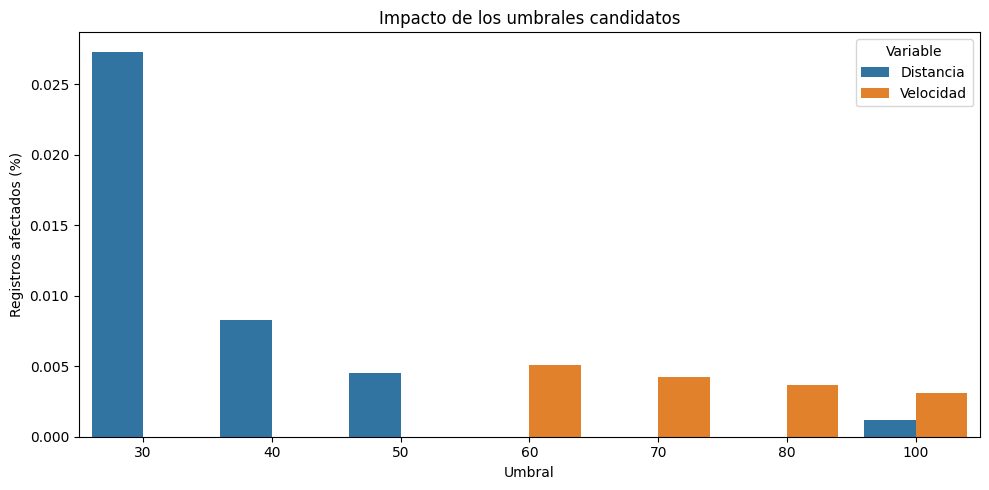

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=threshold_comparison_pd, x='Umbral', y='Porcentaje (%)', hue='Variable', ax=ax
)

ax.set_title('Impacto de los umbrales candidatos')
ax.set_xlabel('Umbral')
ax.set_ylabel('Registros afectados (%)')

fig.tight_layout()

_ = save_figure(fig, '01_threshold_impact', images_dir)

plt.show()

## 4. Selección y aplicación de los criterios de depuración

Los resultados obtenidos en el análisis específico permiten seleccionar unos límites conservadores para construir el dataset analítico depurado.

### 4.1. Criterios seleccionados

Se adoptan los siguientes límites:

- **velocidad máxima: 80 mph**;
- **distancia máxima: 50 millas**.

La selección se basa en la combinación de la distribución observada y el impacto de cada umbral.

Para la velocidad, el percentil 99,9 se sitúa en **45,29 mph**. Un límite de 80 mph queda ampliamente por encima de la distribución habitual y afecta únicamente a **426 registros (0,0037 %)**.

Para la distancia, el percentil 99,9 es de **23,28 millas**. El límite de 50 millas mantiene un margen igualmente amplio y afecta a **517 registros (0,0045 %)**.

La aplicación conjunta de ambos criterios afecta a **725 viajes únicos**, equivalentes al **0,0063 %** del dataset procesado de referencia. Entre ellos, **218 registros** cumplen simultáneamente los dos criterios.

Los límites seleccionados buscan eliminar únicamente la cola claramente anómala, evitando utilizar los percentiles como puntos de corte directos y preservando prácticamente la totalidad de los registros.

### 4.2. Construcción del dataset depurado

Los criterios seleccionados se aplican conjuntamente sobre el DataFrame de referencia.

Un viaje se conserva únicamente cuando su velocidad no supera las 80 mph y su distancia no supera las 50 millas.

El DataFrame resultante será reutilizado en los análisis posteriores. La operación de caché utilizada en la implementación local se mantiene documentada pero desactivada en Databricks Free Edition debido a las restricciones del compute Serverless.

In [ ]:
# ============================================================
# CRITERIOS DEFINITIVOS DE DEPURACIÓN
# ============================================================
SPEED_LIMIT = 80.0
DISTANCE_LIMIT = 50.0


# ============================================================
# DATASET ANALÍTICO DEPURADO
# ============================================================
cleaned_trips_df = (
    nyc_trips_df
    .filter((F.col('speed') <= SPEED_LIMIT) & (F.col('trip_distance') <= DISTANCE_LIMIT))

    # Desactivado en Databricks Free / Serverless
    # .cache()
)

### 4.3. Validación de la depuración

La depuración debe cumplir dos condiciones:

- eliminar exactamente los registros identificados por la combinación de criterios;
- garantizar que los valores máximos del dataset resultante respetan los límites establecidos.

También se cuantifica la proporción de registros conservados para comprobar que la operación afecta únicamente a una fracción mínima del dataset de referencia.

In [ ]:
# ============================================================
# MATERIALIZACIÓN DEL DATASET DEPURADO
# ============================================================
cleaned_trip_count = cleaned_trips_df.count()

removed_trip_count = trip_count - cleaned_trip_count

retained_pct = 100 * cleaned_trip_count / trip_count

removed_pct = 100 * removed_trip_count / trip_count


# ============================================================
# COMPROBACIÓN DE LOS LÍMITES
# ============================================================
cleaned_limits = cleaned_trips_df.agg(
    F.max('speed').alias('max_speed'),
    F.max('trip_distance').alias('max_trip_distance')
).first()


# ============================================================
# VALIDACIONES
# ============================================================
assert removed_trip_count == criteria_coincidence['affected_total']

assert cleaned_trip_count == 11_488_991

assert cleaned_limits['max_speed'] <= SPEED_LIMIT

assert cleaned_limits['max_trip_distance'] <= DISTANCE_LIMIT


# ============================================================
# RESUMEN DE LA DEPURACIÓN
# ============================================================
cleaning_summary_pd = pd.DataFrame({
    'Indicador': [
        'Registros de referencia',
        'Registros depurados',
        'Registros eliminados',
        'Registros conservados',
        'Registros eliminados',
        'Velocidad máxima resultante',
        'Distancia máxima resultante'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{cleaned_trip_count:,}',
        f'{removed_trip_count:,}',
        f'{retained_pct:.4f} %',
        f'{removed_pct:.4f} %',
        f"{cleaned_limits['max_speed']:.2f} mph",
        f"{cleaned_limits['max_trip_distance']:.2f} mi"
    ]
}).set_index('Indicador')

cleaning_summary_pd

,Resultado
Indicador,
Registros de referencia,"11,489,716"
Registros depurados,"11,488,991"
Registros eliminados,725
Registros conservados,99.9937 %
Registros eliminados,0.0063 %
Velocidad máxima resultante,79.81 mph
Distancia máxima resultante,50.00 mi


## 5. Comparación antes y después de la depuración

La eliminación de una fracción muy pequeña de registros no implica necesariamente que su efecto analítico sea pequeño.

Los valores detectados son extraordinariamente extremos, por lo que pueden modificar de forma significativa determinadas estadísticas sensibles, especialmente las medias y los valores máximos.

En esta sección se comparan el **dataset procesado de referencia** y el **dataset depurado** para evaluar:

- el volumen de datos conservado;
- los principales estadísticos de distancia y velocidad;
- la sensibilidad de medias y medianas;
- el efecto sobre los patrones temporales;
- la estabilidad de la estructura territorial;
- la conservación del perfil de la distribución hasta el percentil 99,9.

El objetivo es determinar qué resultados cambian realmente y cuáles permanecen estables después de la depuración.


### 5.1. Impacto sobre el volumen de datos

La primera comparación cuantifica el tamaño de ambos datasets.

Dado que los criterios se han diseñado para actuar únicamente sobre la cola extrema de las distribuciones, se espera conservar prácticamente la totalidad de los viajes.

Además del número de registros se calcula el porcentaje retenido y eliminado respecto al dataset de referencia.

In [ ]:
# ============================================================
# COMPARACIÓN DEL VOLUMEN DE DATOS
# ============================================================
volume_comparison_pd = pd.DataFrame({
    'Dataset': [
        'Referencia',
        'Depurado',
        'Eliminados'
    ],
    'Registros': [
        trip_count,
        cleaned_trip_count,
        removed_trip_count
    ],
    'Porcentaje (%)': [
        100.0,
        retained_pct,
        removed_pct
    ]
}).set_index('Dataset')

volume_comparison_pd['Porcentaje (%)'] = volume_comparison_pd['Porcentaje (%)'].round(4)

_ = save_table(volume_comparison_pd, '01_volume_comparison', tables_dir)

volume_comparison_pd

,Registros,Porcentaje (%)
Dataset,,
Referencia,11489716,100.0000
Depurado,11488991,99.9937
Eliminados,725,0.0063


#### Impacto sobre el tamaño del dataset

La aplicación conjunta de los criterios elimina únicamente **725 registros** de los **11.489.716 viajes** del dataset procesado de referencia.

El dataset depurado conserva **11.488.991 viajes**, equivalentes al **99,9937 %** del total, mientras que los registros eliminados representan solo el **0,0063 %**.

La depuración afecta, por tanto, a una fracción extremadamente pequeña del conjunto de datos. Esto permite analizar posteriormente si unas pocas observaciones de magnitud excepcional pueden producir un efecto estadístico desproporcionado.

### 5.2. Comparación de estadísticos descriptivos

Para medir el efecto real de la depuración se calculan sobre ambos datasets los mismos estadísticos de distancia y velocidad.

Se comparan:

- media;
- mediana;
- percentil 95;
- percentil 99;
- máximo.

La comparación permite distinguir entre estadísticas sensibles a valores extremos y medidas robustas que describen el comportamiento habitual de la distribución.

In [ ]:
# ============================================================
# ESTADÍSTICOS ANTES Y DESPUÉS
# ============================================================
comparison_stats_pd = pd.DataFrame([
    compute_comparison_stats(nyc_trips_df, 'Referencia'),
    compute_comparison_stats(cleaned_trips_df, 'Depurado')
]).set_index('Dataset')

comparison_stats_pd

,n_trips,avg_distance,median_distance,p95_distance,p99_distance,max_distance,avg_speed,median_speed,p95_speed,p99_speed,max_speed
Dataset,,,,,,,,,,,
Referencia,11489716,14.066442,1.83,10.1,18.41,15420004.5,63.169726,11.33,25.76,36.19,1.928571e+08
Depurado,11488991,3.032227,1.83,10.1,18.40,50.0,12.789428,11.33,25.75,36.16,7.981000e+01


In [ ]:
# ============================================================
# COMPARACIÓN DE DISTANCIA
# ============================================================
distance_comparison_pd = comparison_stats_pd[[
    'avg_distance',
    'median_distance',
    'p95_distance',
    'p99_distance',
    'max_distance'
]].rename(
    columns={
        'avg_distance': 'Media',
        'median_distance': 'Mediana',
        'p95_distance': 'P95',
        'p99_distance': 'P99',
        'max_distance': 'Máximo'
    }
)

_ = save_table(distance_comparison_pd, '02_distance_comparison', tables_dir)

distance_comparison_pd.style.format('{:,.2f}')

,Media,Mediana,P95,P99,Máximo
Dataset,,,,,
Referencia,14.07,1.83,10.10,18.41,"15,420,004.50"
Depurado,3.03,1.83,10.10,18.40,50.00


In [ ]:
# ============================================================
# COMPARACIÓN DE VELOCIDAD
# ============================================================
speed_comparison_pd = comparison_stats_pd[[
    'avg_speed',
    'median_speed',
    'p95_speed',
    'p99_speed',
    'max_speed'
]].rename(
    columns={
        'avg_speed': 'Media',
        'median_speed': 'Mediana',
        'p95_speed': 'P95',
        'p99_speed': 'P99',
        'max_speed': 'Máximo'
    }
)

_ = save_table(speed_comparison_pd, '03_speed_comparison', tables_dir)

speed_comparison_pd.style.format('{:,.2f}')

,Media,Mediana,P95,P99,Máximo
Dataset,,,,,
Referencia,63.17,11.33,25.76,36.19,"192,857,142.86"
Depurado,12.79,11.33,25.75,36.16,79.81


#### Efecto sobre la distribución

La comparación revela una diferencia muy marcada entre las estadísticas sensibles a valores extremos y las medidas robustas.

En distancia, la media disminuye de aproximadamente **14,07 a 3,03 millas**, mientras que la mediana permanece en **1,83 millas**. El percentil 95 continúa en **10,10 millas** y el percentil 99 apenas varía de **18,41 a 18,40 millas**.

En velocidad se observa el mismo comportamiento. La media pasa de aproximadamente **63,17 a 12,79 mph**, mientras que la mediana permanece en **11,33 mph**. El percentil 95 cambia únicamente de **25,76 a 25,75 mph** y el percentil 99 de **36,19 a 36,16 mph**.

Los máximos, en cambio, pasan de valores extraordinariamente elevados a los límites establecidos por la depuración: **50 millas** y **79,81 mph**.

Esto confirma que los registros eliminados se encontraban muy alejados de la distribución central y que su retirada apenas modifica los percentiles representativos del comportamiento habitual.

### 5.3. Sensibilidad de la media frente a la mediana

Los valores extremos pueden alterar de forma intensa la media incluso cuando representan una proporción mínima del dataset.

La mediana, en cambio, depende de la posición central de la distribución y resulta mucho menos sensible a unas pocas observaciones de magnitud extraordinaria.

Se compara el cambio relativo producido por la depuración sobre ambas medidas para distancia y velocidad.

In [ ]:
# ============================================================
# CAMBIO RELATIVO DE MEDIA Y MEDIANA
# ============================================================
sensitivity_pd = pd.DataFrame({
    'Variable': [
        'Distancia · media',
        'Distancia · mediana',
        'Velocidad · media',
        'Velocidad · mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_distance'],
        comparison_stats_pd.loc['Referencia', 'median_distance'],
        comparison_stats_pd.loc['Referencia', 'avg_speed'],
        comparison_stats_pd.loc['Referencia', 'median_speed']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_distance'],
        comparison_stats_pd.loc['Depurado', 'median_distance'],
        comparison_stats_pd.loc['Depurado', 'avg_speed'],
        comparison_stats_pd.loc['Depurado', 'median_speed']
    ]
})

sensitivity_pd['Cambio relativo (%)'] = relative_change(
    sensitivity_pd['Referencia'], sensitivity_pd['Depurado']
).round(4)

sensitivity_pd = sensitivity_pd.set_index('Variable')

sensitivity_pd

,Referencia,Depurado,Cambio relativo (%)
Variable,,,
Distancia · media,14.066442,3.032227,-78.4435
Distancia · mediana,1.830000,1.830000,0.0000
Velocidad · media,63.169726,12.789428,-79.7539
Velocidad · mediana,11.330000,11.330000,0.0000


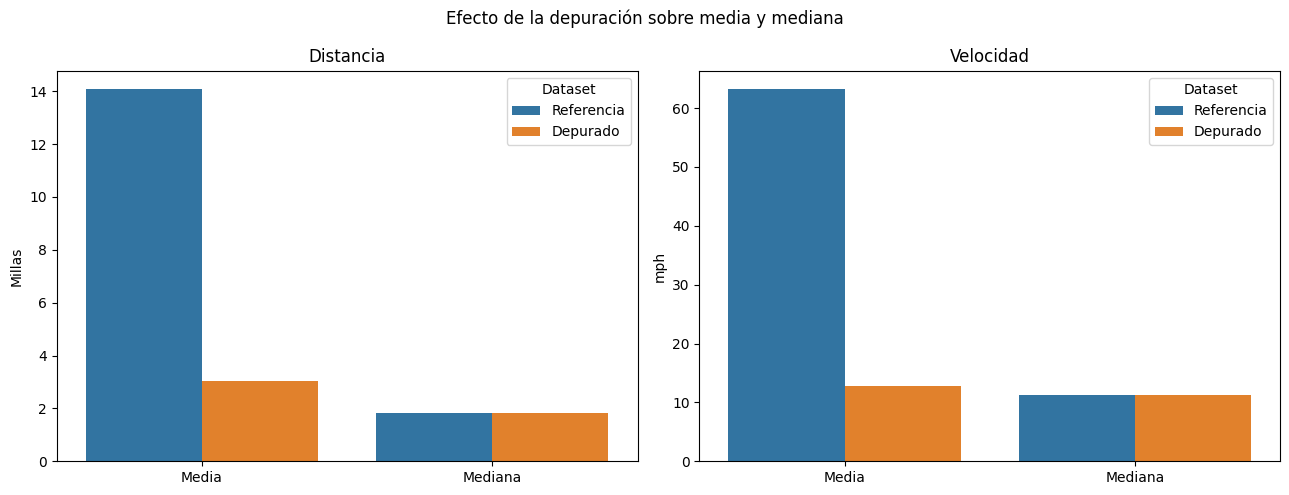

In [ ]:
# ============================================================
# COMPARACIÓN VISUAL DE MEDIA Y MEDIANA
# ============================================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

distance_plot_pd = pd.DataFrame({
    'Estadístico': [
        'Media',
        'Mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_distance'],
        comparison_stats_pd.loc['Referencia', 'median_distance']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_distance'],
        comparison_stats_pd.loc['Depurado', 'median_distance']
    ]
}).melt(
    id_vars='Estadístico',
    var_name='Dataset',
    value_name='Valor'
)

sns.barplot(
    data=distance_plot_pd, x='Estadístico', y='Valor', hue='Dataset', ax=axes[0]
)

axes[0].set_title('Distancia')
axes[0].set_ylabel('Millas')
axes[0].set_xlabel('')


speed_plot_pd = pd.DataFrame({
    'Estadístico': [
        'Media', 'Mediana'
    ],
    'Referencia': [
        comparison_stats_pd.loc['Referencia', 'avg_speed'],
        comparison_stats_pd.loc['Referencia', 'median_speed']
    ],
    'Depurado': [
        comparison_stats_pd.loc['Depurado', 'avg_speed'],
        comparison_stats_pd.loc['Depurado', 'median_speed']
    ]
}).melt(
    id_vars='Estadístico',
    var_name='Dataset',
    value_name='Valor',
)

sns.barplot(
    data=speed_plot_pd, x='Estadístico', y='Valor', hue='Dataset', ax=axes[1])

axes[1].set_title('Velocidad')
axes[1].set_ylabel('mph')
axes[1].set_xlabel('')

fig.suptitle('Efecto de la depuración sobre media y mediana')

fig.tight_layout()

_ = save_figure(fig, '02_mean_median_comparison', images_dir)

plt.show()

#### Sensibilidad de los estadísticos

Aunque la depuración elimina únicamente el **0,0063 %** de los registros, su efecto sobre las medias es muy elevado:

- la distancia media se reduce aproximadamente un **78,44 %**;
- la velocidad media se reduce aproximadamente un **79,75 %**.

En contraste, las medianas globales de ambas variables no experimentan ningún cambio observable con la precisión utilizada.

La diferencia demuestra que el problema no reside en una alteración general de la distribución, sino en un conjunto extremadamente reducido de registros con magnitudes capaces de dominar el cálculo de la media.

La depuración permite que esta medida vuelva a situarse en una escala coherente con la parte central de la distribución, mientras que los estadísticos robustos confirman la estabilidad del comportamiento habitual.

### 5.4. Distribución temporal de los registros depurados

La depuración elimina una proporción mínima de observaciones, pero resulta necesario comprobar si esos registros se concentran en determinados días de la semana.

Para cada día se compara el número de viajes del dataset de referencia con el número conservado después de aplicar los criterios, obteniendo también el número y porcentaje de registros eliminados.

Esta comparación permite distinguir entre la **frecuencia temporal de los valores extremos** y el efecto que su magnitud puede ejercer posteriormente sobre los estadísticos diarios.

In [ ]:
# ============================================================
# RESUMEN TEMPORAL DE REFERENCIA
# ============================================================
reference_daily_df = nyc_trips_df.groupBy('day_of_week').agg(
    F.count('*').alias('reference_trips'),
    F.avg('speed').alias('reference_avg_speed'),
    F.expr('percentile_approx(speed, 0.5, 10000)').alias('reference_median_speed'),
    F.avg('trip_distance').alias('reference_avg_distance'),
    F.expr('percentile_approx(trip_distance, 0.5, 10000)').alias('reference_median_distance')
)


# ============================================================
# RESUMEN TEMPORAL DEPURADO
# ============================================================
cleaned_daily_df = cleaned_trips_df.groupBy('day_of_week').agg(
    F.count('*').alias('cleaned_trips'),
    F.avg('speed').alias('cleaned_avg_speed'),
    F.expr('percentile_approx(speed, 0.5, 10000)').alias('cleaned_median_speed'),
    F.avg('trip_distance').alias('cleaned_avg_distance'),
    F.expr('percentile_approx(trip_distance, 0.5, 10000)').alias('cleaned_median_distance')
)


# ============================================================
# COMPARACIÓN TEMPORAL
# ============================================================
daily_comparison_pd = (
    reference_daily_df
    .join(cleaned_daily_df, on='day_of_week', how='inner')
    .withColumn('removed_trips', F.col('reference_trips') - F.col('cleaned_trips'))
    .withColumn('removed_pct', 100 * F.col('removed_trips') / F.col('reference_trips'))
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
    .reset_index()
)

daily_comparison_pd['Día'] = daily_comparison_pd['day_of_week'].replace(DAY_LABELS)

daily_comparison_pd = daily_comparison_pd.drop(columns='day_of_week').set_index('Día')

daily_comparison_pd['removed_pct'] = daily_comparison_pd['removed_pct'].round(4)

_ = save_table(daily_comparison_pd, '04_daily_comparison', tables_dir)

daily_comparison_pd

,reference_trips,reference_avg_speed,reference_median_speed,reference_avg_distance,reference_median_distance,cleaned_trips,cleaned_avg_speed,cleaned_median_speed,cleaned_avg_distance,cleaned_median_distance,removed_trips,removed_pct
Día,,,,,,,,,,,,
Lunes,1197153,13.304696,11.65,3.177713,1.80,1197067,13.294217,11.65,3.172735,1.80,86,0.0072
Martes,1233286,12.472920,11.06,2.922900,1.78,1233215,12.463569,11.06,2.919403,1.78,71,0.0058
Miércoles,1510473,26.600803,10.56,5.513957,1.80,1510384,12.083459,10.56,2.950842,1.80,89,0.0059
Jueves,1953824,21.965153,10.97,7.418510,1.87,1953704,12.442938,10.97,3.079873,1.87,120,0.0061
Viernes,2004594,204.100467,10.48,37.606275,1.80,2004450,12.032145,10.47,3.011839,1.80,144,0.0072
Sábado,2148723,33.339184,11.64,8.672703,1.86,2148613,13.000095,11.64,2.892503,1.86,110,0.0051
Domingo,1441663,90.604185,13.04,25.919198,2.00,1441558,14.597265,13.04,3.269370,2.00,105,0.0073


#### Distribución de los registros eliminados

Los registros eliminados representan entre aproximadamente el **0,0051 % y el 0,0073 %** de los viajes diarios.

La distribución es reducida y relativamente homogénea durante toda la semana: ningún día concentra una proporción suficientemente elevada de eliminaciones como para modificar de forma apreciable su volumen total.

Esto permite analizar por separado un aspecto diferente: aunque los registros afectados son muy pocos, su magnitud puede alterar considerablemente determinados estadísticos diarios.

### 5.5. Evolución diaria de la velocidad

La velocidad permite observar con especial claridad la diferencia entre **frecuencia de valores extremos** e **impacto estadístico**.

Se comparan para cada día de la semana la media y la mediana antes y después de la depuración.

La media es sensible a registros de magnitud excepcional, mientras que la mediana describe la posición central de la distribución. La representación conjunta permite comprobar si la depuración corrige valores distorsionados sin modificar el comportamiento habitual de los viajes.

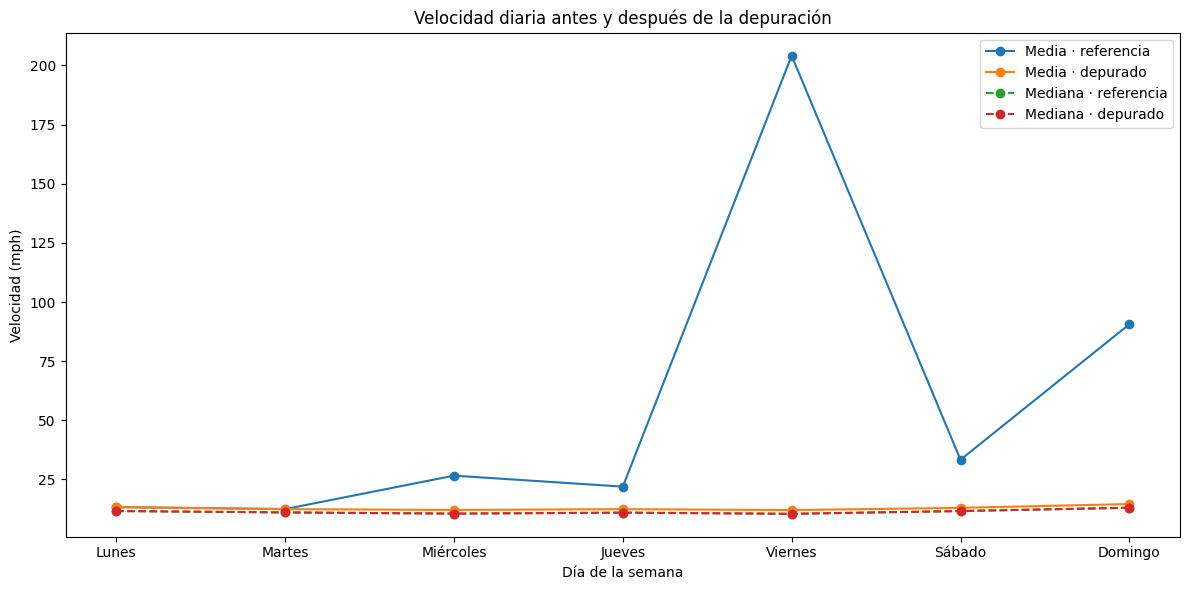

In [ ]:
# ============================================================
# VELOCIDAD DIARIA ANTES Y DESPUÉS
# ============================================================
daily_speed_plot_pd = daily_comparison_pd[[
    'reference_avg_speed',
    'cleaned_avg_speed',
    'reference_median_speed',
    'cleaned_median_speed'
]].reset_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['reference_avg_speed'], marker='o',
    label='Media · referencia'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['cleaned_avg_speed'], marker='o',
    label='Media · depurado'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['reference_median_speed'], marker='o',
    linestyle='--', label='Mediana · referencia'
)

ax.plot(
    daily_speed_plot_pd['Día'], daily_speed_plot_pd['cleaned_median_speed'], marker='o',
    linestyle='--', label='Mediana · depurado'
)

ax.set_title('Velocidad diaria antes y después de la depuración')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Velocidad (mph)')

ax.legend()

fig.tight_layout()

_ = save_figure(fig, '03_daily_speed_comparison', images_dir)

plt.show()

#### Efecto de la depuración sobre la velocidad diaria

La diferencia entre media y mediana confirma que el efecto de los registros extremos es muy desigual según el estadístico utilizado.

El caso más acusado se produce el **viernes**, cuya velocidad media disminuye de aproximadamente **204,10 a 12,03 mph**. El **domingo** pasa de **90,60 a 14,60 mph** y el **sábado** de **33,34 a 13,00 mph**.

En cambio, las velocidades medianas permanecen prácticamente invariantes durante toda la semana.

La depuración no modifica, por tanto, el patrón central de velocidad de los viajes. Su principal efecto consiste en eliminar la influencia desproporcionada que unas pocas observaciones ejercían sobre las medias diarias.

### 5.6. Evolución diaria de la distancia

La comparación temporal se amplía a la distancia recorrida para comprobar si los valores extremos producen un efecto similar al observado sobre la velocidad.

Se representan conjuntamente la **media** y la **mediana diaria** antes y después de la depuración.

Si los registros eliminados se concentran principalmente en la cola extrema, se espera que la media experimente una corrección apreciable mientras que la mediana conserve prácticamente el mismo comportamiento semanal.

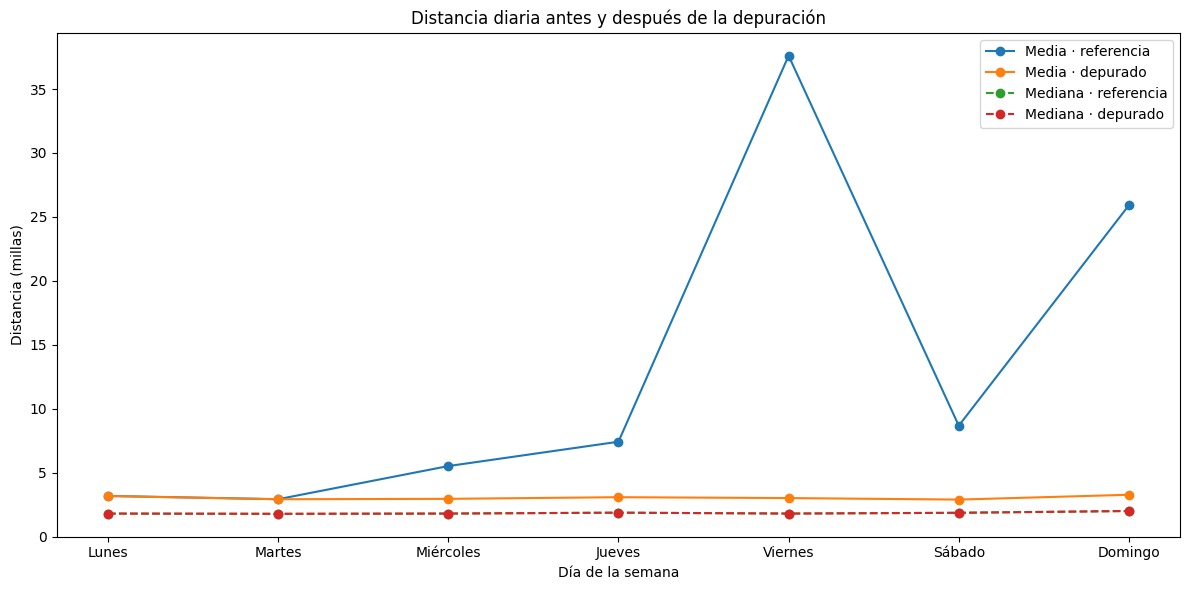

In [ ]:
# ============================================================
# DISTANCIA DIARIA ANTES Y DESPUÉS
# ============================================================
daily_distance_plot_pd = daily_comparison_pd[[
    'reference_avg_distance',
    'cleaned_avg_distance',
    'reference_median_distance',
    'cleaned_median_distance'
]].reset_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['reference_avg_distance'],
    marker='o', label='Media · referencia'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['cleaned_avg_distance'],
    marker='o', label='Media · depurado'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['reference_median_distance'],
    marker='o', linestyle='--', label='Mediana · referencia'
)

ax.plot(
    daily_distance_plot_pd['Día'], daily_distance_plot_pd['cleaned_median_distance'],
    marker='o', linestyle='--', label='Mediana · depurado'
)

ax.set_title('Distancia diaria antes y después de la depuración')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Distancia (millas)')

ax.legend()

fig.tight_layout()

_ = save_figure(fig, '04_daily_distance_comparison', images_dir)

plt.show()

#### Efecto de la depuración sobre la distancia diaria

La distancia reproduce el mismo patrón observado en la velocidad.

Las diferencias son especialmente acusadas en algunos días. La distancia media del **viernes** disminuye de aproximadamente **37,61 a 3,01 millas**, mientras que el **domingo** pasa de **25,92 a 3,27 millas** y el **sábado** de **8,67 a 2,89 millas**.

También se corrigen valores elevados durante el miércoles y el jueves, cuyas medias quedan próximas a las tres millas después de la depuración.

Frente a estos cambios, las medianas diarias permanecen invariantes con la precisión utilizada, situándose entre **1,78 y 2,00 millas**.

La coincidencia del comportamiento observado en distancia y velocidad refuerza la conclusión anterior: la depuración actúa fundamentalmente sobre una cola extrema de muy baja frecuencia, sin desplazar la parte central de las distribuciones.

### 5.7. Impacto territorial de la depuración

Los criterios de depuración se aplican sobre características del viaje y no directamente sobre su localización. Sin embargo, determinados tipos de trayecto pueden concentrarse territorialmente.

Para comprobar si la eliminación de valores extremos presenta diferencias espaciales, cada viaje se asigna a su **distrito comunitario de origen** mediante mediante las funciones geoespaciales ST_* nativas de Databricks.

Para cada distrito se comparan:

- número de viajes en el dataset de referencia;
- número de viajes conservados tras la depuración;
- registros eliminados;
- porcentaje eliminado;
- posición del distrito por volumen antes y después de la depuración.

El análisis utiliza únicamente el distrito de recogida, ya que el objetivo no es repetir el análisis geoespacial completo del notebook de referencia, sino evaluar si los criterios de calidad de datos modifican de forma desigual la distribución territorial de la actividad.

In [ ]:
# ============================================================
# REFERENCIA DE DISTRITOS
# ============================================================
districts_pd = pd.read_csv(io.StringIO(DISTRICTS_REFERENCE), names=['BoroCD', 'district'])


# ============================================================
# CARGA DE GEOMETRÍAS
# ============================================================
if not geojson_path.exists():
    raise FileNotFoundError(f'No se encuentra el fichero geográfico: {geojson_path}')

# El GeoJSON contiene los polígonos de los distritos comunitarios
gdf_raw = gpd.read_file(geojson_path)

# Los nombres se incorporan mediante el identificador BoroCD
nyc_gdf = gdf_raw.merge(districts_pd, on='BoroCD', how='inner')


# ============================================================
# POLÍGONOS DE LOS DISTRITOS
# ============================================================
# GeoPandas mantiene las geometrías localmente; se serializan a WKT para trasladarlas a Spark
nyc_gdf['district_geom'] = nyc_gdf['geometry'].apply(lambda geometry: geometry.wkt)

# Databricks reconstruye el WKT como geometría espacial nativa
districts_df = (
    spark
    .createDataFrame(nyc_gdf[['district', 'district_geom']])
    .withColumn('district_geom', F.expr('ST_GeomFromWKT(district_geom)'))
)

districts_df.printSchema()


# ============================================================
# DISTRITOS DE RECOGIDA
# ============================================================
pickup_districts = districts_df.withColumnRenamed('district', 'pickup_district')


# ============================================================
# ASIGNACIÓN TERRITORIAL
# ============================================================
district_quality_df = (
    nyc_trips_df
    .withColumn('pickup_point', F.expr('ST_Point(pickup_longitude, pickup_latitude)'))
    .join(
        F.broadcast(pickup_districts),
        F.expr('ST_Contains(district_geom, pickup_point)'),
        how='left'
    )
    .drop('pickup_point', 'district_geom')
    .select('pickup_district', 'trip_distance', 'speed')

    # Desactivado en Databricks Free / Serverless
    # .cache()
)

root
 |-- district: string (nullable = true)
 |-- district_geom: geometry (nullable = true)



In [ ]:
# ============================================================
# VALIDACIÓN DE LA ASIGNACIÓN TERRITORIAL
# ============================================================
district_quality_count = district_quality_df.count()

assigned_district_count = district_quality_df.filter(F.col('pickup_district').isNotNull()).count()

district_coverage_pct = 100 * assigned_district_count / district_quality_count

spatial_join_ok = (district_quality_count == trip_count)

assert spatial_join_ok

spatial_assignment_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes antes del spatial join',
        'Viajes después del spatial join',
        'Viajes con distrito asignado',
        'Cobertura territorial',
        'Conservación de filas'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{district_quality_count:,}',
        f'{assigned_district_count:,}',
        f'{district_coverage_pct:.2f} %',
        'OK'
    ]
}).set_index('Indicador')

spatial_assignment_summary_pd

,Resultado
Indicador,
Viajes antes del spatial join,"11,489,716"
Viajes después del spatial join,"11,489,716"
Viajes con distrito asignado,"10,665,874"
Cobertura territorial,92.83 %
Conservación de filas,OK


In [ ]:
# ============================================================
# IMPACTO DE LA DEPURACIÓN POR DISTRITO
# ============================================================
clean_condition = (F.col('speed') <= SPEED_LIMIT) & (F.col('trip_distance') <= DISTANCE_LIMIT)

district_comparison_df = (
    district_quality_df
    .filter(F.col('pickup_district').isNotNull())
    .groupBy('pickup_district')
    .agg(
        F.count('*').alias('reference_trips'),
        F.sum(clean_condition.cast('int')).alias('cleaned_trips')
    )
    .withColumn('removed_trips', F.col('reference_trips') - F.col('cleaned_trips'))
    .withColumn('removed_pct', 100 * F.col('removed_trips') / F.col('reference_trips'))
)

district_comparison_pd = district_comparison_df.toPandas()


# ============================================================
# POSICIÓN DE LOS DISTRITOS
# ============================================================
district_comparison_pd['reference_rank'] = (
    district_comparison_pd['reference_trips'].rank(method='min', ascending=False).astype(int)
)

district_comparison_pd['cleaned_rank'] = (
    district_comparison_pd['cleaned_trips'].rank(method='min', ascending=False).astype(int)
)

district_comparison_pd['rank_change'] = (
    district_comparison_pd['reference_rank'] - district_comparison_pd['cleaned_rank']
)

district_comparison_pd['removed_pct'] = district_comparison_pd['removed_pct'].round(4)

district_comparison_pd['Distrito'] = (
    district_comparison_pd['pickup_district'].replace(DISTRICT_LABELS)
)


# ============================================================
# RANKING DE LOS DISTRITOS
# ============================================================
top_district_comparison_pd = district_comparison_pd.sort_values(
    'reference_trips',
    ascending=False
).head(15)[[
    'Distrito',
    'reference_trips',
    'cleaned_trips',
    'removed_trips',
    'removed_pct',
    'reference_rank',
    'cleaned_rank',
    'rank_change'
]].rename(columns={
    'reference_trips': 'Referencia',
    'cleaned_trips': 'Depurado',
    'removed_trips': 'Eliminados',
    'removed_pct': 'Eliminados (%)',
    'reference_rank': 'Posición referencia',
    'cleaned_rank': 'Posición depurado',
    'rank_change': 'Cambio posición'
}).set_index('Distrito')

_ = save_table(top_district_comparison_pd, '05_district_comparison', tables_dir)

top_district_comparison_pd

,Referencia,Depurado,Eliminados,Eliminados (%),Posición referencia,Posición depurado,Cambio posición
Distrito,,,,,,,
Midtown,2742852,2742740,112,0.0041,1,1,0
Upper East Side,1596827,1596782,45,0.0028,2,2,0
Chelsea / Clinton,1224867,1224809,58,0.0047,3,3,0
Stuyvesant / Turtle Bay,1211238,1211187,51,0.0042,4,4,0
Greenwich / SoHo,1121318,1121282,36,0.0032,5,5,0
Upper West Side,988038,988010,28,0.0028,6,6,0
LES / Chinatown,670702,670671,31,0.0046,7,7,0
Financial District,526959,526935,24,0.0046,8,8,0
East Harlem,99715,99711,4,0.0040,9,9,0


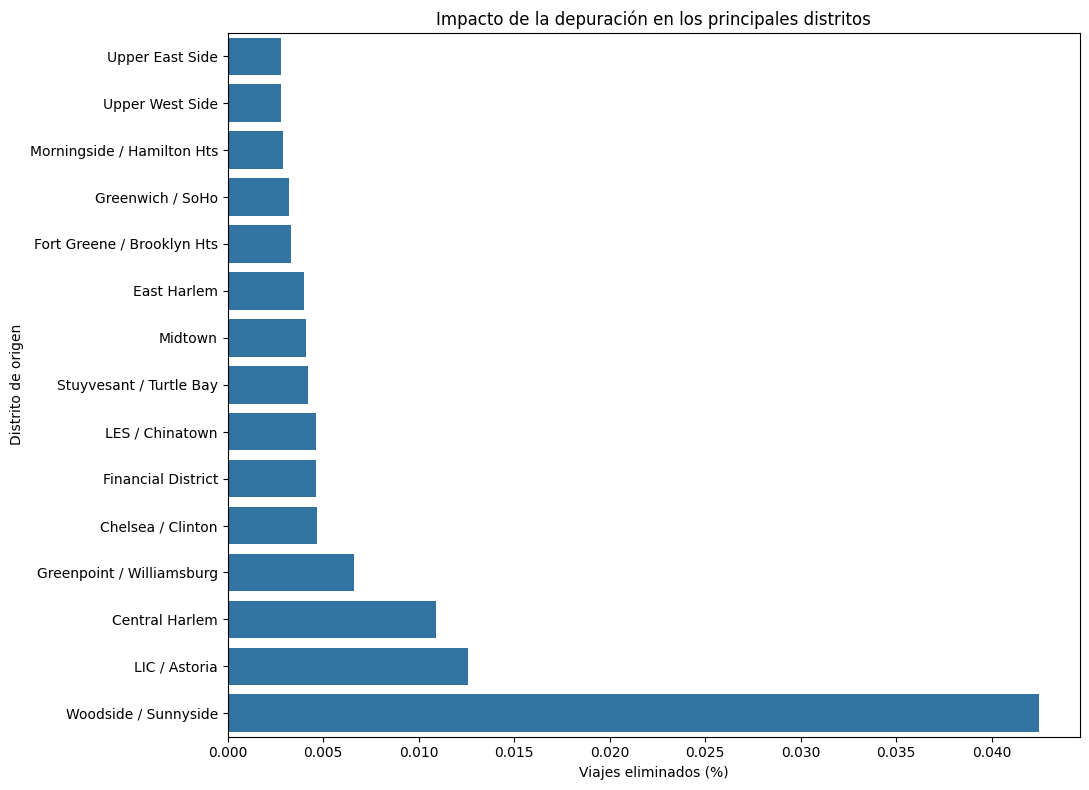

In [ ]:
# ============================================================
# IMPACTO RELATIVO POR DISTRITO
# ============================================================
district_impact_plot_pd = top_district_comparison_pd.reset_index().sort_values(
    'Eliminados (%)', ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

sns.barplot(
    data=district_impact_plot_pd, x='Eliminados (%)', y='Distrito', ax=ax
)

ax.set_title('Impacto de la depuración en los principales distritos')
ax.set_xlabel('Viajes eliminados (%)')
ax.set_ylabel('Distrito de origen')

fig.tight_layout()

_ = save_figure(fig, '05_district_cleaning_impact', images_dir)

plt.show()

#### Estabilidad territorial de la actividad

El impacto territorial de la depuración es igualmente reducido.

Los **15 distritos con mayor volumen de recogidas conservan exactamente la misma posición** antes y después del filtrado. Midtown continúa ocupando la primera posición, seguido por Upper East Side, Chelsea / Clinton y Stuyvesant / Turtle Bay.

En términos absolutos, Midtown es el distrito del grupo en el que se eliminan más viajes, con **112 registros**, pero representan únicamente el **0,0041 %** de su actividad.

Las mayores proporciones relativas dentro de los 15 distritos aparecen en **Woodside / Sunnyside (0,0425 %)**, **LIC / Astoria (0,0126 %)** y **Central Harlem (0,0109 %)**, valores que siguen siendo muy reducidos.

La depuración no altera, por tanto, la jerarquía territorial de los principales distritos. Esto constituye una evidencia adicional de que los criterios utilizados corrigen registros extremos sin modificar la estructura espacial general de la actividad.

### 5.8. Estabilidad del perfil de percentiles

Las comparaciones anteriores muestran que las medianas y los percentiles altos apenas se modifican tras la depuración.

Para comprobar hasta qué punto se conserva la distribución se amplía el análisis hasta el **percentil 99,9**, comparando el perfil de distancia y velocidad del dataset de referencia con el dataset depurado.

Esta representación permite diferenciar entre una modificación general de la cola superior y la eliminación de un conjunto muy reducido de observaciones situadas mucho más allá de la distribución habitual.



In [ ]:
# ============================================================
# PERFIL DE PERCENTILES
# ============================================================
percentile_expression_distance = (
    'percentile_approx(trip_distance, array(0.50, 0.95, 0.99, 0.999), 10000)'
)

percentile_expression_speed = (
    'percentile_approx(speed, array(0.50, 0.95, 0.99, 0.999), 10000)'
)

reference_distance_q, reference_speed_q = get_percentile_profile(
    nyc_trips_df, percentile_expression_distance, 'distance', percentile_expression_speed, 'speed'
)

cleaned_distance_q, cleaned_speed_q = get_percentile_profile(
    cleaned_trips_df, percentile_expression_distance, 'distance',
    percentile_expression_speed, 'speed'
)

percentile_profile_pd = pd.DataFrame({
    'Percentil': [
        'P50',
        'P95',
        'P99',
        'P99.9'
    ],
    'Distancia · referencia': reference_distance_q,
    'Distancia · depurado': cleaned_distance_q,
    'Velocidad · referencia': reference_speed_q,
    'Velocidad · depurado': cleaned_speed_q
})

_ = save_table(percentile_profile_pd, '06_percentile_profile', tables_dir)

percentile_profile_pd

,Percentil,Distancia · referencia,Distancia · depurado,Velocidad · referencia,Velocidad · depurado
0,P50,1.83,1.83,11.33,11.33
1,P95,10.10,10.10,25.76,25.75
2,P99,18.41,18.40,36.19,36.16
3,P99.9,23.28,23.16,45.29,45.14


In [ ]:
# ============================================================
# VARIACIÓN RELATIVA DEL PERFIL
# ============================================================
distance_profile_change_pct = relative_change(
    percentile_profile_pd['Distancia · referencia'],
    percentile_profile_pd['Distancia · depurado']
).abs()

speed_profile_change_pct = relative_change(
    percentile_profile_pd['Velocidad · referencia'],
    percentile_profile_pd['Velocidad · depurado']
).abs()

max_percentile_profile_change_pct = max(
    distance_profile_change_pct.max(), speed_profile_change_pct.max()
)

print(
    f'Variación relativa máxima del perfil P50–P99.9: {max_percentile_profile_change_pct:.2f} %'
)

Variación relativa máxima del perfil P50–P99.9: 0.52 %


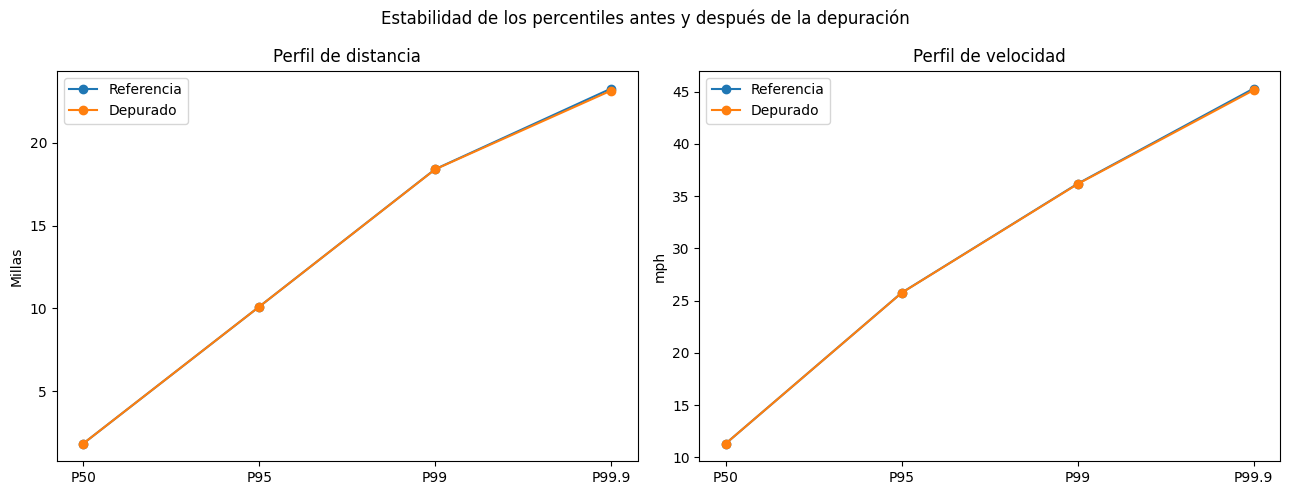

In [ ]:
# ============================================================
# PERFIL VISUAL DE PERCENTILES
# ============================================================
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

axes[0].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Distancia · referencia'],
    marker='o', label='Referencia'
)

axes[0].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Distancia · depurado'],
    marker='o', label='Depurado'
)

axes[0].set_title('Perfil de distancia')
axes[0].set_ylabel('Millas')

axes[0].legend()

axes[1].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Velocidad · referencia'],
    marker='o', label='Referencia'
)

axes[1].plot(
    percentile_profile_pd['Percentil'], percentile_profile_pd['Velocidad · depurado'],
    marker='o', label='Depurado'
)

axes[1].set_title('Perfil de velocidad')
axes[1].set_ylabel('mph')

axes[1].legend()

fig.suptitle('Estabilidad de los percentiles antes y después de la depuración')

fig.tight_layout()

_ = save_figure(fig, '06_percentile_profile_comparison', images_dir)

plt.show()

#### Conservación de la distribución hasta el percentil 99,9

La comparación confirma que la depuración apenas modifica el perfil de las distribuciones incluso al analizar percentiles muy elevados.

En **distancia**, la mediana y el percentil 95 permanecen invariantes con la precisión utilizada. El percentil 99 pasa únicamente de **18,41 a 18,40 millas**, mientras que el percentil 99,9 disminuye de **23,28 a 23,16 millas**.

En **velocidad**, la mediana permanece en **11,33 mph**, el percentil 95 cambia de **25,76 a 25,75 mph**, el percentil 99 de **36,19 a 36,16 mph** y el percentil 99,9 de **45,29 a 45,14 mph**.

La variación relativa máxima observada en estos perfiles es de aproximadamente **0,52 %**.

Este resultado es especialmente relevante porque muestra que la depuración no produce un desplazamiento general de la cola superior de las distribuciones. La gran corrección observada en las medias procede de un número extraordinariamente reducido de observaciones situadas mucho más allá del comportamiento representado incluso por el percentil 99,9.

## 6. Persistencia cloud del dataset depurado

### 6.1. Escritura en formato Parquet

El resultado principal del proceso de calidad de datos es el dataset analítico depurado.

Para conservar este resultado sin volver a ejecutar todo el pipeline, el DataFrame se persiste en formato **Parquet**, un formato columnar adecuado para el procesamiento distribuido con Spark.

En esta implementación la salida se almacena en un **Unity Catalog Volume**, permitiendo mantener los resultados del pipeline dentro del entorno Databricks.

La salida se particiona por día de la semana, lo que mantiene una estructura lógica para posteriores análisis temporales y permite a Spark aplicar poda de particiones cuando una consulta se restringe a determinados días.

Se utiliza compresión **Snappy**, habitual en ecosistemas Spark por su equilibrio entre velocidad de lectura/escritura y reducción de tamaño.

In [ ]:
# ============================================================
# PERSISTENCIA DEL DATASET DEPURADO
# ============================================================
cleaned_parquet_path = parquet_dir

(
    cleaned_trips_df
    .write
    .mode('overwrite')
    .option('compression', 'snappy')
    .partitionBy('day_of_week')
    .parquet(str(cleaned_parquet_path))
)

### 6.2. Validación de la persistencia

Después de la escritura se vuelve a cargar el dataset desde Parquet.

La validación comprueba:

- que el número de registros coincide con el DataFrame depurado;
- que se conservan todas las columnas;
- que los tipos de datos se mantienen;
- que los límites de velocidad y distancia continúan respetándose después de la relectura.

De este modo, el dataset persistido en el Unity Catalog Volume queda validado como resultado reproducible del proceso de depuración.

In [ ]:
# ============================================================
# RELECTURA DEL DATASET DEPURADO
# ============================================================
cleaned_parquet_df = (
    spark
    .read
    .parquet(str(cleaned_parquet_path))
)


# ============================================================
# VALIDACIÓN
# ============================================================
parquet_rows = cleaned_parquet_df.count()

parquet_limits = cleaned_parquet_df.agg(
    F.max('speed').alias('max_speed'),
    F.max('trip_distance').alias('max_trip_distance')
).first()

assert (parquet_rows == cleaned_trip_count)
assert (set(cleaned_parquet_df.columns) == set(cleaned_trips_df.columns))
assert (dict(cleaned_parquet_df.dtypes) == dict(cleaned_trips_df.dtypes))
assert (parquet_limits['max_speed'] <= SPEED_LIMIT)
assert (parquet_limits['max_trip_distance'] <= DISTANCE_LIMIT)


# ============================================================
# RESUMEN DE LA PERSISTENCIA
# ============================================================
parquet_size_mb = (
    sum(file.stat().st_size for file in cleaned_parquet_path.rglob('*') if file.is_file()) / 1024**2
)

parquet_summary_pd = pd.DataFrame({
    'Indicador': [
        'Registros releídos',
        'Columnas',
        'Particionado',
        'Compresión',
        'Tamaño aproximado',
        'Velocidad máxima',
        'Distancia máxima'
    ],
    'Resultado': [
        f'{parquet_rows:,}',
        len(cleaned_parquet_df.columns),
        'day_of_week',
        'Snappy',
        f'{parquet_size_mb:,.2f} MB',
        f"{parquet_limits['max_speed']:.2f} mph",
        f"{parquet_limits['max_trip_distance']:.2f} mi"
    ]
}).set_index('Indicador')

_ = save_table(parquet_summary_pd, '07_parquet_summary', tables_dir)

parquet_summary_pd

,Resultado
Indicador,
Registros releídos,"11,488,991"
Columnas,23
Particionado,day_of_week
Compresión,Snappy
Tamaño aproximado,348.85 MB
Velocidad máxima,79.81 mph
Distancia máxima,50.00 mi


### 6.3. Prueba de reutilización analítica

La validación estructural confirma que el dataset persistido conserva filas, columnas y tipos de datos.

Como comprobación adicional se ejecuta sobre el Parquet releído una agregación temporal independiente y se compara con los recuentos diarios obtenidos directamente desde el DataFrame depurado.

Esta prueba permite verificar no solo la integridad del fichero, sino también su reutilización efectiva como fuente para análisis posteriores.

In [ ]:
# ============================================================
# RECUENTO DIARIO DESDE PARQUET
# ============================================================
parquet_daily_df = cleaned_parquet_df.groupBy('day_of_week').agg(
    F.count('*').alias('parquet_trips')
)


# ============================================================
# COMPARACIÓN CON EL DATAFRAME DEPURADO
# ============================================================
parquet_daily_validation_df = (
    cleaned_daily_df
    .select('day_of_week', 'cleaned_trips')
    .join(parquet_daily_df, on='day_of_week', how='inner')
    .withColumn('difference', F.col('parquet_trips') - F.col('cleaned_trips'))
)

parquet_daily_validation_pd = (
    parquet_daily_validation_df
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
    .reset_index()
)

parquet_daily_validation_pd['Día'] = parquet_daily_validation_pd['day_of_week'].replace(DAY_LABELS)

parquet_daily_validation_pd = parquet_daily_validation_pd.drop(
    columns='day_of_week'
).set_index('Día')

assert (parquet_daily_validation_pd['difference'] == 0).all()

parquet_daily_validation_pd

,cleaned_trips,parquet_trips,difference
Día,,,
Lunes,1197067,1197067,0
Martes,1233215,1233215,0
Miércoles,1510384,1510384,0
Jueves,1953704,1953704,0
Viernes,2004450,2004450,0
Sábado,2148613,2148613,0
Domingo,1441558,1441558,0


### 6.4. Dataset analítico de referencia para las fases posteriores

La persistencia del dataset depurado no se utiliza únicamente como mecanismo de exportación.

En esta implementación actúa como un **checkpoint materializado del pipeline**: las fases de preparación, diagnóstico de calidad y depuración se ejecutan a partir del CSV original, mientras que los análisis estadísticos, temporales y geoespaciales posteriores parten del dataset Parquet ya validado.

Esta estrategia resulta especialmente útil en el entorno Serverless utilizado, donde las operaciones de `cache()` y `persist()` se mantienen desactivadas. La materialización en Parquet evita depender del recálculo completo desde el fichero CSV original cada vez que se reutiliza el dataset analítico.

La relectura ha confirmado que el checkpoint conserva:

- **11.488.991 registros**;
- las **23 columnas** del dataset procesado;
- los tipos de datos;
- los límites de depuración establecidos;
- el particionado por día de la semana;
- y los mismos recuentos diarios que el DataFrame depurado original.

A partir de este punto, el Parquet validado se utiliza como fuente principal para el análisis completo del dataset.

In [ ]:
# ============================================================
# DATASET ANALÍTICO PARA LAS FASES POSTERIORES
# ============================================================
analysis_trips_df = cleaned_parquet_df

print(f'Dataset analítico disponible: {parquet_rows:,} viajes')

Dataset analítico disponible: 11,488,991 viajes


## 7. Análisis estadístico distribuido

A partir de este punto, el análisis utiliza como fuente principal el **dataset analítico depurado persistido y validado en Parquet**.

Esta materialización constituye el checkpoint del pipeline y permite ejecutar las fases analíticas posteriores directamente sobre los **11.488.991 viajes** conservados tras el proceso de calidad de datos.


### 7.1. Estadísticos para distribuciones por hora y día

Para analizar cómo varía la distancia de los viajes en función del momento de la semana se calculan, mediante operaciones distribuidas de Spark, los estadísticos necesarios para construir diagramas de caja.

Para cada combinación de **hora de recogida** y **día de la semana** se obtienen:

- primer cuartil (`q1`);
- mediana;
- tercer cuartil (`q3`);
- bigote inferior observado;
- bigote superior observado.

Los cuartiles y la mediana se calculan mediante una ventana de Spark que mantiene las observaciones originales de cada grupo. A partir del rango intercuartílico se establecen los límites de Tukey (`1,5 × IQR`) y se obtienen los valores observados extremos que permanecen dentro de dichos límites.

El resultado se reorganiza mediante `pivot`, generando una fila por hora del día y un conjunto de cinco estadísticos para cada día de la semana.

In [ ]:
# ============================================================
# ESTADÍSTICOS DE DISTANCIA
# ============================================================
# El resultado se reutiliza en la validación, la tabla resumen y la visualización posterior
stats_df = compute_boxplot_stats(analysis_trips_df, 'trip_distance')

# Desactivado en Databricks Free / Serverless
# stats_df = stats_df.cache()


# ============================================================
# VALIDACIÓN DEL RESULTADO
# ============================================================
stats_rows = stats_df.count()
stats_columns = len(stats_df.columns)

assert stats_rows == 24
assert stats_columns == 36
assert 'pickup_hour' in stats_df.columns
assert 'lunes_median' in stats_df.columns

validation_stats = stats_df.orderBy('pickup_hour').toPandas()

print('Validación de estadísticos completada correctamente.')
print(f'Filas    : {stats_rows}')
print(f'Columnas : {stats_columns}')


# ============================================================
# MEDIANAS DE DISTANCIA POR HORA Y DÍA
# ============================================================
stats_medians_preview_pd = (
    stats_df
    .select(
        'pickup_hour',
        *[F.col(f'{day}_median').alias(DAY_LABELS[day]) for day in DAYS_ORDER]
    )
    .orderBy('pickup_hour')
    .toPandas()
    .set_index('pickup_hour')
)

stats_medians_preview_pd.index.name = 'Hora'

stats_medians_preview_pd

Validación de estadísticos completada correctamente.
Filas    : 24
Columnas : 36


,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
Hora,,,,,,,
0,2.74,2.600,2.51,2.40,2.49,2.23,2.18
1,2.79,2.700,2.63,2.52,2.58,2.33,2.30
2,2.83,2.795,2.64,2.60,2.64,2.44,2.40
3,3.04,2.900,2.90,2.80,2.80,2.60,2.60
4,3.59,3.300,3.20,3.10,3.30,2.90,2.89
5,2.80,2.400,2.28,2.60,2.60,3.30,3.30
6,2.00,1.910,1.90,2.00,2.00,2.60,3.10
7,1.82,1.800,1.80,1.80,1.80,2.10,2.25
8,1.69,1.650,1.60,1.66,1.69,1.90,1.90


### 7.2. Distribución de la distancia de los viajes

Los estadísticos calculados permiten representar la distribución de la distancia recorrida para cada combinación de hora y día de la semana.

Esta visualización facilita la comparación entre franjas temporales sin necesidad de trasladar el dataset analítico completo a memoria local: Spark realiza previamente la agregación distribuida y únicamente se utilizan para la representación los estadísticos resultantes.

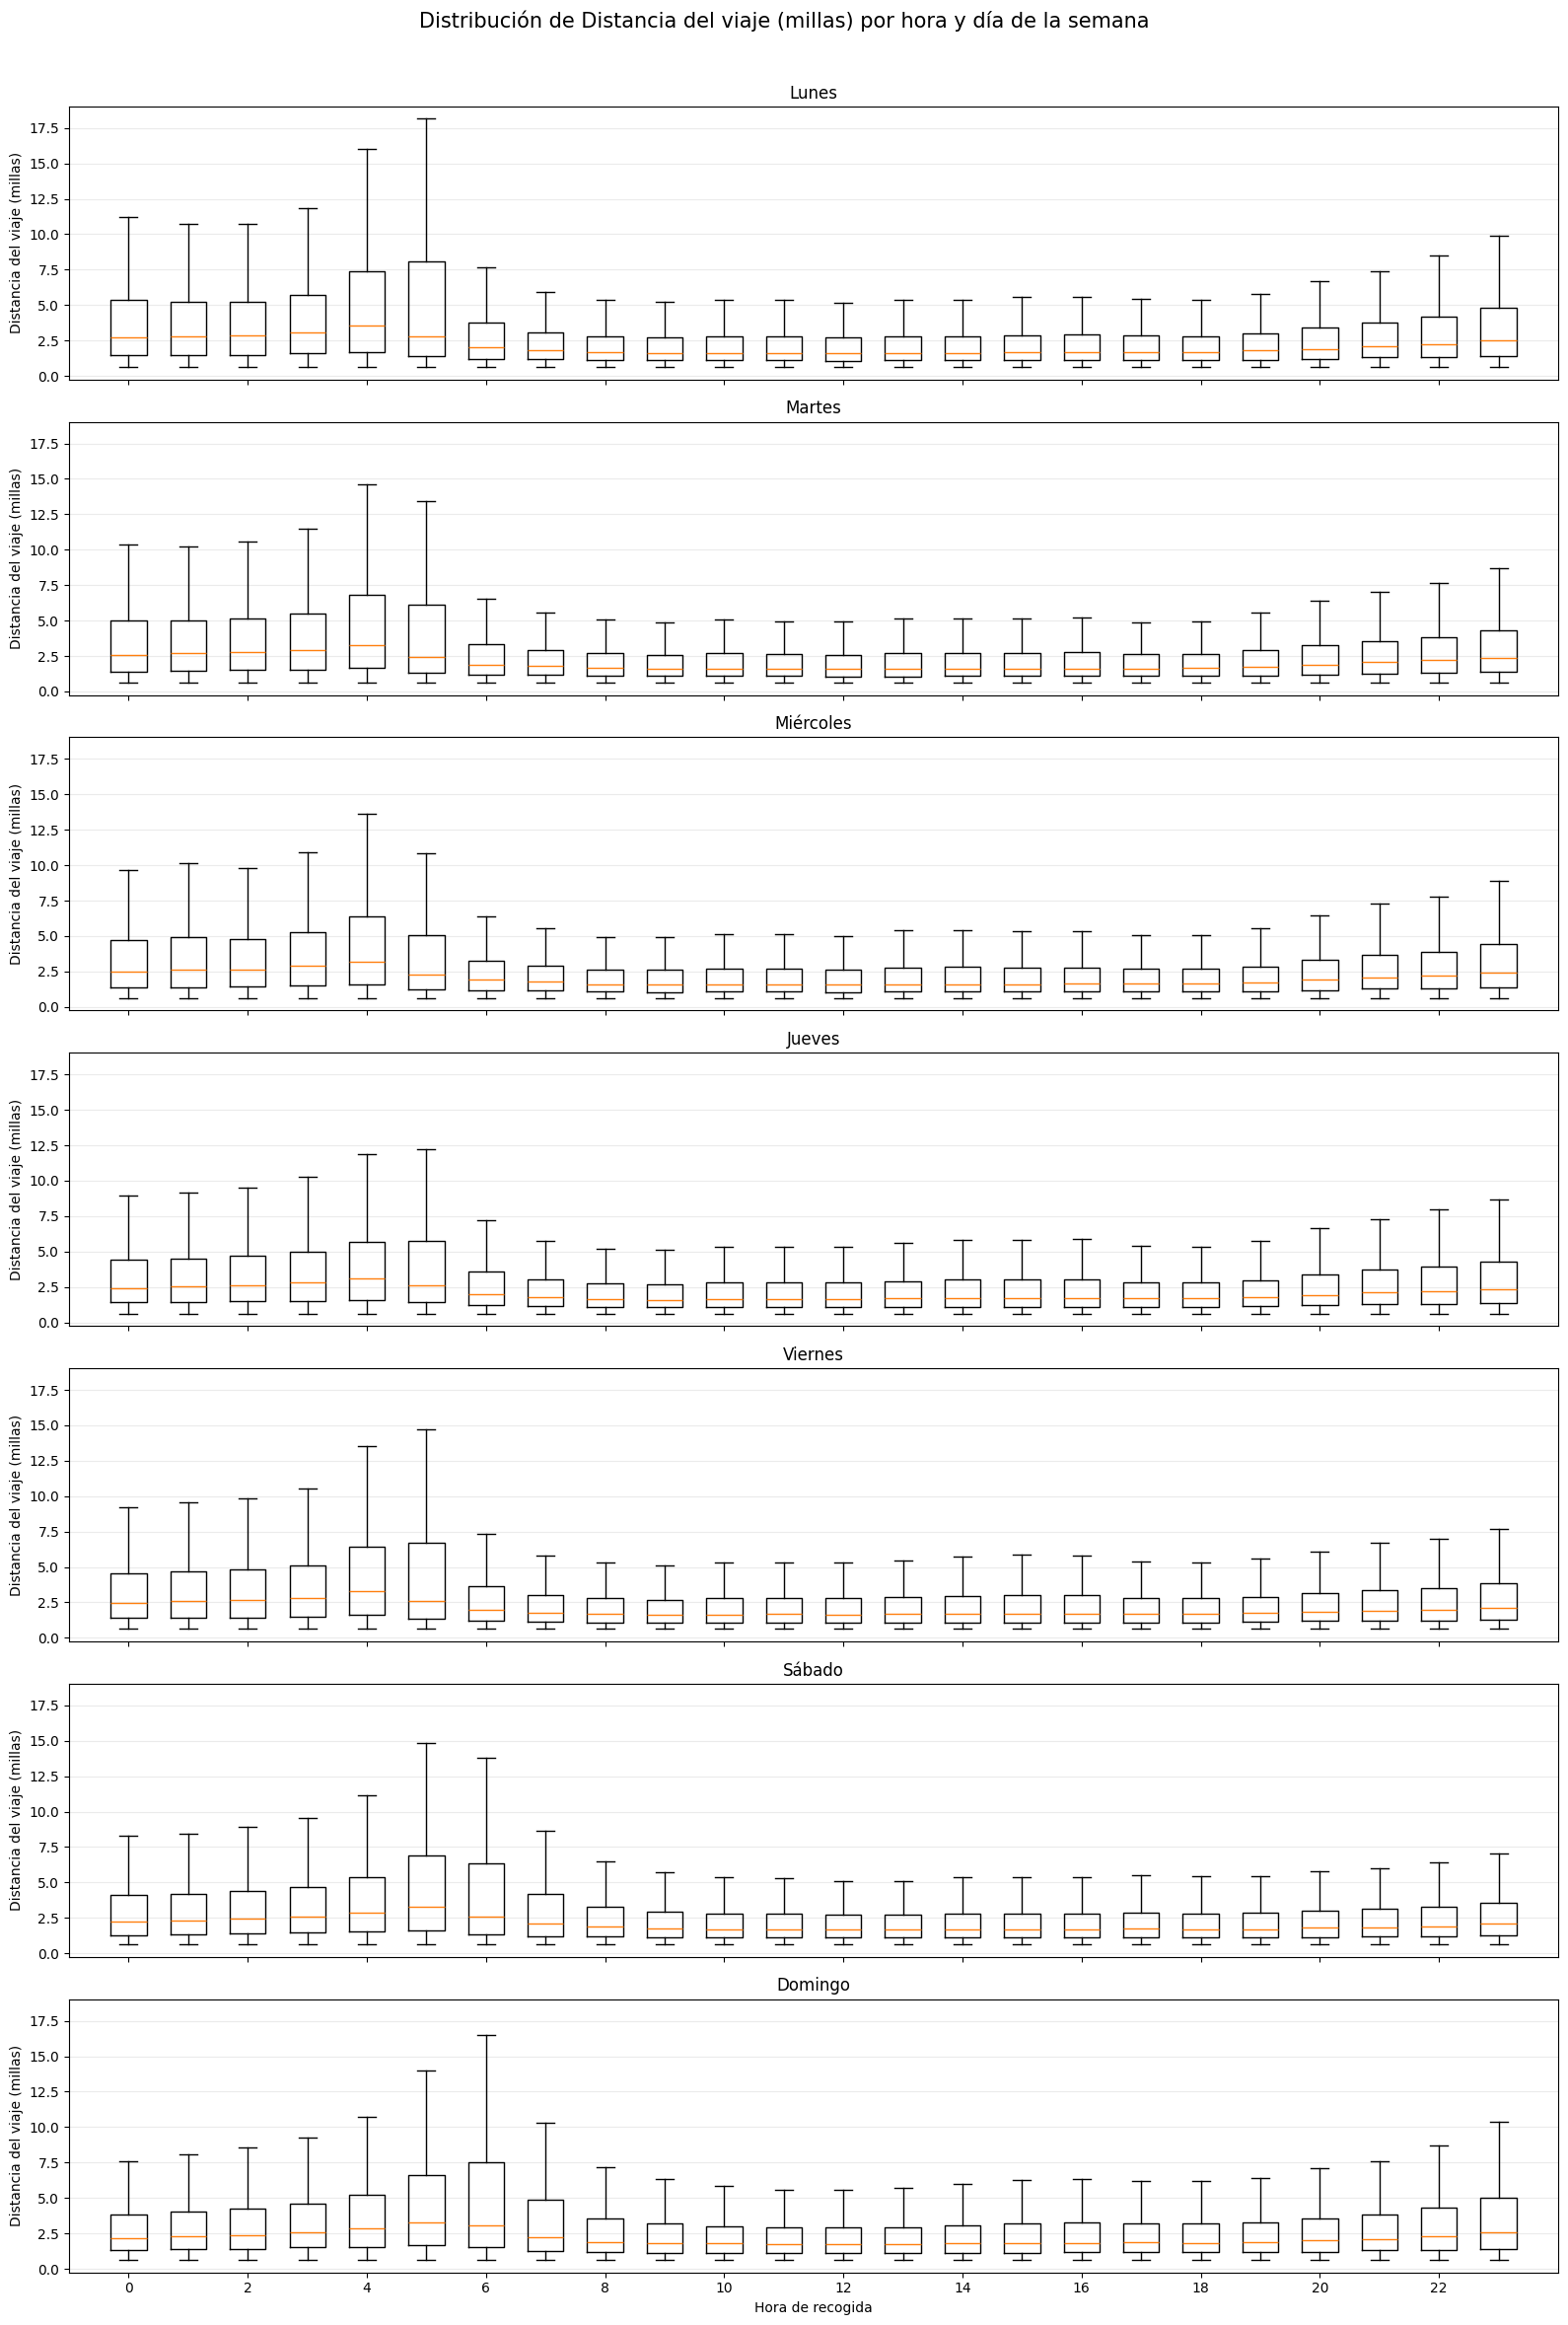

In [ ]:
# ============================================================
# BOXPLOTS DE DISTANCIA POR HORA Y DÍA
# ============================================================
fig_boxplot, _ = plot_boxplot_facets(stats_df, 'Distancia del viaje (millas)')

_ = save_figure(fig_boxplot, '07_trip_distance_boxplots', images_dir)

#### Lectura de la distribución temporal

Los diagramas de caja muestran un patrón temporal consistente. Las distancias medianas son mayores durante la madrugada, especialmente entre aproximadamente las **04:00 y las 06:00**, mientras que durante buena parte del horario diurno se estabilizan en valores próximos a **1,6–1,9 millas**.

Al final del día se observa nuevamente un aumento progresivo de las distancias. Las primeras horas presentan además una mayor dispersión, con bigotes superiores más amplios, lo que indica una mayor heterogeneidad en los trayectos realizados durante esas franjas.

La similitud de las medianas diurnas entre días contrasta con las diferencias observadas en las horas nocturnas y de madrugada.

El cálculo pesado permanece en Spark, mientras que la visualización trabaja únicamente sobre el resultado agregado, considerablemente más pequeño que el **dataset analítico distribuido**.

## 8. Agregaciones temporales y patrones de movilidad

### 8.1. Métrica derivada: importe por milla

Antes de realizar la agregación se incorpora una métrica adicional: el **importe total por milla recorrida**.

Esta variable expresa el **importe total registrado por unidad de distancia**, permitiendo comparar viajes de distinta longitud y complementando el análisis de distancia, velocidad y volumen de desplazamientos.

In [ ]:
# ============================================================
# IMPORTE TOTAL POR MILLA
# ============================================================
# Se evita la división por cero devolviendo NULL cuando la distancia recorrida sea igual a cero.
df_with_amount_per_mile = (
    analysis_trips_df
    .withColumn(
        'total_amount_per_mile',
        F.when(
            F.col('trip_distance') != 0, F.col('total_amount') / F.col('trip_distance')
        ).otherwise(None)
    )
)

# ============================================================
# MUESTRA DE LA MÉTRICA DERIVADA
# ============================================================
amount_per_mile_preview_pd = df_with_amount_per_mile.select(
    'trip_distance',
    'fare_amount',
    'total_amount',
    F.round('total_amount_per_mile', 2).alias('total_amount_per_mile')
).limit(15).toPandas()

amount_per_mile_preview_pd.index = range(1, len(amount_per_mile_preview_pd) + 1)

amount_per_mile_preview_pd.index.name = 'Viaje'

amount_per_mile_preview_pd

,trip_distance,fare_amount,total_amount,total_amount_per_mile
Viaje,,,,
1,2.40,9.0,12.30,5.13
2,1.30,8.0,9.30,7.15
3,0.71,5.0,6.30,8.87
4,2.73,11.0,12.30,4.51
5,0.95,5.5,8.00,8.42
6,4.71,18.0,23.00,4.88
7,1.01,5.0,7.40,7.33
8,19.60,53.0,54.30,2.77
9,1.30,7.5,11.35,8.73


### 8.2. Agregación multidimensional por día y hora

Para estudiar los patrones temporales de movilidad se realiza una única agregación distribuida sobre los viajes, agrupando por **día de la semana** y reorganizando las **24 horas del día** mediante una operación `pivot`.

Para cada combinación de día y hora se calculan simultáneamente:

- número de viajes;
- mediana de la distancia recorrida;
- mediana del importe total por milla;
- mediana de la velocidad.

La estrategia permite obtener las distintas métricas a partir de una única operación de agregación sobre el dataset distribuido.

Posteriormente, los resultados agregados se transforman en pequeñas matrices de 7 × 24 valores, adecuadas para su traslado al driver y su representación mediante mapas de calor.

In [ ]:
# ============================================================
# AGREGACIÓN DISTRIBUIDA
# ============================================================
# Conteo y medianas se obtienen en una única agregación distribuida
metrics = [
    'trip_distance',
    'total_amount_per_mile',
    'speed',
]

# El resultado se reutiliza para construir cuatro matrices temporales
counts_and_distances_df = compute_hourly_medians_and_counts(
    df_with_amount_per_mile, metrics
)

# Desactivado en Databricks Free / Serverless
# counts_and_distances_df = counts_and_distances_df.cache()

### 8.3. Validación y preparación de las matrices temporales

El resultado de la agregación debe contener una fila por cada día de la semana y, para cada una de las 24 horas, cuatro métricas: número de viajes y las medianas de distancia, importe por milla y velocidad.

Esto produce un DataFrame distribuido de **7 filas y 97 columnas**.

A partir de este resultado se construyen cuatro matrices independientes de **7 × 24 valores**, que posteriormente se trasladan a Pandas para su representación.

Antes de continuar se comprueban:

- las dimensiones del DataFrame agregado;
- las columnas esperadas;
- la conversión correcta a Pandas;
- el orden cronológico de los días;
- la presencia de las 24 horas en cada matriz.

In [ ]:
# ============================================================
# VALIDACIÓN DE LA AGREGACIÓN
# ============================================================
aggregated_rows = counts_and_distances_df.count()
aggregated_columns = len(counts_and_distances_df.columns)

assert aggregated_rows == 7
assert aggregated_columns == 97
assert 'day_of_week' in counts_and_distances_df.columns

print(f'Filas    : {aggregated_rows}')
print(f'Columnas : {aggregated_columns}')
print('Agregación temporal validada correctamente.')


# ============================================================
# VISTA COMPACTA DE LA AGREGACIÓN
# ============================================================
aggregation_preview_df = counts_and_distances_df.select(
    'day_of_week',
    F.col('8_n_trips').alias('08h · viajes'),
    F.col('8_trip_distance').alias('08h · distancia'),
    F.col('8_total_amount_per_mile').alias('08h · importe/milla'),
    F.col('8_speed').alias('08h · velocidad'),

    F.col('18_n_trips').alias('18h · viajes'),
    F.col('18_trip_distance').alias('18h · distancia'),
    F.col('18_total_amount_per_mile').alias('18h · importe/milla'),
    F.col('18_speed').alias('18h · velocidad'),

    F.col('23_n_trips').alias('23h · viajes'),
    F.col('23_trip_distance').alias('23h · distancia'),
    F.col('23_total_amount_per_mile').alias('23h · importe/milla'),
    F.col('23_speed').alias('23h · velocidad'),
)

# Cada resultado contiene solo 7 filas × 24 horas, por lo que su traslado al driver es seguro
aggregation_preview_pd = (
    aggregation_preview_df
    .toPandas()
    .set_index('day_of_week')
    .reindex(DAYS_ORDER)
)

aggregation_preview_pd.index = [DAY_LABELS[day] for day in aggregation_preview_pd.index]

aggregation_preview_pd.index.name = 'Día'

aggregation_preview_pd

Filas    : 7
Columnas : 97
Agregación temporal validada correctamente.


,08h · viajes,08h · distancia,08h · importe/milla,08h · velocidad,18h · viajes,18h · distancia,18h · importe/milla,18h · velocidad,23h · viajes,23h · distancia,23h · importe/milla,23h · velocidad
Día,,,,,,,,,,,,
Lunes,73136,1.69,6.666667,9.79,74248,1.70,6.625000,11.11,34999,2.50,5.159574,15.76
Martes,68101,1.65,6.969697,8.94,88529,1.66,7.138889,10.25,51657,2.34,5.378151,14.83
Miércoles,89552,1.60,7.062500,8.84,101876,1.68,7.357143,9.40,63583,2.40,5.376344,14.45
Jueves,96873,1.66,6.986900,9.00,119391,1.70,7.235294,9.49,94869,2.34,5.530303,13.70
Viernes,93930,1.69,6.992126,8.82,129073,1.70,7.181818,9.61,127006,2.15,5.880952,12.18
Sábado,48594,1.90,5.470588,14.40,128672,1.70,6.285714,10.28,130106,2.07,5.971223,11.84
Domingo,29724,1.90,5.320000,15.55,79166,1.83,5.866667,11.77,44977,2.56,5.051225,16.26


La vista compacta confirma que la agregación conserva de forma coherente las cuatro métricas calculadas para cada combinación de día y hora.

Las franjas seleccionadas permiten anticipar los patrones que se desarrollan en los mapas de calor: la actividad aumenta notablemente durante la tarde en los últimos días laborables y durante el sábado, mientras que las velocidades medianas son generalmente menores en las horas de mayor concentración de viajes.

In [ ]:
# ============================================================
# COLUMNAS PARA LAS MATRICES TEMPORALES
# ============================================================
# Se selecciona la mediana de la distancia para cada hora.
cols_trip_distance = (
    [F.col('day_of_week')] +
    [F.col(f'{hour}_trip_distance').alias(str(hour)) for hour in range(24)]
)

# Se selecciona la mediana del importe por milla para cada hora.
cols_total_amount_per_mile = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_total_amount_per_mile').alias(str(hour)) for hour in range(24)]
)

# Se selecciona el número de viajes para cada hora.
cols_n_trips = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_n_trips').alias(str(hour)) for hour in range(24)]
)

# Se selecciona la mediana de la velocidad para cada hora.
cols_speed = (
    [F.col('day_of_week')]
    + [F.col(f'{hour}_speed').alias(str(hour)) for hour in range(24)]
)


# ============================================================
# CONVERSIÓN DE RESULTADOS AGREGADOS A PANDAS
# ============================================================
# Cada resultado contiene únicamente 7 filas y 25 columnas, por lo que se traslada al driver.
trip_distance_by_hour_pd = counts_and_distances_df.select(*cols_trip_distance).toPandas()

total_amount_by_hour_pd = counts_and_distances_df.select(*cols_total_amount_per_mile).toPandas()

n_trips_by_hour_pd = counts_and_distances_df.select(*cols_n_trips).toPandas()

speed_by_hour_pd = counts_and_distances_df.select(*cols_speed).toPandas()


# ============================================================
# ORDEN TEMPORAL DE LOS DÍAS
# ============================================================
# Se aplica el mismo orden a los cuatro DataFrames de Pandas.
trip_distance_by_hour_pd = (
    trip_distance_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()
)

total_amount_by_hour_pd = (
    total_amount_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()
)

n_trips_by_hour_pd = n_trips_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()

speed_by_hour_pd = speed_by_hour_pd.set_index('day_of_week').reindex(DAYS_ORDER).reset_index()


# ============================================================
# VALIDACIÓN DE MATRICES TEMPORALES
# ============================================================
expected_shape = (7, 25)

temporal_matrices = {
    'Distancia mediana': trip_distance_by_hour_pd,
    'Importe por milla': total_amount_by_hour_pd,
    'Número de viajes': n_trips_by_hour_pd,
    'Velocidad mediana': speed_by_hour_pd,
}

matrix_validation_rows = []

for name, matrix in temporal_matrices.items():
    shape_ok = matrix.shape == expected_shape

    days_ok = list(matrix['day_of_week']) == DAYS_ORDER

    hours_ok = all(str(hour) in matrix.columns for hour in range(24))

    matrix_ok = (shape_ok and days_ok and hours_ok)

    assert matrix_ok

    matrix_validation_rows.append({
        'Matriz': name,
        'Filas': matrix.shape[0],
        'Horas': 24,
        'Orden días': 'Lunes → Domingo',
        'Estado': 'OK' if matrix_ok else 'REVISAR'
    })

matrix_validation_pd = pd.DataFrame(
    matrix_validation_rows
).set_index('Matriz')

matrix_validation_pd

,Filas,Horas,Orden días,Estado
Matriz,,,,
Distancia mediana,7,24,Lunes → Domingo,OK
Importe por milla,7,24,Lunes → Domingo,OK
Número de viajes,7,24,Lunes → Domingo,OK
Velocidad mediana,7,24,Lunes → Domingo,OK


### 8.4. Patrones semanales mediante mapas de calor

Las matrices agregadas permiten visualizar conjuntamente las variaciones horarias y semanales de las principales métricas del sistema de movilidad.

Los mapas de calor muestran:

- distancia mediana de los viajes;
- importe mediano por milla;
- volumen de viajes;
- velocidad mediana.

El procesamiento sobre millones de registros se realiza previamente en Spark. La representación utiliza únicamente las matrices agregadas resultantes.

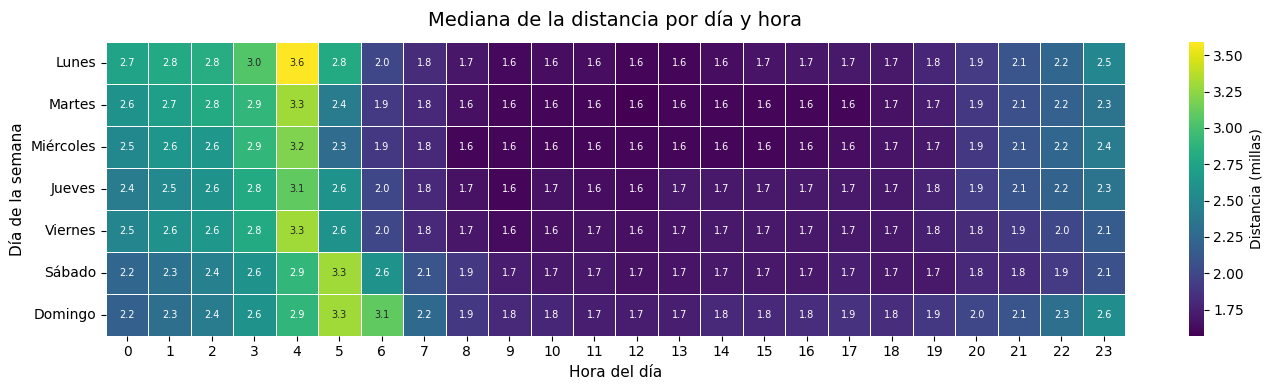

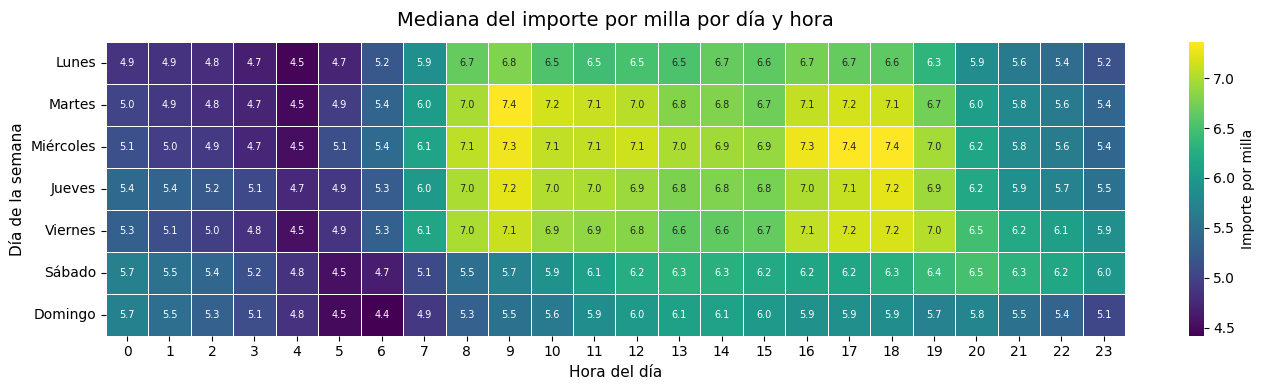

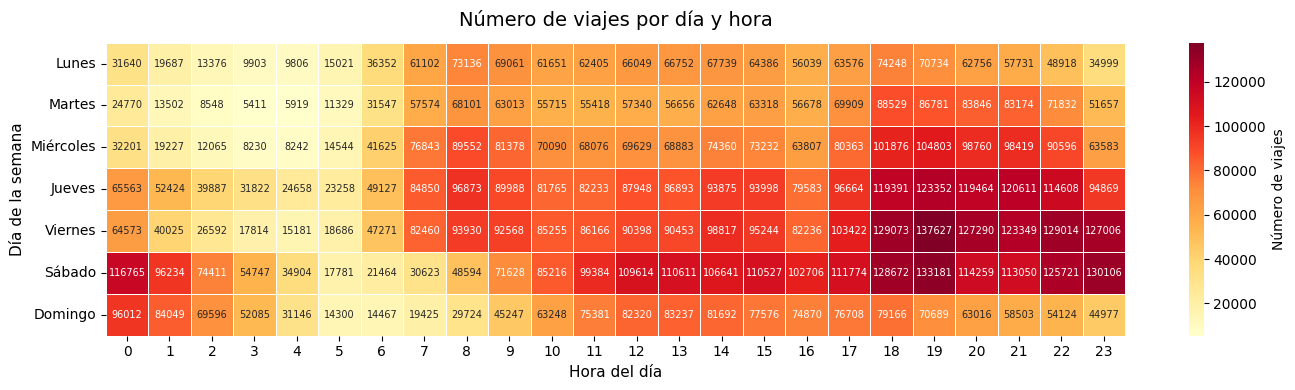

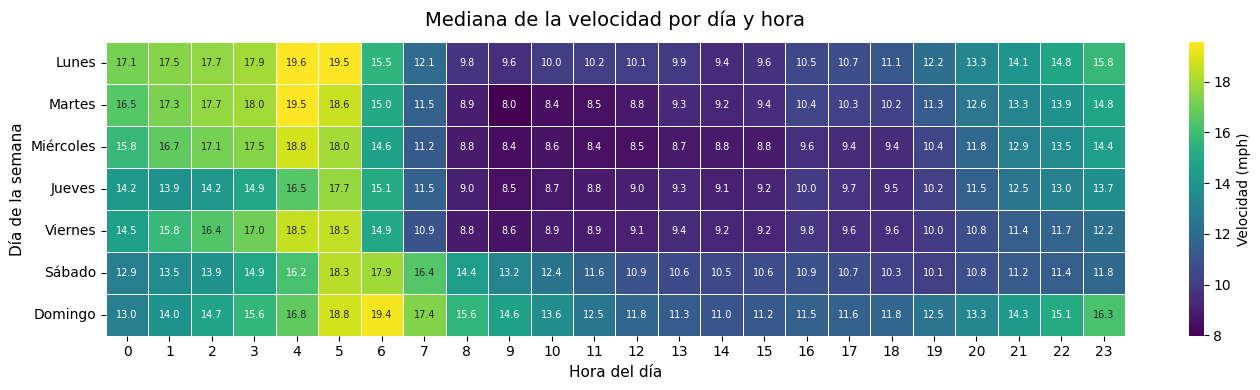

In [ ]:
fig_distance, _ = plot_week_hour_heatmap(
    trip_distance_by_hour_pd, title='Mediana de la distancia por día y hora',
    cbar_label='Distancia (millas)', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '08_heatmap_trip_distance', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    total_amount_by_hour_pd, title='Mediana del importe por milla por día y hora',
    cbar_label='Importe por milla', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '09_heatmap_amount_per_mile', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    n_trips_by_hour_pd, title='Número de viajes por día y hora',
    cbar_label='Número de viajes', cmap='YlOrRd', fmt='.0f'
)
_ = save_figure(fig_distance, '10_heatmap_trip_count', images_dir)

fig_distance, _ = plot_week_hour_heatmap(
    speed_by_hour_pd, title='Mediana de la velocidad por día y hora',
    cbar_label='Velocidad (mph)', cmap='viridis', fmt='.1f'
)
_ = save_figure(fig_distance, '11_heatmap_speed', images_dir)


#### Lectura de los patrones temporales

Los cuatro mapas de calor muestran comportamientos complementarios:

- la **distancia mediana** aumenta durante la madrugada y disminuye durante las horas centrales del día;
- el **importe por milla** es mayor durante buena parte del horario diurno de los días laborables y menor en determinadas franjas nocturnas;
- el **volumen de viajes** se concentra especialmente entre el jueves y el sábado, con máximos durante la tarde y la noche;
- la **velocidad mediana** aumenta en las franjas con menor demanda y disminuye durante las horas de mayor actividad urbana.

La combinación de estas métricas muestra la relación entre demanda y condiciones de circulación: las franjas con mayor concentración de viajes tienden a presentar velocidades medianas inferiores, mientras que las horas nocturnas y de madrugada presentan trayectos más rápidos y, en determinados momentos, más largos.

### 8.5. Volumen total de viajes por día

Los mapas de calor anteriores permiten analizar simultáneamente la dimensión horaria y semanal de la movilidad.

Como visión complementaria, se agrega el número de viajes de las 24 horas para obtener el **volumen total registrado en cada día de la semana**.

Esta representación simplificada permite comparar directamente la demanda diaria y facilita la identificación de diferencias globales entre días laborables y fin de semana, mientras que los mapas de calor conservan el detalle necesario para estudiar cómo se distribuye esa actividad a lo largo del día.

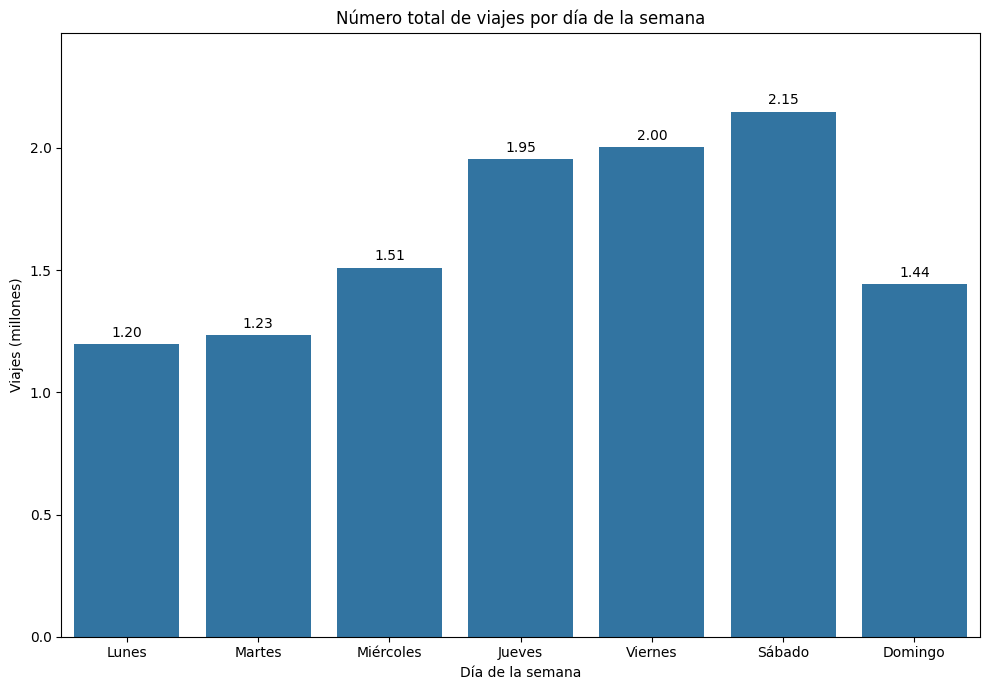

In [ ]:
# ============================================================
# AGREGACIÓN DEL VOLUMEN DIARIO
# ============================================================
daily_trips_pd = (
    n_trips_by_hour_pd
    .set_index('day_of_week')
    .sum(axis=1)
    .reindex(DAYS_ORDER)
    .div(1_000_000)
    .reset_index(name='n_trips_millions')
)


# ============================================================
# VOLUMEN TOTAL DE VIAJES POR DÍA
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(data=daily_trips_pd, x='day_of_week', y='n_trips_millions', ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.2f}', padding=3)

ax.set_title('Número total de viajes por día de la semana')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Viajes (millones)')

ax.set_xticks(range(len(DAYS_ORDER)))
ax.set_xticklabels([DAY_LABELS[day] for day in DAYS_ORDER])
ax.tick_params(axis='x', rotation=0)

ax.margins(y=0.15)

fig.tight_layout()

_ = save_figure(fig, '12_daily_trip_volume', images_dir)

plt.show()

#### Lectura del volumen semanal

El **sábado** registra el mayor volumen del periodo, con aproximadamente **2,15 millones de viajes**, seguido del viernes (**2,00 millones**) y el jueves (**1,95 millones**).

El lunes presenta el menor volumen, con aproximadamente **1,20 millones**, mientras que el domingo desciende hasta **1,44 millones** después del máximo del sábado.

El patrón confirma que la demanda no evoluciona únicamente según la distinción laborable/fin de semana: aumenta progresivamente durante la segunda mitad de la semana, alcanza su máximo el sábado y se reduce de forma clara el domingo.

## 9. Preparación y exploración geoespacial

### 9.1. Distritos comunitarios de Nueva York

El análisis geoespacial utiliza los límites de los **distritos comunitarios de Nueva York (NYC Community Districts)** obtenidos a partir del fichero GeoJSON.

Debido al reducido tamaño de esta información territorial, los polígonos se gestionan mediante **GeoPandas**, mientras que el dataset principal de viajes permanece distribuido en Spark.

La referencia territorial fue cargada previamente durante la evaluación del impacto de la depuración. En esta sección se reutiliza el `GeoDataFrame` ya validado para completar la exploración cartográfica y preparar las operaciones espaciales posteriores.

El `GeoDataFrame` contiene la geometría de cada distrito y su denominación, enlazada mediante el identificador `BoroCD`.

In [ ]:
# ============================================================
# RESUMEN DE LA REFERENCIA TERRITORIAL
# ============================================================
geometry_load_summary_pd = pd.DataFrame({
    'Indicador': [
        'Fichero',
        'Geometrías leídas',
        'Distritos enlazados',
        'BoroCD únicos',
        'CRS',
        'Tipo geométrico'
    ],
    'Valor': [
        geojson_path.name,
        len(gdf_raw),
        len(nyc_gdf),
        nyc_gdf['BoroCD'].nunique(),
        str(nyc_gdf.crs),
        ', '.join(sorted(nyc_gdf.geom_type.unique()))
    ]
}).set_index('Indicador')

geometry_load_summary_pd

,Valor
Indicador,
Fichero,NYC_Community_Districts.geojson
Geometrías leídas,71
Distritos enlazados,59
BoroCD únicos,59
CRS,EPSG:4326
Tipo geométrico,"MultiPolygon, Polygon"


### 9.2. Validación de la información territorial

Antes de utilizar las geometrías en las operaciones espaciales se comprueba que el GeoDataFrame contiene los identificadores, nombres y geometrías necesarios para representar los distritos y construir posteriormente el DataFrame espacial de Spark.

In [ ]:
# ============================================================
# VALIDACIÓN DE LA INFORMACIÓN TERRITORIAL
# ============================================================
required_geo_columns = {
    'BoroCD',
    'district',
    'geometry',
}

assert required_geo_columns.issubset(nyc_gdf.columns)
assert isinstance(nyc_gdf, gpd.GeoDataFrame)
assert not nyc_gdf.empty
assert nyc_gdf.geometry.notna().all()

borough_names = {
    1: 'Manhattan',
    2: 'Bronx',
    3: 'Brooklyn',
    4: 'Queens',
    5: 'Staten Island'
}

territorial_validation_pd = pd.DataFrame({
    'BoroCD': nyc_gdf['BoroCD'],
    'Borough': (nyc_gdf['BoroCD'].floordiv(100).map(borough_names)),
    'Distrito': nyc_gdf['district'],
    'Geometría': nyc_gdf.geom_type,
    'Válida': nyc_gdf.geometry.is_valid,
    'Vacía': nyc_gdf.geometry.is_empty
})

territorial_validation_pd = (
    territorial_validation_pd.sort_values('BoroCD').set_index('BoroCD')
)

territorial_validation_pd

,Borough,Distrito,Geometría,Válida,Vacía
BoroCD,,,,,
101,Manhattan,Financial District (CD1),MultiPolygon,True,False
102,Manhattan,Greenwich Village and Soho (CD2),Polygon,True,False
103,Manhattan,Lower East Side and Chinatown (CD3),Polygon,True,False
104,Manhattan,Clinton and Chelsea (CD4),Polygon,True,False
105,Manhattan,Midtown (CD5),Polygon,True,False
106,Manhattan,Stuyvesant Town and Turtle Bay (CD6),MultiPolygon,True,False
107,Manhattan,Upper West Side (CD7),Polygon,True,False
108,Manhattan,Upper East Side (CD8),MultiPolygon,True,False
109,Manhattan,Morningside Heights and Hamilton Heights (CD9),Polygon,True,False


In [ ]:
# ============================================================
# MUESTREO CARTOGRÁFICO
# ============================================================
sample_fraction = 0.002 / 100

random_seed = 5555

viajes_pd = (
    analysis_trips_df
    # Solo se traslada al driver una muestra reproducible destinada a la representación
    .sample(
        withReplacement=False,
        fraction=sample_fraction,
        seed=random_seed
    )
    .limit(1000)
    .select(
        'pickup_latitude',
        'pickup_longitude',
        'dropoff_latitude',
        'dropoff_longitude'
    )
    .toPandas()
)


# ============================================================
# VALIDACIÓN DE LA MUESTRA
# ============================================================
expected_sample_size = round(parquet_rows * sample_fraction)

sample_tolerance = max(30, round(expected_sample_size * 0.20))

sample_difference = len(viajes_pd) - expected_sample_size

expected_sample_columns = [
    'pickup_latitude',
    'pickup_longitude',
    'dropoff_latitude',
    'dropoff_longitude'
]

sample_size_ok = abs(sample_difference) <= sample_tolerance

sample_columns_ok = list(viajes_pd.columns) == expected_sample_columns

sample_validation_ok = sample_size_ok and sample_columns_ok

assert sample_size_ok
assert sample_columns_ok

sample_validation_pd = pd.DataFrame({
    'Indicador': [
        'Fracción solicitada',
        'Registros esperados',
        'Registros obtenidos',
        'Diferencia',
        'Tolerancia',
        'Columnas geográficas',
        'Columnas correctas',
        'Estado'
    ],
    'Valor': [
        f'{sample_fraction * 100:.3f} %',
        expected_sample_size,
        len(viajes_pd),
        sample_difference,
        f'± {sample_tolerance}',
        len(viajes_pd.columns),
        'Sí' if sample_columns_ok else 'No',
        'OK' if sample_validation_ok else 'REVISAR'
    ]
}).set_index('Indicador')

sample_validation_pd

,Valor
Indicador,
Fracción solicitada,0.002 %
Registros esperados,230
Registros obtenidos,197
Diferencia,-33
Tolerancia,± 46
Columnas geográficas,4
Columnas correctas,Sí
Estado,OK


#### Comprobación territorial

La lectura inicial del GeoJSON contiene **71 geometrías**. Tras incorporar la tabla de referencia mediante `BoroCD`, el análisis conserva **59 distritos comunitarios únicos**, que constituyen las unidades territoriales utilizadas en los spatial joins posteriores.

Las geometrías enlazadas se representan como `Polygon` o `MultiPolygon` y mantienen el sistema de referencia geográfica **EPSG:4326**, compatible con las coordenadas de longitud y latitud de los viajes.

La tabla de validación permite comprobar individualmente el tipo geométrico, su validez y la ausencia de geometrías vacías antes de trasladar esta información a Spark.

### 9.3. Exploración cartográfica

Para comprobar visualmente la cobertura territorial de los datos se representan los límites de los distritos junto con una muestra de ubicaciones de los viajes.

La representación utiliza **Folium** a través de la función auxiliar `plot_community_districts_map`. El dataset completo permanece distribuido en Spark y únicamente la pequeña muestra preparada anteriormente se utiliza para construir el mapa interactivo.

In [ ]:
# ============================================================
# VISUALIZACIÓN EN FOLIUM
# ============================================================
# Se representan los distritos y los puntos de recogida correspondientes a la muestra.
nyc_map = plot_community_districts_map(nyc_gdf, viajes_pd)


# ============================================================
# EXPORTACIÓN DEL MAPA INTERACTIVO
# ============================================================
map_output_path = databricks_output_dir / 'nyc_community_districts_map.html'

nyc_map.save(str(map_output_path))

# Visualización interactiva desactivada en la versión pública de GitHub.
# El mapa completo se exporta como archivo HTML.
# nyc_map

In [ ]:
# ============================================================
# VALIDACIÓN DE LA VISUALIZACIÓN
# ============================================================
assert nyc_map.__class__.__name__ == 'Map'

print('Mapa interactivo generado correctamente.')

Mapa interactivo generado correctamente.


#### Lectura cartográfica

La información territorial incorpora **59 distritos comunitarios** en el sistema de referencia `EPSG:4326`.

El mapa superpone estos límites con una muestra reproducible de puntos de recogida para comprobar visualmente la coherencia de las coordenadas y su relación con la geometría urbana.

La muestra se utiliza exclusivamente con fines exploratorios y de validación visual; los spatial joins posteriores se realizan sobre el dataset distribuido completo.

## 10. Procesamiento geoespacial distribuido en Databricks

### 10.1. Geometrías espaciales nativas

Una vez preparada la información territorial, el siguiente objetivo es determinar el distrito comunitario correspondiente a los puntos de recogida y destino de cada viaje.

En esta implementación, el procesamiento espacial se realiza mediante las **funciones geoespaciales nativas de Databricks**, utilizando directamente el tipo `GEOMETRY` y las funciones `ST_*` disponibles en el entorno Serverless.

El flujo combina:

- polígonos de los distritos trasladados desde GeoPandas a geometrías nativas de Spark;
- puntos de recogida y destino creados a partir de longitud y latitud;
- `ST_Contains` como predicado espacial;
- `broadcast joins` para distribuir la pequeña tabla territorial;
- `left joins` para conservar todos los viajes aunque alguna coordenada no pueda asignarse a un distrito.

El resultado incorpora a cada viaje las columnas `pickup_district` y `dropoff_district`.

A diferencia de la implementación local, esta fase no requiere Apache Sedona ni dependencias geoespaciales adicionales para Spark.

### 10.2. Conversión de polígonos a geometrías nativas

Las geometrías de los distritos se encuentran inicialmente en un `GeoDataFrame`.

Para trasladarlas a Spark se serializan temporalmente en formato **WKT (Well-Known Text)** y posteriormente se reconstruyen como objetos `GEOMETRY` mediante `ST_GeomFromWKT`.

La conversión fue realizada previamente durante el análisis territorial de la depuración. En esta fase se reutiliza el DataFrame espacial ya validado para efectuar el enriquecimiento completo de los viajes.

In [ ]:
# ============================================================
# POLÍGONOS DISPONIBLES PARA EL PROCESAMIENTO ESPACIAL
# ============================================================
districts_df.printSchema()

root
 |-- district: string (nullable = true)
 |-- district_geom: geometry (nullable = true)



### 10.3. Construcción de puntos espaciales

Las coordenadas de cada viaje se transforman en geometrías puntuales mediante `ST_Point`.

La función utiliza el orden espacial convencional:

**X = longitud**  
**Y = latitud**

Se generan dos geometrías por viaje, correspondientes al punto de recogida y al punto de destino.

In [ ]:
# ============================================================
# PUNTOS DE RECOGIDA Y DESTINO
# ============================================================
trips_with_points = (
    analysis_trips_df

    # ST_Point utiliza el orden X/Y: longitud primero, latitud después
    .withColumn('pickup_point', F.expr('ST_Point(pickup_longitude, pickup_latitude)'))
    .withColumn('dropoff_point', F.expr('ST_Point(dropoff_longitude, dropoff_latitude)'))
)

# ============================================================
# MUESTRA DE GEOMETRÍAS PUNTUALES
# ============================================================
points_preview_pd = (
    trips_with_points
    .select(
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'trip_distance',
        F.expr('ST_AsText(pickup_point)').alias('pickup_point'),
        F.expr('ST_AsText(dropoff_point)').alias('dropoff_point'),
    )
    .limit(15)
    .toPandas()
)

coordinate_columns = [
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
]

points_preview_pd.index = range(1, len(points_preview_pd) + 1)

points_preview_pd.index.name = 'Viaje'

points_preview_pd[coordinate_columns] = points_preview_pd[coordinate_columns].round(5)

points_preview_pd

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_distance,pickup_point,dropoff_point
Viaje,,,,,,,
1,-73.95998,40.78209,-73.98749,40.76951,2.40,POINT(-73.9599838256836 40.7820930480957),POINT(-73.98748779296875 40.769508361816406)
2,-73.97890,40.76221,-73.99276,40.75831,1.30,POINT(-73.9789047241211 40.76221466064453),POINT(-73.99275970458984 40.7583122253418)
3,-73.98330,40.74786,-73.97475,40.74915,0.71,POINT(-73.9832992553711 40.74786376953125),POINT(-73.97474670410156 40.7491455078125)
4,-74.00752,40.74338,-73.97566,40.75956,2.73,POINT(-74.00752258300781 40.74338150024414),POINT(-73.97566223144531 40.75955581665039)
5,-73.96981,40.79986,-73.97883,40.78777,0.95,POINT(-73.96981048583984 40.79985809326172),POINT(-73.97882843017578 40.78776931762695)
6,-73.99940,40.73373,-73.96686,40.68660,4.71,POINT(-73.99940490722656 40.73373031616211),POINT(-73.96685791015625 40.68660354614258)
7,-73.95959,40.78104,-73.96970,40.78801,1.01,POINT(-73.9595947265625 40.78104019165039),POINT(-73.96969604492188 40.78801345825195)
8,-73.78189,40.64481,-73.99565,40.69817,19.60,POINT(-73.78189086914062 40.644805908203125),POINT(-73.99565124511719 40.69817352294922)
9,-73.99728,40.72610,-73.98603,40.73913,1.30,POINT(-73.99728393554688 40.726104736328125),POINT(-73.98603057861328 40.739131927490234)


### 10.4. Spatial joins mediante `ST_Contains`

El distrito correspondiente a cada coordenada se obtiene comprobando qué polígono contiene cada punto mediante `ST_Contains`.

La tabla de distritos es muy pequeña frente al dataset de viajes, por lo que se utiliza `broadcast` para distribuirla y evitar un movimiento innecesario del DataFrame principal.

Los joins se realizan como `left join` para conservar los viajes aunque una coordenada no se encuentre dentro de ninguno de los polígonos disponibles.

Las operaciones espaciales se ejecutan mediante las funciones nativas `ST_*` de Databricks.

In [ ]:
# ============================================================
# DISTRITOS PARA LOS SPATIAL JOINS
# ============================================================
pickup_districts = districts_df.withColumnRenamed('district', 'pickup_district')

dropoff_districts = districts_df.withColumnRenamed('district', 'dropoff_district')


# ============================================================
# DISTRITO DE RECOGIDA
# ============================================================
trips_pickup = (
    trips_with_points
    # La tabla de distritos es pequeña y se distribuye mediante broadcast
    # para evitar redistribuir el DataFrame principal de viajes
    .join(
        F.broadcast(pickup_districts),
        F.expr('ST_Contains(district_geom, pickup_point)'),
        how='left'
    )
    .drop('pickup_point', 'district_geom')
)


# ============================================================
# DISTRITO DE DESTINO
# ============================================================
analysis_trips_with_districts = (
    trips_pickup
    # El segundo spatial join incorpora el distrito de destino
    # manteniendo la misma estrategia que para el pickup
    .join(
        F.broadcast(dropoff_districts),
        F.expr('ST_Contains(district_geom, dropoff_point)'),
        how='left'
    )
    .drop('dropoff_point', 'district_geom')
)


# ============================================================
# RESUMEN DE LOS SPATIAL JOINS
# ============================================================
spatial_join_summary_pd = pd.DataFrame({
    'Asignación': [
        'Pickup',
        'Dropoff'
    ],
    'Punto': [
        'pickup_point',
        'dropoff_point'
    ],
    'Resultado': [
        'pickup_district',
        'dropoff_district'
    ],
    'Condición espacial': [
        'ST_Contains(district_geom, pickup_point)',
        'ST_Contains(district_geom, dropoff_point)'
    ],
    'Join': [
        'left',
        'left'
    ],
    'Broadcast': [
        f'{len(nyc_gdf)} polígonos',
        f'{len(nyc_gdf)} polígonos'
    ]
}).set_index('Asignación')

spatial_join_summary_pd

,Punto,Resultado,Condición espacial,Join,Broadcast
Asignación,,,,,
Pickup,pickup_point,pickup_district,"ST_Contains(district_geom, pickup_point)",left,59 polígonos
Dropoff,dropoff_point,dropoff_district,"ST_Contains(district_geom, dropoff_point)",left,59 polígonos


### 10.5. Validación del enriquecimiento espacial

El DataFrame resultante mantiene la información original de los viajes e incorpora los distritos correspondientes a los puntos de recogida y destino.

Las coordenadas que no pueden asociarse a ninguno de los polígonos pueden producir valores nulos; estos registros se conservan deliberadamente.

In [ ]:
# ============================================================
# VALIDACIÓN DEL ENRIQUECIMIENTO ESPACIAL
# ============================================================
assert 'pickup_district' in analysis_trips_with_districts.columns
assert 'dropoff_district' in analysis_trips_with_districts.columns

spatial_types = dict(analysis_trips_with_districts.dtypes)


spatial_validation_pd = pd.DataFrame({
    'Columna': [
        'pickup_district',
        'dropoff_district'
    ],
    'Tipo Spark': [
        spatial_types['pickup_district'],
        spatial_types['dropoff_district']
    ],
    'Origen': [
        'pickup_point',
        'dropoff_point'
    ],
    'Condición espacial': [
        'ST_Contains(district_geom, pickup_point)',
        'ST_Contains(district_geom, dropoff_point)'
    ],
    'Estado': [
        'OK' if 'pickup_district' in analysis_trips_with_districts.columns else 'NO',
        'OK' if 'dropoff_district' in analysis_trips_with_districts.columns else 'NO'
    ]
}).set_index('Columna')

print(f'Columnas antes del enriquecimiento : {len(analysis_trips_df.columns)}')

print(f'Columnas después del enriquecimiento: {len(analysis_trips_with_districts.columns)}')

spatial_validation_pd

Columnas antes del enriquecimiento : 23
Columnas después del enriquecimiento: 25


,Tipo Spark,Origen,Condición espacial,Estado
Columna,,,,
pickup_district,string,pickup_point,"ST_Contains(district_geom, pickup_point)",OK
dropoff_district,string,dropoff_point,"ST_Contains(district_geom, dropoff_point)",OK


### 10.6. Dataset espacial de análisis

Una vez completados los spatial joins se conserva únicamente la información necesaria para los análisis territoriales posteriores.

La proyección reduce el número de columnas y genera un DataFrame ligero desde el punto de vista estructural, manteniendo únicamente el día de la semana y los distritos de origen y destino.

La persistencia en memoria utilizada en la implementación local se mantiene desactivada debido a las restricciones del compute Serverless.

In [ ]:
# ============================================================
# DATAFRAME ESPACIAL PARA ANÁLISIS
# ============================================================
spatial_analysis_df = analysis_trips_with_districts.select(
    'day_of_week',
    'pickup_district',
    'dropoff_district'
)

# Desactivado en Databricks Free / Serverless
# spatial_analysis_df = spatial_analysis_df.cache()


# ============================================================
# MUESTRA DEL DATASET ESPACIAL
# ============================================================
spatial_analysis_preview_pd = spatial_analysis_df.limit(15).toPandas()

spatial_analysis_preview_pd['pickup_district'] = (
    spatial_analysis_preview_pd['pickup_district']
    .replace(DISTRICT_LABELS)
)

spatial_analysis_preview_pd['dropoff_district'] = (
    spatial_analysis_preview_pd['dropoff_district']
    .replace(DISTRICT_LABELS)
)

spatial_analysis_preview_pd['day_of_week'] = (
    spatial_analysis_preview_pd['day_of_week']
    .replace(DAY_LABELS)
)

spatial_analysis_preview_pd.index = range(1, len(spatial_analysis_preview_pd) + 1)

spatial_analysis_preview_pd.index.name = 'Viaje'

spatial_analysis_preview_pd

,day_of_week,pickup_district,dropoff_district
Viaje,,,
1,Sábado,Chelsea / Clinton,Midtown
2,Sábado,Upper West Side,Upper West Side
3,Sábado,None,Fort Greene / Brooklyn Hts
4,Sábado,Midtown,Upper East Side
5,Sábado,Midtown,Midtown
6,Sábado,Midtown,Chelsea / Clinton
7,Sábado,Upper East Side,Chelsea / Clinton
8,Sábado,Greenwich / SoHo,Fort Greene / Brooklyn Hts
9,Sábado,Upper East Side,Upper West Side


### 10.7. Cobertura del enriquecimiento espacial

Los spatial joins se realizan mediante `left join`, por lo que todos los viajes se conservan aunque alguna coordenada no pueda asociarse a uno de los polígonos disponibles.

Se cuantifica la **cobertura espacial** obtenida para los puntos de recogida y destino.

La ausencia de distrito no implica necesariamente un registro erróneo: puede corresponder a ubicaciones situadas fuera de la cobertura de los polígonos utilizados. Por este motivo, estos registros se conservan y se contabilizan explícitamente.

In [ ]:
# ============================================================
# COBERTURA DEL ENRIQUECIMIENTO ESPACIAL
# ============================================================
spatial_coverage = (
    spatial_analysis_df
    .agg(
        F.count('*').alias('total_trips'),
        F.sum(F.col('pickup_district').isNull().cast('int')).alias('pickup_unassigned'),
        F.sum(F.col('dropoff_district').isNull().cast('int')).alias('dropoff_unassigned'),
        F.sum(
            (
                F.col('pickup_district').isNotNull() & F.col('dropoff_district').isNotNull()
            ).cast('int')
        ).alias('both_assigned')
    )
    .first()
)

spatial_total = spatial_coverage['total_trips']

pickup_unassigned = spatial_coverage['pickup_unassigned']

pickup_assigned = spatial_total - pickup_unassigned

dropoff_unassigned = spatial_coverage['dropoff_unassigned']

dropoff_assigned = spatial_total - dropoff_unassigned

both_assigned = spatial_coverage['both_assigned']

incomplete_assignment = spatial_total - both_assigned


# ============================================================
# VALIDACIÓN DE CONSERVACIÓN
# ============================================================
assert spatial_total == parquet_rows
assert pickup_unassigned > 0
assert dropoff_unassigned > 0


# ============================================================
# RESUMEN DE COBERTURA ESPACIAL
# ============================================================
spatial_coverage_pd = pd.DataFrame({
    'Asignación': [
        'Pickup',
        'Dropoff',
        'Pickup y dropoff'
    ],
    'Asignados': [
        pickup_assigned,
        dropoff_assigned,
        both_assigned
    ],
    'No asignados / incompletos': [
        pickup_unassigned,
        dropoff_unassigned,
        incomplete_assignment
    ],
    'Cobertura (%)': [
        100 * pickup_assigned / spatial_total,
        100 * dropoff_assigned / spatial_total,
        100 * both_assigned / spatial_total
    ]
}).set_index('Asignación')

spatial_coverage_pd['Cobertura (%)'] = spatial_coverage_pd['Cobertura (%)'].round(2)

print(f'Conservación de filas: {parquet_rows:,} → {spatial_total:,} · OK')

_ = save_table(spatial_coverage_pd, '08_spatial_coverage', tables_dir)

spatial_coverage_pd

Conservación de filas: 11,488,991 → 11,488,991 · OK


,Asignados,No asignados / incompletos,Cobertura (%)
Asignación,,,
Pickup,10665395,823596,92.83
Dropoff,10927183,561808,95.11
Pickup y dropoff,10318062,1170929,89.81


#### Cobertura obtenida

El enriquecimiento espacial permite asignar un distrito al **92,83 %** de los puntos de recogida y al **95,11 %** de los puntos de destino. En el **89,81 %** de los viajes se dispone simultáneamente de distrito de origen y de destino.

Los registros restantes se conservan debido al uso de `left join`. La ausencia de asignación no se interpreta automáticamente como un error, ya que puede corresponder a coordenadas situadas fuera de la cobertura de los polígonos utilizados.

## 11. Patrones espaciales de movilidad

### 11.1. Viajes iniciados por distrito y día

Una vez asignado un distrito a cada punto de recogida, los viajes se agregan por distrito y día de la semana.

La agregación continúa realizándose en Spark. Solo el resultado final, de tamaño reducido, se convierte a Pandas para facilitar su análisis y representación.

In [ ]:
# ============================================================
# VIAJES INICIADOS POR DISTRITO Y DÍA
# ============================================================
trips_per_district_pd = (
    spatial_analysis_df
    .groupBy('pickup_district')
    .pivot('day_of_week', DAYS_ORDER)
    .count()
    # La agregación territorial produce un resultado pequeño, por lo que se traslada a Pandas
    # para su análisis y visualización
    .toPandas()
)


# ============================================================
# ACTIVIDAD SEMANAL POR DISTRITO
# ============================================================
district_activity_pd = trips_per_district_pd.dropna(subset=['pickup_district']).copy()

district_activity_pd[DAYS_ORDER] = district_activity_pd[DAYS_ORDER].fillna(0).astype('int64')

district_activity_pd['total_week'] = district_activity_pd[DAYS_ORDER].sum(axis=1)

district_activity_pd = district_activity_pd.sort_values(
    'total_week', ascending=False
).reset_index(drop=True)

In [ ]:
# ============================================================
# DISTRITOS CON MAYOR VOLUMEN SEMANAL
# ============================================================
district_activity_preview_pd = district_activity_pd.head(15)[[
    'pickup_district',
    'total_week',
    *DAYS_ORDER
]].copy()

district_activity_preview_pd['pickup_district'] = (
    district_activity_preview_pd['pickup_district']
    .replace(DISTRICT_LABELS)
)

district_activity_preview_pd = district_activity_preview_pd.rename(
    columns={
        'pickup_district': 'Distrito',
        'total_week': 'Total semanal',
        **{day: DAY_LABELS[day] for day in DAYS_ORDER}
    }
).set_index('Distrito')

_ = save_table(district_activity_preview_pd, '09_top_districts', tables_dir)

district_activity_preview_pd

,Total semanal,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
Distrito,,,,,,,,
Midtown,2742740,295540,324336,399019,481440,481017,457309,304079
Upper East Side,1596782,179772,184966,225668,276759,286001,275578,168038
Chelsea / Clinton,1224809,127388,127248,152958,201183,211295,239215,165522
Stuyvesant / Turtle Bay,1211187,123870,130515,161791,212559,218767,222912,140773
Greenwich / SoHo,1121282,101164,106788,133911,175152,193794,249872,160601
Upper West Side,988010,104766,107410,129197,165949,168522,188374,123792
LES / Chinatown,670671,49569,49182,61019,95858,108022,180761,126260
Financial District,526935,53317,59064,75386,98787,98803,86836,54742
East Harlem,99711,10960,10380,11789,16821,18191,19284,12286


In [ ]:
# ============================================================
# VALIDACIÓN DE REPRODUCIBILIDAD
# ============================================================
district_assigned_total = int(district_activity_pd['total_week'].sum())

top_district_row = district_activity_pd.iloc[0]

top_district_ok = (top_district_row['pickup_district'] == 'Midtown (CD5)')

top_district_count_ok = (int(top_district_row['total_week']) == 2_742_740)

pickup_conservation_ok = (district_assigned_total == pickup_assigned)

assert top_district_ok
assert top_district_count_ok
assert pickup_conservation_ok

spatial_reproducibility_pd = pd.DataFrame({
    'Control': [
        'Distrito con mayor actividad',
        'Recogidas en Midtown',
        'Viajes con pickup territorial'
    ],
    'Esperado': [
        'Midtown',
        '2,742,740',
        f'{pickup_assigned:,}'
    ],
    'Obtenido': [
        DISTRICT_LABELS.get(
            top_district_row['pickup_district'],
            top_district_row['pickup_district']
        ),
        f"{int(top_district_row['total_week']):,}",
        f'{district_assigned_total:,}'
    ],
    'Estado': [
        'OK' if top_district_ok else 'REVISAR',
        'OK' if top_district_count_ok else 'REVISAR',
        'OK' if pickup_conservation_ok else 'REVISAR'
    ]
}).set_index('Control')

spatial_reproducibility_pd

,Esperado,Obtenido,Estado
Control,,,
Distrito con mayor actividad,Midtown,Midtown,OK
Recogidas en Midtown,"2,742,740","2,742,740",OK
Viajes con pickup territorial,"10,665,395","10,665,395",OK


#### Concentración territorial de las recogidas

La actividad presenta una concentración geográfica muy marcada. **Midtown** registra aproximadamente **2,74 millones de recogidas**, seguido de **Upper East Side** con cerca de **1,60 millones**.

Chelsea / Clinton, Stuyvesant / Turtle Bay y Greenwich / SoHo superan también el millón de recogidas durante el periodo analizado.

La diferencia respecto a los siguientes distritos muestra que una parte muy importante de la demanda se concentra en el núcleo de Manhattan.

Los resultados reproducen además el ranking territorial obtenido durante la evaluación de la depuración, confirmando que el posterior procesamiento espacial nativo de Databricks mantiene la misma estructura territorial.

### 11.2. Distritos con mayor actividad

Para facilitar la comparación se seleccionan los 15 distritos con mayor número total de viajes iniciados durante la semana.

El mapa de calor permite comparar simultáneamente la intensidad de actividad de cada distrito y su distribución entre los distintos días.

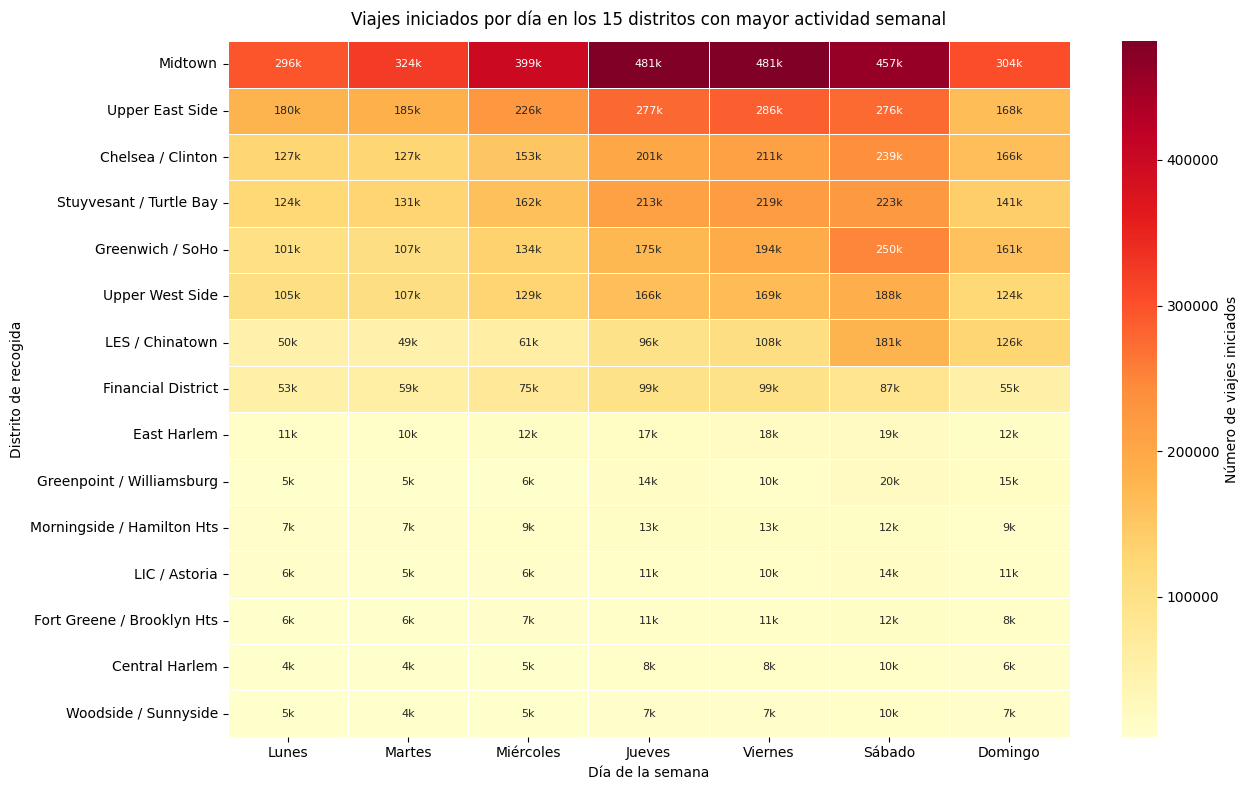

In [ ]:
# ============================================================
# DISTRITOS CON MAYOR ACTIVIDAD
# ============================================================
districts_heatmap_pd = (
    district_activity_pd
    .head(15)
    .set_index('pickup_district')[DAYS_ORDER]
)


# ============================================================
# HEATMAP DE ACTIVIDAD POR DISTRITO Y DÍA
# ============================================================
districts_heatmap_plot_pd = districts_heatmap_pd.rename(index=DISTRICT_LABELS, columns=DAY_LABELS)

fig_districts, ax = plt.subplots(figsize=(13, 8))

annot = districts_heatmap_plot_pd.map(
    lambda value: (f'{value / 1_000:.0f}k' if value >= 1_000 else f'{value:.0f}')
)

sns.heatmap(
    districts_heatmap_plot_pd, ax=ax, cmap='YlOrRd', annot=annot, fmt='', linewidths=0.5,
    annot_kws={'size': 8}, cbar_kws={'label': 'Número de viajes iniciados'}
)

plt.title('Viajes iniciados por día en los 15 distritos con mayor actividad semanal', pad=12)

plt.xlabel('Día de la semana')
plt.ylabel('Distrito de recogida')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

_ = save_figure(fig_districts, '13_district_activity_heatmap', images_dir)

plt.show()

#### Distribución semanal por distrito

La intensidad semanal no evoluciona de forma idéntica en todos los distritos.

Midtown mantiene el mayor volumen durante todos los días, con niveles especialmente elevados entre jueves y sábado. Otros distritos muestran un componente más acusado de fin de semana: Greenwich / SoHo y Lower East Side / Chinatown incrementan notablemente su actividad el sábado.

El heatmap permite distinguir, por tanto, áreas con una demanda elevada y relativamente estable de otras cuya actividad está más vinculada a determinados momentos de la semana.

### 11.3. Flujos entre distritos

El enriquecimiento espacial permite analizar conjuntamente los distritos de origen y destino de los viajes.

Para mantener una representación interpretable se seleccionan los **15 distritos con mayor número total de recogidas** y se construye una matriz origen-destino mediante una agregación distribuida en Spark.

La matriz se representa desde dos perspectivas complementarias:

- **volumen absoluto de viajes**, que permite identificar los flujos con mayor número de desplazamientos;
- **distribución porcentual entre los destinos seleccionados**, que normaliza cada fila de la matriz y permite comparar el peso relativo de los principales destinos dentro del conjunto representado.

Esta segunda representación evita que los distritos con mayor actividad dominen completamente la escala visual y facilita la identificación de patrones relativos de movilidad.

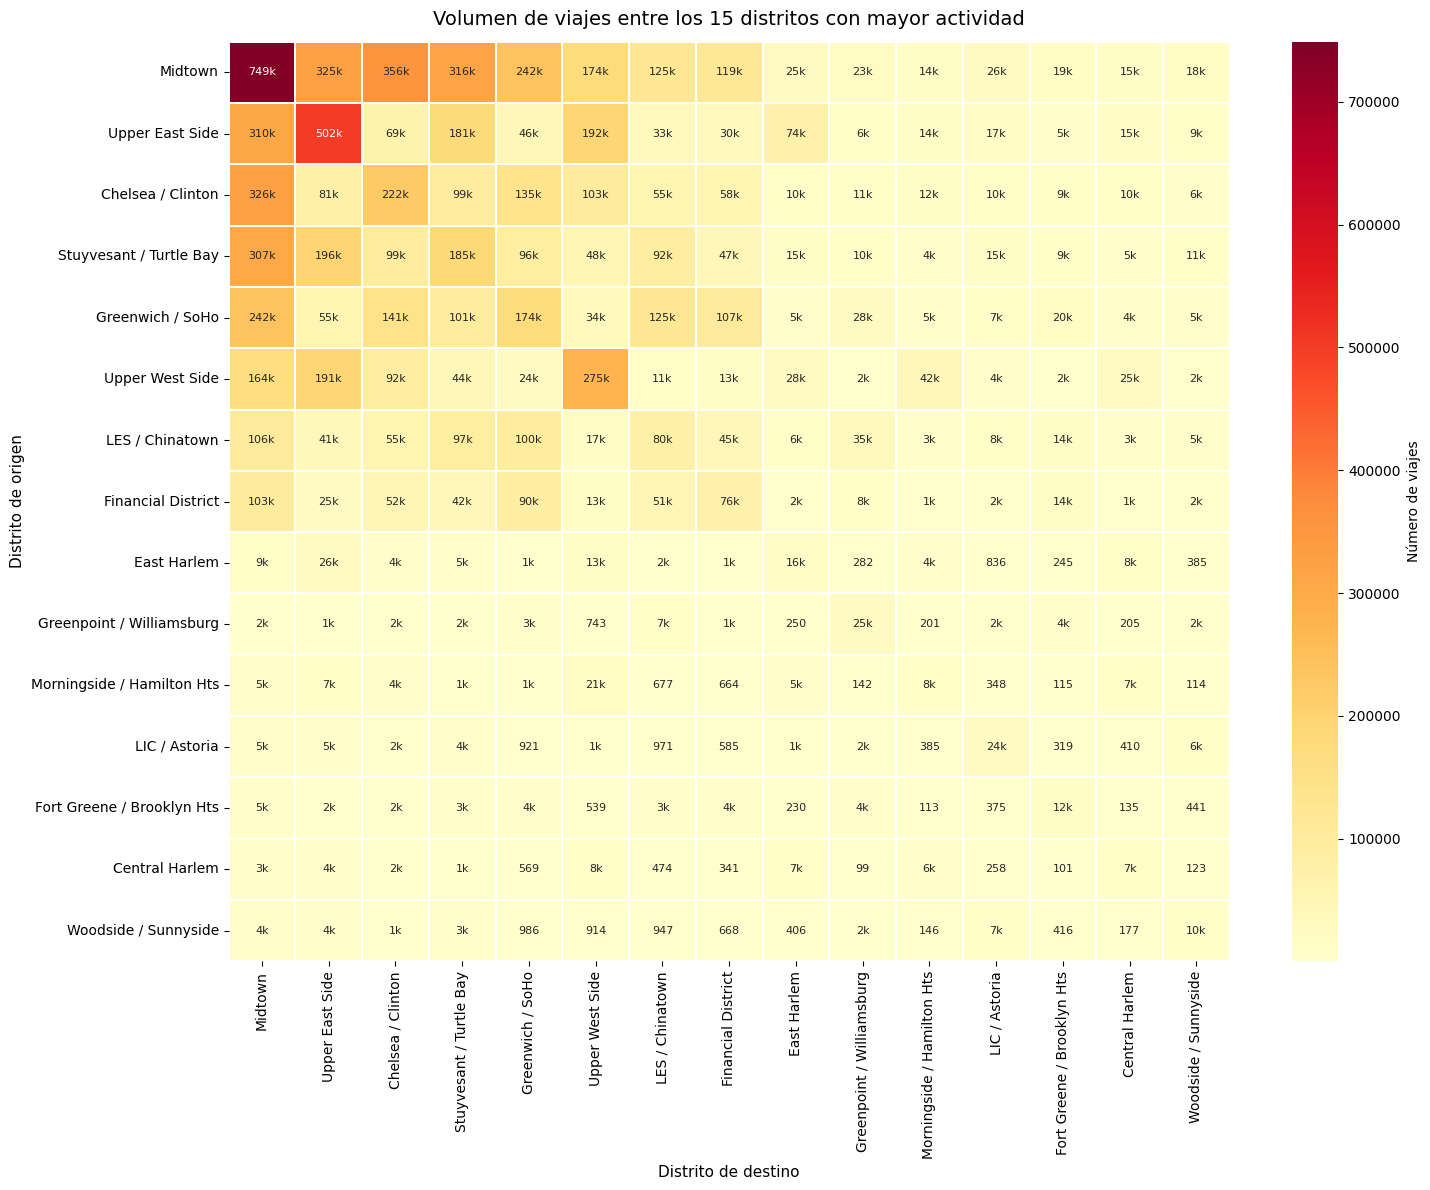

In [ ]:
# ============================================================
# DISTRITOS PRINCIPALES
# ============================================================
top_districts = (
    district_activity_pd
    .head(15)['pickup_district']
    .tolist()
)

# ============================================================
# MATRIZ ORIGEN-DESTINO
# ============================================================
origin_destination_df = (
    spatial_analysis_df
    .filter(
        F.col('pickup_district').isin(top_districts)
        & F.col('dropoff_district').isin(top_districts)
    )
    .groupBy('pickup_district')
    .pivot('dropoff_district', top_districts)
    .count()
)

origin_destination_pd = (
    origin_destination_df
    .toPandas()
    .set_index('pickup_district')
    .reindex(index=top_districts, columns=top_districts)
    .fillna(0)
)

# ============================================================
# FLUJOS ORIGEN-DESTINO · VOLUMEN ABSOLUTO
# ============================================================
origin_destination_plot_pd = origin_destination_pd.rename(
    index=DISTRICT_LABELS, columns=DISTRICT_LABELS
)

fig_od_volume, _ = plot_origin_destination_heatmap(
    origin_destination_plot_pd,
    title=('Volumen de viajes entre los 15 distritos con mayor actividad')
)

_ = save_figure(fig_od_volume, '14_origin_destination_volume', images_dir)

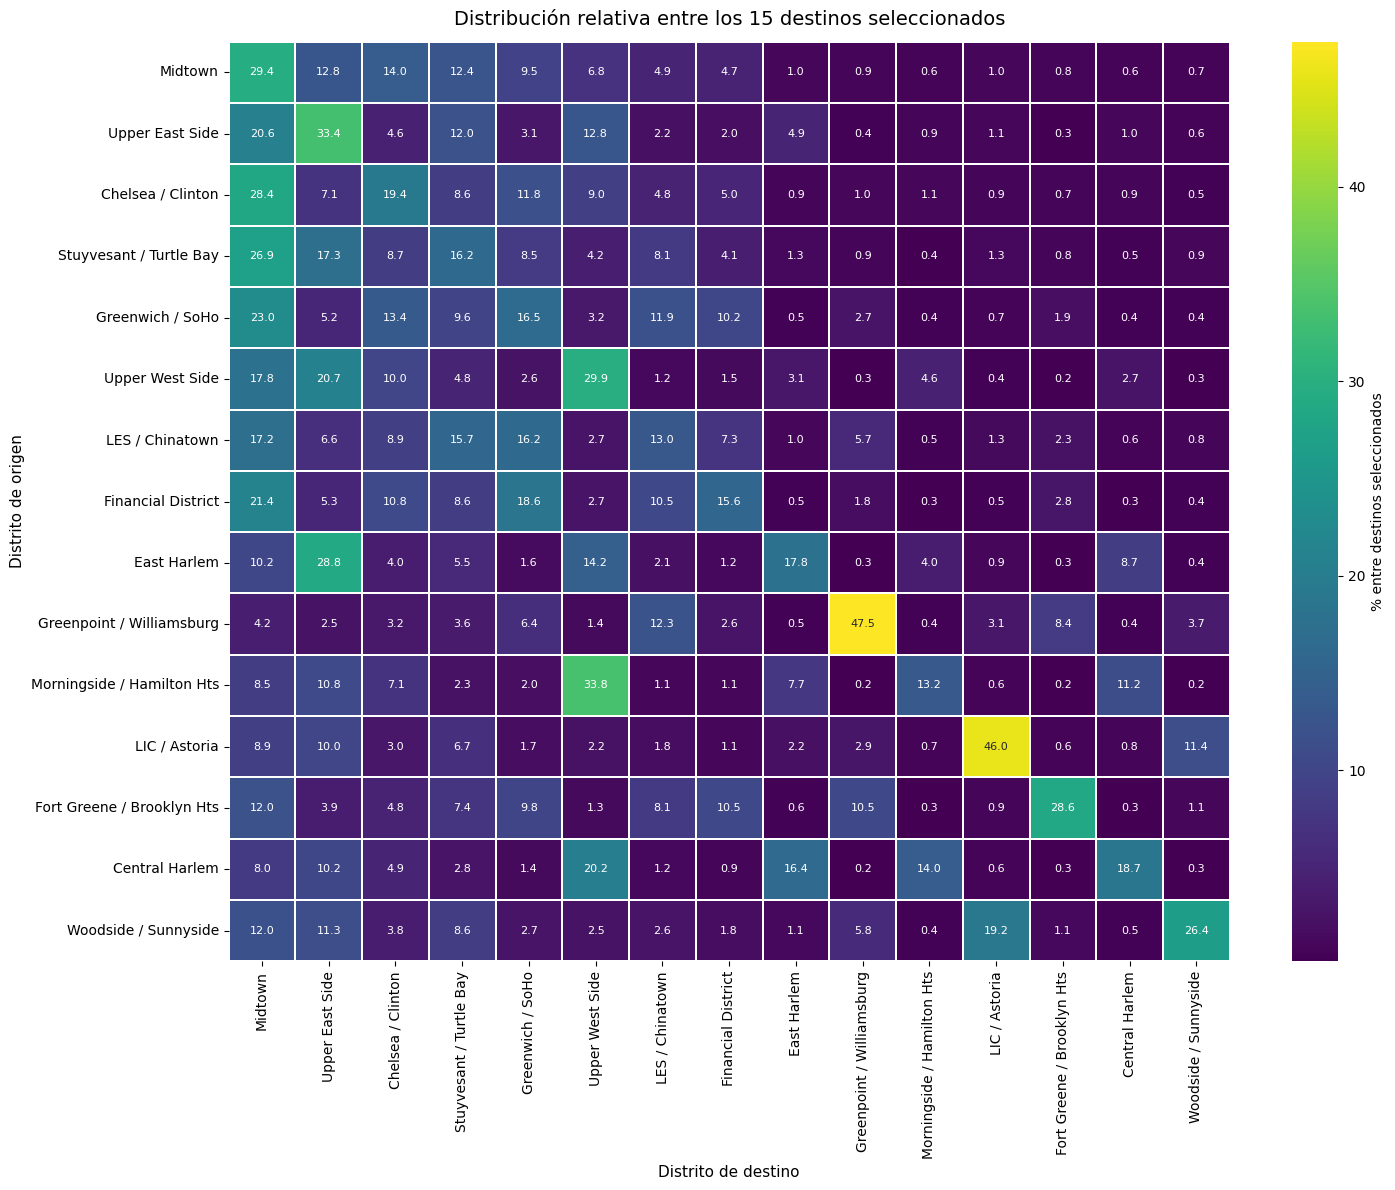

In [ ]:
# ============================================================
# FLUJOS ORIGEN-DESTINO · DISTRIBUCIÓN
# ============================================================
fig_od_relative, _ = plot_origin_destination_heatmap(
    origin_destination_plot_pd,
    title=('Distribución relativa entre los 15 destinos seleccionados'),
    normalize=True
)

_ = save_figure(fig_od_relative, '15_origin_destination_relative', images_dir)

#### Estructura de los principales flujos

La matriz origen-destino muestra una fuerte concentración de desplazamientos dentro del núcleo de Manhattan.

El flujo interno **Midtown → Midtown** destaca como el de mayor volumen entre los distritos representados, mientras que la diagonal de la matriz es especialmente visible en varios territorios, indicando que una parte relevante de los viajes comienza y termina dentro del mismo distrito.

La representación normalizada aporta una lectura complementaria al permitir comparar la estructura de destinos independientemente del volumen total generado por cada origen.

Los porcentajes deben interpretarse exclusivamente dentro del conjunto de los **15 destinos representados**, no respecto al total de destinos posibles.

La primera matriz describe la **magnitud absoluta de los flujos**, mientras que la segunda permite comparar su **estructura relativa**.

## 12. Arquitectura, rendimiento y ejecución Spark en Databricks

### 12.1. Estrategia de reutilización y materialización

El pipeline reutiliza varios resultados intermedios cuyo recálculo implicaría volver a ejecutar transformaciones sobre el dataset distribuido.

En la implementación local se utilizó `cache()` de forma selectiva sobre algunos DataFrames reutilizados. En esta implementación sobre **Databricks Free Edition con compute Serverless**, las operaciones de caché y persistencia en memoria se mantienen documentadas pero desactivadas.

La estrategia de reutilización se basa, en su lugar, en la **materialización del dataset analítico depurado en formato Parquet** dentro de un Unity Catalog Volume.

Este checkpoint separa dos fases del pipeline:

- **preparación y calidad de datos**, ejecutadas a partir del CSV original;
- **análisis estadístico, temporal y geoespacial**, ejecutado a partir del Parquet depurado y validado.

De este modo, `analysis_trips_df` constituye la fuente distribuida principal para las fases analíticas posteriores y evita depender del recálculo completo del linaje desde el CSV original.

Los resultados agregados de menor tamaño —como `stats_df`, `counts_and_distances_df` o `spatial_analysis_df`— se mantienen como DataFrames de Spark sin persistencia explícita en memoria.

In [ ]:
# ============================================================
# ESTRATEGIA DE REUTILIZACIÓN DEL PIPELINE
# ============================================================
execution_strategy_pd = pd.DataFrame({
    'Elemento': [
        'Dataset analítico principal',
        'Estadísticos por hora y día',
        'Agregación temporal',
        'Dataset espacial'
    ],
    'DataFrame': [
        'analysis_trips_df',
        'stats_df',
        'counts_and_distances_df',
        'spatial_analysis_df'
    ],
    'Implementación local': [
        'cache()',
        'cache()',
        'cache()',
        'cache()'
    ],
    'Databricks Serverless': [
        'Checkpoint Parquet',
        'Sin caché',
        'Sin caché',
        'Sin caché'
    ],
    'Estrategia': [
        'Relectura del dataset depurado materializado',
        'Reutilización directa del DataFrame agregado',
        'Reutilización directa del DataFrame agregado',
        'Reutilización directa de la proyección territorial'
    ]
}).set_index('Elemento')


# ============================================================
# VALIDACIÓN DEL CHECKPOINT ANALÍTICO
# ============================================================
checkpoint_ok = (parquet_rows == 11_488_991)

analysis_source_ok = (analysis_trips_df is cleaned_parquet_df)

assert checkpoint_ok
assert analysis_source_ok

_ = save_table(execution_strategy_pd, '10_execution_strategy', tables_dir)

execution_strategy_pd

,DataFrame,Implementación local,Databricks Serverless,Estrategia
Elemento,,,,
Dataset analítico principal,analysis_trips_df,cache(),Checkpoint Parquet,Relectura del dataset depurado materializado
Estadísticos por hora y día,stats_df,cache(),Sin caché,Reutilización directa del DataFrame agregado
Agregación temporal,counts_and_distances_df,cache(),Sin caché,Reutilización directa del DataFrame agregado
Dataset espacial,spatial_analysis_df,cache(),Sin caché,Reutilización directa de la proyección territo...


#### Estrategia adoptada

La versión Databricks no intenta reproducir artificialmente el benchmark de caché de la implementación local.

La comparación de tiempos realizada localmente evaluaba específicamente el efecto de reutilizar un DataFrame materializado mediante `cache()`, por lo que no sería metodológicamente equivalente trasladar ese resultado a un entorno Serverless con una estrategia de ejecución diferente.

En su lugar, la versión cloud utiliza como frontera de materialización el **checkpoint Parquet validado**, que permite desacoplar la fase de preparación y depuración de las fases analíticas posteriores.

### 12.2. Particiones, transformaciones narrow/wide y ejecución distribuida

Spark procesa los DataFrames mediante particiones distribuidas.

Las operaciones como `filter`, `select` o `withColumn` son principalmente transformaciones **narrow**: cada partición puede procesarse sin necesitar datos procedentes de otras particiones.

En cambio, operaciones como `groupBy`, `pivot`, `orderBy` y determinados `join` pueden requerir una redistribución de datos entre particiones (**shuffle**) y se comportan como transformaciones **wide**.

Las transformaciones son *lazy*: construyen el linaje y el plan de ejecución, pero el procesamiento no se materializa hasta que aparece una acción. En este notebook, operaciones como `count()`, `first()`, `toPandas()` o `write` desencadenan **jobs**, la ejecución del plan.

Cada job se divide en **stages**, y cada stage ejecuta múltiples **tasks**, normalmente una por partición procesada. Las operaciones que requieren shuffle suelen introducir una frontera entre stages.

En Databricks Serverless el particionado y la ejecución pueden verse además afectados por las decisiones tomadas por el motor durante la ejecución. Por este motivo no se reutilizan como referencia los números de particiones obtenidos en la implementación local.

En su lugar, se inspeccionan la configuración activa de Spark y las particiones observadas en tiempo de ejecución sobre el checkpoint Parquet que sirve como fuente del análisis.

In [ ]:
# ============================================================
# CONFIGURACIÓN DE EJECUCIÓN SPARK
# ============================================================
shuffle_partitions = spark.conf.get('spark.sql.shuffle.partitions')

try:
    adaptive_enabled = spark.conf.get('spark.sql.adaptive.enabled')
except Exception:
    adaptive_enabled = 'no disponible en Serverless'


# ============================================================
# PARTICIONES OBSERVADAS EN EL CHECKPOINT ANALÍTICO
# ============================================================
analysis_partition_ids_pd = (
    analysis_trips_df
    .select(F.spark_partition_id().alias('partition_id'))
    .distinct()
    .orderBy('partition_id')
    .toPandas()
)

analysis_partition_count = len(analysis_partition_ids_pd)


# ============================================================
# RESUMEN
# ============================================================
runtime_partition_summary_pd = pd.DataFrame({
    'Indicador': [
        'Particiones observadas · analysis_trips_df',
        'spark.sql.shuffle.partitions',
        'Adaptive Query Execution'
    ],
    'Resultado': [
        analysis_partition_count,
        shuffle_partitions,
        adaptive_enabled
    ]
}).set_index('Indicador')

_ = save_table(runtime_partition_summary_pd, '11_runtime_partitions', tables_dir)

runtime_partition_summary_pd

,Resultado
Indicador,
Particiones observadas · analysis_trips_df,8
spark.sql.shuffle.partitions,auto
Adaptive Query Execution,no disponible en Serverless


In [ ]:
# ============================================================
# OPERACIONES DISTRIBUIDAS UTILIZADAS EN EL PIPELINE
# ============================================================
execution_model_pd = pd.DataFrame({
    'Operación': [
        'filter',
        'select',
        'withColumn',
        'groupBy',
        'pivot',
        'orderBy',
        'Spatial join + broadcast',
        'count / first',
        'toPandas',
        'write'
    ],
    'Categoría': [
        'Transformación narrow',
        'Transformación narrow',
        'Transformación narrow',
        'Transformación wide',
        'Transformación wide',
        'Transformación wide',
        'Join distribuido',
        'Acción',
        'Acción',
        'Acción'
    ],
    'Efecto principal': [
        'Procesamiento independiente por partición',
        'Proyección de columnas',
        'Transformación por partición',
        'Agrupación y posible shuffle',
        'Redistribución para construir la matriz',
        'Ordenación global y posible shuffle',
        'Broadcast de la tabla territorial pequeña',
        'Materializa el cálculo solicitado',
        'Ejecuta Spark y traslada el resultado al driver',
        'Materializa y persiste el DataFrame'
    ]
}).set_index('Operación')

execution_model_pd

,Categoría,Efecto principal
Operación,,
filter,Transformación narrow,Procesamiento independiente por partición
select,Transformación narrow,Proyección de columnas
withColumn,Transformación narrow,Transformación por partición
groupBy,Transformación wide,Agrupación y posible shuffle
pivot,Transformación wide,Redistribución para construir la matriz
orderBy,Transformación wide,Ordenación global y posible shuffle
Spatial join + broadcast,Join distribuido,Broadcast de la tabla territorial pequeña
count / first,Acción,Materializa el cálculo solicitado
toPandas,Acción,Ejecuta Spark y traslada el resultado al driver


#### Modelo de ejecución observado

El checkpoint Parquet continúa procesándose como un DataFrame distribuido. El número de particiones observado corresponde a la ejecución actual y no se considera una propiedad fija del dataset.

La configuración adaptativa no se consulta directamente, ya que el entorno Serverless no expone `spark.sql.adaptive.enabled` mediante `spark.conf`.

Las transformaciones *narrow* permiten mantener el procesamiento dentro de las particiones existentes, mientras que las agregaciones, operaciones `pivot`, ordenaciones y determinados joins pueden requerir redistribución de datos.

En los spatial joins se utiliza `broadcast` sobre los 59 polígonos territoriales. De esta forma, la relación pequeña se distribuye para evitar redistribuir innecesariamente el DataFrame principal de millones de viajes.

La ejecución mantiene además el carácter *lazy* de Spark: las transformaciones construyen el plan y las acciones provocan su materialización.

### 12.3. Spark SQL y plan de ejecución

Spark SQL permite trabajar sobre los mismos DataFrames distribuidos mediante dos interfaces complementarias: la API estructurada de DataFrames y consultas SQL.

Para mostrar esta equivalencia se registra temporalmente el dataset analítico como una vista SQL. La vista no genera una nueva copia física de los datos, sino que permite referenciar el mismo DataFrame mediante sintaxis SQL durante la sesión actual.

La consulta resume los viajes por día de la semana y calcula:

- número de viajes;
- distancia media;
- distancia mediana;
- percentil 99 de la distancia;
- velocidad media;
- velocidad mediana;
- percentil 99 de la velocidad.

A diferencia de la implementación local de referencia, esta consulta se ejecuta sobre el **dataset depurado y materializado en Parquet**. Por tanto, las medias dejan de estar dominadas por los valores extremos identificados durante el diagnóstico inicial.

Finalmente se inspecciona el plan físico generado por Spark. Esto permite relacionar la consulta declarativa con las operaciones distribuidas que Catalyst y el motor de ejecución utilizan internamente.

In [ ]:
# ============================================================
# VISTA TEMPORAL Y SPARK SQL
# ============================================================
analysis_trips_df.createOrReplaceTempView('analysis_trips')

daily_summary_sql_df = spark.sql("""
    SELECT
        day_of_week, COUNT(*) AS n_trips,

        ROUND(AVG(trip_distance), 2) AS avg_trip_distance,

        ROUND(percentile_approx(trip_distance, 0.5), 2) AS median_trip_distance,

        ROUND(percentile_approx(trip_distance,0.99), 2) AS p99_trip_distance,

        ROUND(AVG(speed), 2) AS avg_speed,

        ROUND(percentile_approx(speed, 0.5), 2) AS median_speed,

        ROUND(percentile_approx(speed, 0.99), 2) AS p99_speed

    FROM analysis_trips

    GROUP BY day_of_week

    ORDER BY CASE day_of_week
        WHEN 'lunes' THEN 1
        WHEN 'martes' THEN 2
        WHEN 'miercoles' THEN 3
        WHEN 'jueves' THEN 4
        WHEN 'viernes' THEN 5
        WHEN 'sabado' THEN 6
        WHEN 'domingo' THEN 7

    END
""")

daily_summary_sql_display_df = (
    daily_summary_sql_df.replace(to_replace=DAY_LABELS, subset=['day_of_week'])
)

daily_summary_sql_display_df.show(truncate=False)

+-----------+-------+-----------------+--------------------+-----------------+---------+------------+---------+
|day_of_week|n_trips|avg_trip_distance|median_trip_distance|p99_trip_distance|avg_speed|median_speed|p99_speed|
+-----------+-------+-----------------+--------------------+-----------------+---------+------------+---------+
|Lunes      |1197067|3.17             |1.8                 |19.0             |13.29    |11.65       |37.54    |
|Martes     |1233215|2.92             |1.78                |18.23            |12.46    |11.06       |35.8     |
|Miércoles  |1510384|2.95             |1.8                 |18.23            |12.08    |10.56       |35.05    |
|Jueves     |1953704|3.08             |1.87                |18.3             |12.44    |10.97       |36.16    |
|Viernes    |2004450|3.01             |1.8                 |18.4             |12.03    |10.48       |35.05    |
|Sábado     |2148613|2.89             |1.86                |18.1             |13.0     |11.64       |35.

In [ ]:
# ============================================================
# VALIDACIÓN DEL RESUMEN SQL
# ============================================================
sql_daily_counts_pd = (
    daily_summary_sql_df
    .select(
        'day_of_week',
        'n_trips'
    )
    .toPandas()
)

expected_daily_counts = {
    'lunes': 1_197_067,
    'martes': 1_233_215,
    'miercoles': 1_510_384,
    'jueves': 1_953_704,
    'viernes': 2_004_450,
    'sabado': 2_148_613,
    'domingo': 1_441_558
}

obtained_daily_counts = dict(
    zip(
        sql_daily_counts_pd['day_of_week'],
        sql_daily_counts_pd['n_trips']
    )
)

assert obtained_daily_counts == expected_daily_counts

assert sum(obtained_daily_counts.values()) == parquet_rows

print('Validación Spark SQL completada: recuentos diarios y total coincidentes.')

Validación Spark SQL completada: recuentos diarios y total coincidentes.


In [ ]:
# ============================================================
# PLAN DE EJECUCIÓN
# ============================================================
plan_buffer = io.StringIO()

with redirect_stdout(plan_buffer):
    daily_summary_sql_df.explain(mode='formatted')

plan_text = plan_buffer.getvalue().replace(str(cleaned_parquet_path), '<CLEANED_PARQUET>')

print(plan_text)

== Physical Plan ==
AdaptiveSparkPlan (15)
+- == Initial Plan ==
   PhotonResultStage (14)
   +- PhotonColumnarToRow (13)
      +- PhotonProject (12)
         +- PhotonSort (11)
            +- PhotonProject (10)
               +- PhotonShuffleExchangeSource (9)
                  +- PhotonShuffleMapStage (8)
                     +- PhotonShuffleExchangeSink (7)
                        +- PhotonGroupingAgg (6)
                           +- PhotonShuffleExchangeSource (5)
                              +- PhotonShuffleMapStage (4)
                                 +- PhotonShuffleExchangeSink (3)
                                    +- PhotonGroupingAgg (2)
                                       +- PhotonScan parquet  (1)


(1) PhotonScan parquet 
Output [3]: [trip_distance#10907, speed#10924, day_of_week#10925]
Location: InMemoryFileIndex [dbfs:<CLEANED_PARQUET>]
ReadSchema: struct<trip_distance:double,speed:double>

(2) PhotonGroupingAgg
Input [3]: [trip_distance#10907, speed#10924, day_of

In [ ]:
# ============================================================
# ELEMENTOS OBSERVABLES DEL PLAN
# ============================================================
plan_text_lower = plan_text.lower()

plan_features_pd = pd.DataFrame({
    'Elemento': [
        'Lectura Parquet',
        'Agregación',
        'Redistribución',
        'Ordenación',
        'Plan adaptativo',
        'Ejecución Photon'
    ],
    'Detectado': [
        'parquet' in plan_text_lower,
        'aggregate' in plan_text_lower or 'groupingagg' in plan_text_lower,
        'exchange' in plan_text_lower or 'shuffle' in plan_text_lower,
        'sort' in plan_text_lower,
        'adaptivesparkplan' in plan_text_lower,
        'photon' in plan_text_lower
    ]
}).set_index('Elemento')

_ = save_table(plan_features_pd, '12_execution_plan_features', tables_dir)
plan_features_pd

,Detectado
Elemento,
Lectura Parquet,True
Agregación,True
Redistribución,True
Ordenación,True
Plan adaptativo,True
Ejecución Photon,True


#### Ejecución en Databricks Serverless

La consulta SQL se ejecuta sobre el mismo dataset distribuido utilizado por la API DataFrame y reproduce los recuentos diarios obtenidos previamente en el pipeline.

El plan físico muestra una ejecución completamente compatible con **Photon**, incluyendo lectura columnar del checkpoint Parquet, agregaciones distribuidas, operaciones de shuffle y ordenación.

Aunque el parámetro `spark.sql.adaptive.enabled` no está expuesto directamente a la sesión Serverless, el plan generado contiene un `AdaptiveSparkPlan`. Por tanto, la configuración interna no se infiere a partir de `spark.conf`, sino que se documenta únicamente a partir del comportamiento observable en el plan físico.

La configuración `spark.sql.shuffle.partitions` aparece como `auto`, mientras que el plan inicial muestra intercambios con **348 particiones**. Este valor pertenece al plan generado para esta ejecución y no se considera una propiedad fija del pipeline.

### 12.4. Persistencia de resultados derivados en formato Parquet

Además de materializar el dataset analítico completo como checkpoint, Spark permite persistir resultados derivados obtenidos durante el análisis.

Para comprobar este flujo se utiliza el resumen diario generado mediante Spark SQL. El resultado contiene únicamente **siete registros**, pero conserva un esquema analítico con recuentos, medias, medianas y percentiles.

El DataFrame se escribe en formato **Parquet** dentro del Unity Catalog Volume y se vuelve a cargar mediante `DataFrameReader`.

Esta operación representa un caso diferente al checkpoint del punto 6: no se persiste nuevamente el dataset completo, sino un **producto analítico derivado** que puede reutilizarse independientemente del cálculo que lo generó.

In [ ]:
# ============================================================
# ESCRITURA EN PARQUET
# ============================================================
# La escritura materializa el DataFrame y persiste el resultado
# en un formato columnar que conserva el esquema
daily_summary_parquet_path = databricks_output_dir / 'daily_summary_parquet'

(
    daily_summary_sql_df
    .write
    .mode('overwrite')
    .parquet(str(daily_summary_parquet_path))
)


# ============================================================
# LECTURA DEL RESULTADO
# ============================================================
# La relectura comprueba que el resultado puede incorporarse
# nuevamente al pipeline como DataFrame de Spark
daily_summary_parquet_df = (
    spark
    .read
    .parquet(str(daily_summary_parquet_path))
)


# ============================================================
# VALIDACIÓN DE LA LECTURA
# ============================================================
daily_summary_parquet_rows = daily_summary_parquet_df.count()

daily_summary_columns_ok = (
    daily_summary_parquet_df.columns == daily_summary_sql_df.columns
)

daily_summary_types_ok = (
    dict(daily_summary_parquet_df.dtypes) == dict(daily_summary_sql_df.dtypes)
)

assert daily_summary_parquet_rows == 7

assert daily_summary_columns_ok

assert daily_summary_types_ok

daily_summary_parquet_df.printSchema()

print(f'Registros releídos desde Parquet: {daily_summary_parquet_rows}')

root
 |-- day_of_week: string (nullable = true)
 |-- n_trips: long (nullable = true)
 |-- avg_trip_distance: double (nullable = true)
 |-- median_trip_distance: double (nullable = true)
 |-- p99_trip_distance: double (nullable = true)
 |-- avg_speed: double (nullable = true)
 |-- median_speed: double (nullable = true)
 |-- p99_speed: double (nullable = true)

Registros releídos desde Parquet: 7


#### Resultado de la materialización

La escritura y posterior lectura conserva el esquema completo del resumen diario y sus siete registros.

El pipeline demuestra así dos niveles complementarios de persistencia:

1. un **checkpoint analítico** con los millones de viajes depurados, utilizado como fuente de las fases posteriores;
2. un **resultado derivado** de pequeño tamaño, generado mediante Spark SQL y almacenado para su posible reutilización independiente.

Ambos utilizan Parquet y el almacenamiento asociado al entorno Databricks, pero responden a funciones diferentes dentro de la arquitectura del pipeline.

### 12.5. Portabilidad local vs Databricks

El pipeline se ha desarrollado en dos entornos de ejecución diferentes manteniendo una lógica analítica común.

La implementación local utiliza **Spark 4.1** junto con **Apache Sedona 1.9** para el procesamiento geoespacial. Esta versión permite controlar directamente la creación de la sesión Spark, las dependencias Java, la configuración de particiones y la persistencia mediante `cache()`.

La implementación cloud utiliza **Databricks Serverless con Spark 4.2**, almacenamiento mediante **Unity Catalog Volumes** y funciones geoespaciales `ST_*` nativas de la plataforma. No requiere Apache Sedona para realizar los spatial joins.

Aunque ambas implementaciones comparten el mismo esquema de preparación, agregación y análisis, existen diferencias deliberadas en:

- configuración y gestión de la sesión Spark;
- acceso y persistencia de los datos;
- motor geoespacial;
- estrategia de reutilización de DataFrames;
- gestión de particiones;
- optimizaciones disponibles en el entorno de ejecución.

La portabilidad del proyecto se basa, por tanto, en conservar la **lógica del pipeline y sus resultados analíticos**, no en reproducir de forma idéntica la infraestructura de cada plataforma.

In [ ]:
# ============================================================
# COMPARACIÓN DE IMPLEMENTACIONES
# ============================================================
portability_summary_pd = pd.DataFrame({
    'Aspecto': [
        'Python',
        'Apache Spark',
        'Procesamiento geoespacial',
        'Sesión Spark',
        'Datos de entrada',
        'Persistencia analítica',
        'Caché explícita',
        'Particionado shuffle',
        'Ejecución adaptativa',
        'Motor observado en Spark SQL'
    ],
    'Local': [
        '3.11',
        '4.1',
        'Apache Sedona 1.9',
        'Configurada manualmente',
        'Sistema de archivos local',
        'Parquet local',
        'Sí',
        '8',
        'Gestionable desde Spark',
        'Spark'
    ],
    'Databricks': [
        '3.12',
        '4.2',
        'Funciones ST_* nativas',
        'Gestionada por Serverless',
        'Unity Catalog Volume',
        'Parquet en Volume',
        'Desactivada',
        'auto',
        'No expuesta directamente; AdaptiveSparkPlan observado',
        'Photon en la consulta SQL analizada'
    ]
}).set_index('Aspecto')

_ = save_table(portability_summary_pd, '13_portability_summary', tables_dir)

portability_summary_pd

,Local,Databricks
Aspecto,,
Python,3.11,3.12
Apache Spark,4.1,4.2
Procesamiento geoespacial,Apache Sedona 1.9,Funciones ST_* nativas
Sesión Spark,Configurada manualmente,Gestionada por Serverless
Datos de entrada,Sistema de archivos local,Unity Catalog Volume
Persistencia analítica,Parquet local,Parquet en Volume
Caché explícita,Sí,Desactivada
Particionado shuffle,8,auto
Ejecución adaptativa,Gestionable desde Spark,No expuesta directamente; AdaptiveSparkPlan ob...


#### Análisis de portabilidad

Los resultados obtenidos muestran que el pipeline puede trasladarse entre un entorno Spark local y Databricks manteniendo la misma estructura analítica general.

La adaptación no consiste en reproducir literalmente cada detalle de infraestructura. Las diferencias entre plataformas se aprovechan de forma explícita: Apache Sedona proporciona la capacidad geoespacial en local, mientras que Databricks utiliza funciones espaciales nativas; la implementación local reutiliza DataFrames mediante caché, mientras que la versión Serverless utiliza un checkpoint Parquet validado.

La ejecución de Spark SQL en Databricks muestra además una planificación adaptativa y compatibilidad completa con Photon para la consulta analizada.

De este modo, las dos versiones constituyen implementaciones equivalentes desde el punto de vista del análisis, pero adaptadas a las características reales de cada entorno de ejecución.

## 13. Resultados principales

El pipeline procesa inicialmente **11.489.716 viajes** de taxis amarillos correspondientes a enero de 2015. Tras evaluar los valores extremos de distancia y velocidad, se aplican los criterios seleccionados de **80 mph de velocidad máxima** y **50 millas de distancia máxima**.

La depuración elimina únicamente **725 registros**, equivalentes al **0,0063 %** del dataset de referencia, y conserva **11.488.991 viajes** como dataset analítico.

A pesar de afectar a una proporción mínima de observaciones, la depuración corrige una distorsión muy elevada de las medias:

- la distancia media pasa de aproximadamente **14,07 a 3,03 millas**;
- la velocidad media pasa de aproximadamente **63,17 a 12,79 mph**.

La parte representativa de las distribuciones permanece prácticamente inalterada:

- distancia mediana: **1,83 millas**;
- velocidad mediana: **11,33 mph**;
- P99 de distancia: **18,41 → 18,40 millas**;
- P99 de velocidad: **36,19 → 36,16 mph**;
- la variación relativa máxima observada entre los perfiles P50, P95, P99 y P99,9 es de aproximadamente **0,52 %**.

El análisis temporal mantiene los patrones identificados previamente. El volumen aumenta durante la segunda mitad de la semana y alcanza su máximo el **sábado**, con aproximadamente **2,15 millones de viajes**.

La estructura territorial también permanece estable. **Midtown** continúa siendo el distrito con mayor volumen de recogidas, con aproximadamente **2,74 millones de viajes**, y los 15 distritos principales mantienen su jerarquía tras la depuración.

El enriquecimiento geoespacial realizado mediante funciones `ST_*` nativas de Databricks permite asignar distrito a aproximadamente el **92,83 %** de los puntos de recogida y al **95,11 %** de los puntos de destino. En alrededor del **89,81 %** de los viajes se dispone simultáneamente de distrito de origen y destino.

El dataset depurado se materializa como checkpoint en formato **Parquet**, conservando **11.488.991 registros y 23 columnas**. Esta materialización constituye la fuente de las fases estadísticas, temporales y geoespaciales posteriores.

La ejecución de Spark SQL reproduce los recuentos diarios obtenidos mediante la API DataFrame. El plan físico generado por Databricks muestra lectura columnar desde Parquet, agregaciones distribuidas, operaciones de shuffle, ordenación, un `AdaptiveSparkPlan` y compatibilidad completa de la consulta analizada con **Photon**.

Los resultados describen exclusivamente el comportamiento observado en el dataset y periodo analizados y no deben interpretarse como una caracterización general de toda la movilidad de Nueva York.

In [ ]:
# ============================================================
# RESUMEN FINAL DE RESULTADOS
# ============================================================
busiest_day_row = daily_trips_pd.loc[daily_trips_pd['n_trips_millions'].idxmax()]

top_district_row = district_activity_pd.iloc[0]

top_district_name = DISTRICT_LABELS.get(
    top_district_row['pickup_district'],
    top_district_row['pickup_district']
)

joint_coverage = float(spatial_coverage_pd.loc['Pickup y dropoff', 'Cobertura (%)'])


results_summary_pd = pd.DataFrame({
    'Indicador': [
        'Viajes de referencia',
        'Viajes analíticos',
        'Registros eliminados',
        'Porcentaje eliminado',
        'Comportamiento típico',
        'Distancia media',
        'Velocidad media',
        'Variación máxima P50–P99.9',
        'Día con mayor volumen',
        'Distrito con mayor actividad',
        'Cobertura espacial conjunta',
        'Checkpoint analítico',
        'Procesamiento geoespacial',
        'Ejecución Spark SQL'
    ],
    'Resultado': [
        f'{trip_count:,}',
        f'{parquet_rows:,}',
        f'{removed_trip_count:,}',
        f'{removed_pct:.4f} %',
        (
            f"{comparison_stats_pd.loc['Depurado', 'median_distance']:.2f} mi · "
            f"{comparison_stats_pd.loc['Depurado', 'median_speed']:.2f} mph"
        ),
        (
            f"{comparison_stats_pd.loc['Referencia', 'avg_distance']:.2f} → "
            f"{comparison_stats_pd.loc['Depurado', 'avg_distance']:.2f} mi"
        ),
        (
            f"{comparison_stats_pd.loc['Referencia', 'avg_speed']:.2f} → "
            f"{comparison_stats_pd.loc['Depurado', 'avg_speed']:.2f} mph"
        ),
        f'{max_percentile_profile_change_pct:.2f} %',
        (
            f"{DAY_LABELS[busiest_day_row['day_of_week']]} · "
            f"{busiest_day_row['n_trips_millions']:.2f} M"
        ),
        (
            f"{top_district_name} · {int(top_district_row['total_week']):,}"
        ),
        f'{joint_coverage:.2f} %',
        f'Parquet · {parquet_rows:,} viajes · {len(analysis_trips_df.columns)} columnas',
        'Funciones ST_* nativas de Databricks',
        'Photon · AdaptiveSparkPlan observado'
    ]
}).set_index('Indicador')

_ = save_table(results_summary_pd, '14_results_summary', tables_dir)

results_summary_pd

,Resultado
Indicador,
Viajes de referencia,"11,489,716"
Viajes analíticos,"11,488,991"
Registros eliminados,725
Porcentaje eliminado,0.0063 %
Comportamiento típico,1.83 mi · 11.33 mph
Distancia media,14.07 → 3.03 mi
Velocidad media,63.17 → 12.79 mph
Variación máxima P50–P99.9,0.52 %
Día con mayor volumen,Sábado · 2.15 M


## 14. Conclusiones

Este notebook integra en **Databricks Serverless** el pipeline completo de análisis Big Data desarrollado sobre los viajes de taxi amarillo de Nueva York correspondientes a enero de 2015. La implementación combina preparación distribuida de datos, evaluación de calidad, depuración de valores extremos, análisis estadístico y temporal, procesamiento geoespacial, persistencia en formato Parquet y revisión del comportamiento de Spark en un entorno cloud.

El procesamiento parte de **11.489.716 viajes**. El diagnóstico inicial muestra que la distribución central de las variables es estable —con una distancia mediana de **1,83 millas** y una velocidad mediana de **11,33 mph**—, pero también identifica un número extremadamente reducido de observaciones capaces de distorsionar de forma intensa las medias.

La evaluación de diferentes criterios conduce a seleccionar límites de **80 mph para la velocidad media del trayecto** y **50 millas para la distancia recorrida**. Su aplicación conjunta elimina únicamente **725 registros**, equivalentes al **0,0063 %** del dataset de referencia, y conserva **11.488.991 viajes** como dataset analítico.

El impacto estadístico de esta depuración es muy significativo sobre las medias: la distancia media pasa de aproximadamente **14,07 a 3,03 millas** y la velocidad media de **63,17 a 12,79 mph**. Sin embargo, las medianas permanecen invariantes y los percentiles representativos hasta **P99,9** apenas se modifican. La variación relativa máxima observada entre P50, P95, P99 y P99,9 es de aproximadamente **0,52 %**.

Este comportamiento confirma que los criterios seleccionados actúan principalmente sobre observaciones situadas muy lejos de la parte representativa de las distribuciones. Los límites deben interpretarse como **decisiones analíticas de depuración** y no como una demostración de que cada registro excluido sea necesariamente erróneo de forma individual.

El análisis temporal mantiene los patrones observados en el dataset de referencia. La actividad aumenta durante la segunda mitad de la semana y alcanza su máximo el **sábado**, con aproximadamente **2,15 millones de viajes**. Las distribuciones por hora y día muestran además diferencias en distancia y velocidad coherentes con los distintos niveles de actividad.

La estructura territorial permanece igualmente estable. Los **15 distritos con mayor volumen de recogidas conservan su jerarquía**, y **Midtown** continúa siendo el principal distrito de origen, con **2.742.740 recogidas** en el dataset depurado.

El procesamiento geoespacial se realiza mediante las funciones `ST_*` nativas de Databricks. A partir de millones de coordenadas individuales, los spatial joins permiten asignar un distrito aproximadamente al **92,83 %** de los puntos de recogida y al **95,11 %** de los puntos de destino, alcanzando una cobertura conjunta del **89,81 %**. Esta transformación permite construir posteriormente agregaciones territoriales y matrices origen-destino interpretables.

La persistencia constituye una parte explícita de la arquitectura del pipeline. El dataset depurado se materializa en formato **Parquet** dentro de un Unity Catalog Volume y se utiliza posteriormente como fuente analítica para las fases estadísticas, temporales y espaciales. La relectura conserva los **11.488.991 registros y 23 columnas**, así como los recuentos diarios y el esquema necesarios para continuar el procesamiento distribuido.

Esta estrategia sustituye en la versión Serverless a la reutilización mediante `cache()` utilizada en la implementación local. La adaptación mantiene así la lógica analítica del proyecto pero utiliza mecanismos compatibles con las características reales de cada entorno de ejecución.

Desde el punto de vista de la arquitectura Spark, el notebook incorpora transformaciones narrow y wide, agregaciones distribuidas, `pivot`, broadcast joins, Spark SQL, persistencia Parquet y análisis del plan físico de ejecución. La configuración `spark.sql.shuffle.partitions` aparece gestionada automáticamente por Databricks y determinados parámetros internos no se encuentran expuestos directamente a la sesión.

La inspección del plan físico muestra, no obstante, un `AdaptiveSparkPlan` y confirma que la consulta SQL analizada se ejecuta completamente mediante **Photon**. El plan incluye lectura columnar desde Parquet, agregaciones distribuidas, operaciones de shuffle y ordenación, evidenciando cómo una consulta declarativa se traduce en operaciones físicas dentro de la plataforma.

El proyecto mantiene deliberadamente separados el procesamiento distribuido y las tareas locales de presentación. Los millones de registros permanecen en Spark, mientras que únicamente resultados agregados o muestras reducidas se trasladan a Pandas, GeoPandas, Folium o Matplotlib para su representación.

La comparación con la implementación local muestra que la portabilidad no implica reproducir exactamente la infraestructura. La versión local utiliza **Spark 4.1 y Apache Sedona 1.9**, mientras que Databricks utiliza **Spark 4.2, funciones geoespaciales nativas, Unity Catalog Volumes, Serverless y Photon**. La equivalencia se mantiene en la lógica del pipeline y en sus resultados analíticos, adaptando cada implementación a las capacidades de su plataforma.

En conjunto, el trabajo demuestra que una etapa explícita de calidad de datos puede corregir distorsiones estadísticas muy importantes sin alterar de forma significativa la distribución central, los percentiles representativos, los patrones temporales ni la estructura territorial. Al mismo tiempo, la implementación muestra cómo trasladar un flujo Spark reproducible desde un entorno local a Databricks manteniendo procesamiento distribuido, persistencia, análisis geoespacial y validación de resultados.

Las conclusiones corresponden exclusivamente al dataset y al periodo estudiados y no implican que los mismos criterios de depuración o patrones de movilidad deban generalizarse automáticamente a otros periodos o fuentes de datos.